# Práctica · Detección de fraude en transacciones bancarias

**Máster MIAX · Módulo de Detección de Anomalías**

**Grupo:** Oscar Romero Quincoces · Fernando Dapena Tauste · Daniel Garcia Lopez

**Repositorio con todo el trabajo:** [github.com/Romequinco/fraud-detection-banking](https://github.com/Romequinco/fraud-detection-banking). Los notebooks `01`–`05` contienen la exploración completa (más de 500 celdas); el registro de decisiones está en `docs/DECISIONES.md`.

**Entregables:** este notebook y `scores_produccion.csv`: una sola columna **sin cabecera** con el score de cada transacción de producción, una fila por transacción y en su orden (mayor score = más probabilidad de fraude). Métrica: **AUPR** (`average_precision_score`).

**Cómo está hecho este notebook.** Es la **consolidación** de los cinco notebooks de trabajo. Se ejecuta de principio a fin **solo con los dos CSV originales** (`credit_card_construction.csv` y `credit_card_production.csv`), sin depender de ningún fichero intermedio. Cada bloque vuelve a ejecutar los experimentos que justifican sus decisiones y recoge en tablas, con sus cifras, el resto de lo que probamos en los notebooks de trabajo. Cada apartado sigue el orden **pregunta → resultado → conclusión → impacto**.

**Resultado final.** Una **mezcla por rangos de cuatro clasificadores supervisados** (XGBoost, CatBoost, LightGBM y Random Forest): **0,866 de AUPR en validación cruzada** (15 folds) y **0,822 en el test interno**, frente a 0,567 del GMM del notebook de partida.

| Bloque | Pregunta | Notebook de trabajo |
|---|---|---|
| 0. Preparación | ¿Cómo se reparten y preparan los datos sin fugas? | 01 Parte II |
| 1. Datos y EDA | ¿Cómo es el fraude en estos datos? | 01 Parte I |
| 2. Enfoque no supervisado | ¿Hasta dónde llega la detección de anomalías pura? | 02 |
| 3. Enfoque supervisado | ¿Cuánto ayudan las 295 etiquetas de fraude? | 03 |
| 4. Híbrido, optimización y modelo final | ¿Qué combinación ordena mejor el fraude? | 04 y 05 |
| 5. Fichero de producción | Reentrenar el modelo final y generar el entregable | 05 §11 |
| 6. Reflexión final | ¿Qué hemos aprendido y qué esperar en producción? | — |

**Tiempo de ejecución:** unos 17 minutos en un portátil de 12 núcleos (CPU). Librerías: `numpy`, `pandas`, `scikit-learn`, `scipy`, `matplotlib`, `seaborn`, `xgboost`, `lightgbm` y `catboost`.

## 0. Preparación de los datos

**Qué hacemos y por qué.** Esta celda reproduce el preprocesado del notebook 01 (§12–§16) a partir de los CSV originales y deja disponibles las mismas variables y utilidades que usaron todos los notebooks de trabajo. Así todas las AUPR del proyecto son comparables:

1. **Split fijo del profesor:** 70 % train / 30 % test, estratificado, `random_state=42` (89 fraudes en test). El test solo se usa para confirmar al final de cada bloque.
2. **Duplicados:** hay 4.167 filas repetidas en construcción, sin conflictos de etiqueta. No se borra ninguna: las filas idénticas comparten `group_id` y nunca se separan entre entrenamiento y validación. `dup_en_train` marca las filas de test con copia exacta en train, para medir la AUPR también sin ellas.
3. **Variables nuevas, sin etiquetas:** `log1p_Amount` y `amount_freq`, el número de veces que aparece el importe exacto en construcción + producción (los fraudes repiten importes).
4. **Validación cruzada:** `StratifiedGroupKFold(5)` sobre train, agrupando duplicados: ~41 fraudes por fold. Con tan pocos fraudes, un único conjunto de validación oscilaría ±0,07 de AUPR.
5. **Escalado:** nunca se exportan variables escaladas. Cada modelo que lo necesita escala dentro de su `Pipeline`, ajustado solo con el train de cada fold.
6. **Producción:** se puntúan sus 113.923 filas en su orden original, sin filtrar ni deduplicar.

In [1]:
# ============================================================
# PREPARACIÓN AUTOCONTENIDA: solo necesita los dos CSV originales.
# Reproduce el preprocesado del 01 (§12–§16) y expone lo mismo que la celda común v2 de los notebooks 02–05.
# Uso: m = fit(modelo, X_train, y_train); report("x", score(m, X_test)); cv_aupr(modelo); save_submission(score(m, X_prod))
# ============================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone, is_classifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.options.display.max_columns = None
SEED = 42
CONST_CSV, PROD_CSV = "credit_card_construction.csv", "credit_card_production.csv"
_carpetas = [Path.cwd(), Path.cwd() / "data", Path.cwd().parent / "data"]
DATA_DIR = next((d for d in _carpetas if (d / CONST_CSV).exists() and (d / PROD_CSV).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"No encuentro {CONST_CSV} y {PROD_CSV} en: {', '.join(map(str, _carpetas))}")
OUTPUT_DIR = DATA_DIR / "output" if (DATA_DIR / "output").is_dir() else Path.cwd()

raw_const = pd.read_csv(DATA_DIR / CONST_CSV)
raw_prod = pd.read_csv(DATA_DIR / PROD_CSV).drop(columns="Class")
FEAT_RAW = [f"X{i}" for i in range(1, 21)] + ["Amount"]
assert list(raw_const.columns) == FEAT_RAW + ["Class"] and list(raw_prod.columns) == FEAT_RAW

# 1) Split fijo del notebook de partida: 70/30 estratificado, random_state=42
r_train, r_test = train_test_split(raw_const, test_size=0.3, random_state=SEED, stratify=raw_const["Class"])
es_train = raw_const.index.isin(r_train.index)
# 2) Duplicados: mismas 21 variables → mismo group_id (construcción + producción juntas); no se borra nada
h_c = pd.util.hash_pandas_object(raw_const[FEAT_RAW], index=False)
h_p = pd.util.hash_pandas_object(raw_prod[FEAT_RAW], index=False)
gid = pd.factorize(np.r_[h_c.values, h_p.values])[0]
gid_c, gid_p = gid[:len(raw_const)], gid[len(raw_const):]
en_train = set(h_c[es_train])
# 3) Variables sin estado y sin etiquetas: log1p(Amount) y frecuencia del importe exacto
freq_importe = pd.concat([raw_const.Amount, raw_prod.Amount]).value_counts()
# 4) Folds por grupo sobre train (los duplicados nunca cruzan entre entrenamiento y validación)
fold_c = np.full(len(raw_const), -1)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, iv) in enumerate(sgkf.split(r_train[FEAT_RAW], r_train["Class"], groups=gid_c[r_train.index])):
    fold_c[r_train.index[iv]] = k

def _preparar(raw, split, fold, grupos, dup):
    return raw[FEAT_RAW].assign(row_id=np.arange(len(raw)), split=split, fold=fold, group_id=grupos, dup_en_train=dup,
                                log1p_Amount=np.log1p(raw.Amount), amount_freq=raw.Amount.map(freq_importe).astype(int))

df_const = _preparar(raw_const, np.where(es_train, "train", "test"), fold_c, gid_c,
                     ~es_train & h_c.isin(en_train).to_numpy()).assign(Class=raw_const["Class"].astype(int))
df_prod = _preparar(raw_prod, "prod", -1, gid_p, h_p.isin(en_train).to_numpy())
df = pd.concat([df_const, df_prod.assign(Class=pd.NA)], ignore_index=True)   # = 01_dataset_preparado.csv
FEATURES = [f"X{i}" for i in range(1, 21)] + ["log1p_Amount", "amount_freq"]  # conjunto por defecto (D-1.2)

tr, te = df_const[df_const["split"] == "train"], df_const[df_const["split"] == "test"]
X_train, y_train, groups_train = tr[FEATURES], tr["Class"].astype(int), tr["group_id"]
X_test, y_test = te[FEATURES], te["Class"].astype(int)
X_prod = df_prod[FEATURES]
dup_test = te["dup_en_train"].to_numpy(bool)  # filas de test con copia exacta en train
# Folds → (idx_train, idx_val) posicionales sobre X_train; vale como cv= en sklearn
cv_splits = [(np.flatnonzero(tr["fold"].to_numpy() != k), np.flatnonzero(tr["fold"].to_numpy() == k)) for k in range(5)]

def make_pipe(model, scaler="standard"):
    """Escalador ('standard' | 'robust' | None) + modelo: el escalado se ajusta DENTRO de cada fold."""
    steps = {"standard": [StandardScaler()], "robust": [RobustScaler()], None: []}[scaler]
    return make_pipeline(*steps, model)

def score(model, X):
    """Mayor = más fraude. Clasificador: predict_proba[:, 1] (o decision_function). No supervisado: −score_samples."""
    if not is_classifier(model):
        return -model.score_samples(X)  # GMM: −log-verosimilitud; IF / LOF(novelty=True): −normalidad
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def fit(model, X, y):
    """Copia limpia ajustada: clasificador con (X, y); no supervisado SOLO con las normales (y == 0)."""
    y = np.asarray(y)
    return clone(model).fit(X, y) if is_classifier(model) else clone(model).fit(X[y == 0])

def metrics(y_true, scores):
    """Métrica oficial: AUPR (average_precision_score). Mayor score = más fraude."""
    return {"aupr": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores)}

def cv_aupr(model, X=X_train, y=y_train):
    """AUPR por fold sobre cv_splits. Devuelve (media, std, scores OOF alineados con X)."""
    X, y, oof, auprs = np.asarray(X, dtype=float), np.asarray(y), np.zeros(len(y)), []
    assert len(X) == len(tr), "X debe tener las filas de X_train en su orden"
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], y[it]), X[iv])
        auprs.append(average_precision_score(y[iv], oof[iv]))
    print(f"CV AUPR = {np.mean(auprs):.4f} ± {np.std(auprs):.4f}")
    return np.mean(auprs), np.std(auprs), oof

def report(name, s_test):
    """AUPR de test con y sin las filas duplicadas de train, y ROC-AUC."""
    s, y = np.asarray(s_test, dtype=float), y_test.to_numpy()
    assert len(s) == len(y), f"{len(s)} scores != {len(y)} filas de test"
    r = {"modelo": name, **metrics(y, s), "aupr_sin_dup": average_precision_score(y[~dup_test], s[~dup_test])}
    print(f"{name}: AUPR test={r['aupr']:.4f} | sin dup={r['aupr_sin_dup']:.4f} | ROC-AUC={r['roc_auc']:.4f}")
    return r

def plot_pr(y_true, scores_by_model, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for name, s in scores_by_model.items():
        p, r, _ = precision_recall_curve(y_true, s)
        ax.plot(r, p, label=f"{name} (AUPR={average_precision_score(y_true, s):.3f})")
    ax.axhline(np.mean(y_true), ls="--", c="grey", label="aleatorio")
    ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
    ax.legend()
    return ax

def save_submission(scores, name="scores_produccion"):
    """Entregable: CSV de UNA sola columna SIN cabecera: el score de cada fila de producción (mismo orden)."""
    scores = np.asarray(scores, dtype=float).ravel()
    assert len(scores) == len(df_prod) == 113_923, f"{len(scores)} scores, {len(df_prod)} filas de producción"
    assert np.isfinite(scores).all(), "hay scores no finitos"
    pd.Series(scores).to_csv(OUTPUT_DIR / f"{name}.csv", index=False, header=False)

# Comprobaciones del 01: grupos sin cruzar folds, fraudes por fold y orden de producción
assert all(not np.intersect1d(groups_train.to_numpy()[it], groups_train.to_numpy()[iv]).size for it, iv in cv_splits)
assert (df_prod["row_id"].to_numpy() == np.arange(113_923)).all() and len(df_const) == 170_884
print(f"train {X_train.shape} fraudes={y_train.sum()} | test {X_test.shape} fraudes={y_test.sum()} "
      f"(dup={dup_test.sum()}) | prod {X_prod.shape} | folds={[len(v) for _, v in cv_splits]} "
      f"| fraudes por fold={[int(y_train.iloc[v].sum()) for _, v in cv_splits]}")

train (119618, 22) fraudes=206 | test (51266, 22) fraudes=89 (dup=1643) | prod (113923, 22) | folds=[23924, 23924, 23923, 23924, 23923] | fraudes por fold=[41, 41, 41, 42, 41]


In [2]:
# Comprobación opcional: si está el CSV que exporta el 01 (repositorio), la preparación debe coincidir con él.
prep01 = OUTPUT_DIR / "01_dataset_preparado.csv"
if prep01.exists():
    d01 = pd.read_csv(prep01)
    assert (d01[["row_id", "split", "fold", "group_id", "dup_en_train", "amount_freq"]].to_numpy()
            == df[["row_id", "split", "fold", "group_id", "dup_en_train", "amount_freq"]].to_numpy()).all()
    assert np.allclose(d01[FEAT_RAW + ["log1p_Amount"]].to_numpy(float), df[FEAT_RAW + ["log1p_Amount"]].to_numpy(float))
    print("La preparación coincide con 01_dataset_preparado.csv: mismo split, folds, grupos y variables.")
else:
    print("No está 01_dataset_preparado.csv (ejecución solo con los CSV originales): se usa la preparación de arriba.")

La preparación coincide con 01_dataset_preparado.csv: mismo split, folds, grupos y variables.


**Utilidades comunes del notebook.** Librerías, paleta fija (**gris = normal, rojo = fraude**, un color por familia de modelos) y una función de evaluación que todos los bloques usan igual: entrena con `fit()` en cada uno de los 5 folds, guarda la AUPR por fold y los scores *out-of-fold* (OOF).

In [3]:
import time
import json
import warnings
import contextlib, io
import seaborn as sns
import scipy
import sklearn
from scipy import stats
from IPython.display import display
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (8, 4.5), "axes.titleweight": "bold"})
C = {0: "#9e9e9e", 1: "#d62728"}          # gris = normal, rojo = fraude
LBL = {0: "normal", 1: "fraude"}
FAM = {"no supervisado": "#dd8452", "lineal": "#4c72b0", "bagging": "#55a868", "boosting": "#8172b3",
       "híbrido": "#937860", "mezcla": "#c44e52", "placebo": "#bdbdbd", "referencia": "#8172b3"}
N_JOBS = os.cpu_count() or 2
Xa, ya, ga = X_train.to_numpy(float), y_train.to_numpy(), groups_train.to_numpy()
y_te = y_test.to_numpy()

RES, OOF = {}, {}       # nombre → métricas de CV (5 folds oficiales) · nombre → scores OOF alineados con X_train

def evaluar(nombre, model, familia, X=None, verbose=True):
    """CV de 5 folds (cv_splits) con fit()/score(): AUPR por fold y scores OOF. X por defecto: las 22 FEATURES."""
    X = Xa if X is None else np.asarray(X, float)
    t0, oof = time.time(), np.zeros(len(ya))
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], ya[it]), X[iv])
    a = [average_precision_score(ya[iv], oof[iv]) for _, iv in cv_splits]
    RES[nombre] = {"familia": familia, "n_feats": X.shape[1], "media": np.mean(a), "std": np.std(a),
                   "segundos": time.time() - t0, **{f"fold{k}": v for k, v in enumerate(a)}}
    OOF[nombre] = oof
    if verbose:
        print(f"{nombre}: CV AUPR = {np.mean(a):.3f} ± {np.std(a):.3f}  ({time.time() - t0:.0f} s)")
    return RES[nombre]

def tabla_cv(nombres=None):
    """Resultados de CV ordenados por AUPR media."""
    t = pd.DataFrame(RES).T.loc[nombres or list(RES)]
    return t.astype({c: float for c in t.columns if c != "familia"}).sort_values("media", ascending=False).round(3)

por_fold = lambda n: np.array([RES[n][f"fold{k}"] for k in range(5)])

def plot_folds(nombres, title="AUPR por fold (líneas = mismo fold; punto = media ± std)", ax=None):
    """Cada línea gris une el mismo fold en todos los modelos: si se cruzan, la diferencia no es robusta."""
    t = tabla_cv(nombres).loc[nombres]
    ax = ax or plt.subplots(figsize=(max(6, 1.15 * len(nombres)), 4.5))[1]
    x = np.arange(len(nombres))
    for k in range(5):
        ax.plot(x, t[f"fold{k}"].to_numpy(float), c="grey", lw=.8, alpha=.6, marker=".", zorder=1)
    for i, (n, r) in enumerate(t.iterrows()):
        ax.errorbar(i, r["media"], yerr=r["std"], fmt="o", ms=9, capsize=5, c=FAM[r["familia"]], zorder=2)
        ax.annotate(f"{r['media']:.3f}", (i, r["media"]), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_xticks(x, nombres, rotation=20, ha="right")
    ax.set(ylabel="AUPR (CV)", title=title)
    return ax

pd.Series({"python": __import__("platform").python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "xgboost": xgb.__version__,
           "lightgbm": lgb.__version__, "catboost": cb.__version__}, name="versión").to_frame()

,versión
python,3.13.14
numpy,2.3.3
pandas,2.3.2
scikit-learn,1.8.0
scipy,1.16.2
xgboost,3.2.0
lightgbm,4.7.0
catboost,1.2.10


## 1. Datos y análisis exploratorio

**Qué buscamos.** Entender cómo es el fraude en los datos del profesor antes de modelar. Este bloque condensa la Parte I del notebook 01 (§1–§11) en las seis preguntas cuyas respuestas **justifican decisiones** posteriores: la métrica, el tratamiento de duplicados, las variables nuevas, el tipo de detector y la confianza en el test interno. La preparación que sale de aquí (grupos de duplicados, `log1p_Amount`, `amount_freq`, folds) ya está aplicada en el bloque 0; lo que no se re-ejecuta se resume en la tabla del §1.7.

Para las figuras pesadas se usa una muestra `viz` (20.000 normales + los 295 fraudes, `random_state=SEED`), como en el 01. Las tablas y métricas usan los datos completos, y todo lo que mira etiquetas para decidir algo se calcula **solo con train**.

In [4]:
# muestra para gráficos: 20.000 normales + todos los fraudes (los normales primero → los fraudes se pintan encima)
viz = pd.concat([df_const[df_const.Class == 0].sample(20_000, random_state=SEED), df_const[df_const.Class == 1]])
pal_clase = {LBL[k]: C[k] for k in C}

def barh_rank(s, title, ref=None, fmt="{:.3f}", color=C[1], ax=None):
    """Barras horizontales ordenadas (mayor arriba) con el valor anotado; ref = línea vertical opcional."""
    s = s.sort_values()
    ax = s.plot.barh(color=color, figsize=(7, 0.3 * len(s) + 1), title=title, ax=ax)
    ax.bar_label(ax.containers[0], labels=[fmt.format(v) for v in s], padding=2, fontsize=8)
    if ref is not None:
        ax.axvline(ref, ls="--", c="k", lw=1)
    return ax

viz.Class.value_counts().rename(LBL).rename("filas en viz").to_frame()

,filas en viz
Class,
normal,20000
fraude,295


### 1.1 ¿Qué datos tenemos y cuánto fraude hay?

**Qué miramos y por qué.** Tamaño, nulos y rangos de los dos ficheros, y el balance de `Class`. Con muy pocos positivos la accuracy no informa y la curva ROC engaña (los miles de verdaderos negativos la inflan). La AUPR mide lo que importa, cuánto fraude hay arriba del ranking, y su valor aleatorio es la propia prevalencia.

In [5]:
# ficha comparada de los dos ficheros originales (producción no trae Class)
ficha = lambda d: {"filas": len(d), "columnas": d.shape[1], "nulos": int(d.isna().sum().sum()),
                   "Amount_min": d.Amount.min(), "Amount_max": d.Amount.max()}
pd.DataFrame.from_dict({"construcción": ficha(raw_const), "producción": ficha(raw_prod)}, orient="index")

,filas,columnas,nulos,Amount_min,Amount_max
construcción,170884,22,0,0.0,29484.80
producción,113923,21,0,0.0,38536.74


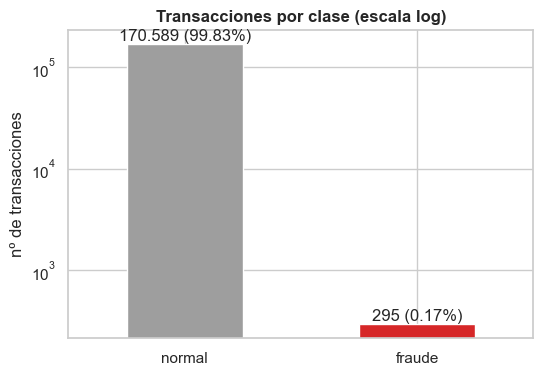

AUPR aleatoria = prevalencia = 0.0017 · accuracy de predecir siempre 'normal' = 99.83% · fraudes: train 206, test 89


In [6]:
n_cls = df_const.Class.value_counts().rename(LBL)
prev = df_const.Class.mean()
ax = n_cls.plot.bar(color=[C[0], C[1]], rot=0, logy=True, figsize=(6, 4), title="Transacciones por clase (escala log)")
ax.bar_label(ax.containers[0], labels=[f"{v:,} ({v / n_cls.sum():.2%})".replace(",", ".") for v in n_cls])
ax.set(xlabel="", ylabel="nº de transacciones")
plt.show()
# un modelo que dice "todo normal" acierta casi siempre y no detecta ningún fraude
print(f"AUPR aleatoria = prevalencia = {prev:.4f} · accuracy de predecir siempre 'normal' = {1 - prev:.2%} "
      f"· fraudes: train {int(y_train.sum())}, test {int(y_test.sum())}")

> **Conclusión:** 170.884 transacciones de construcción y 113.923 de producción, **sin nulos**. Las `X1..X20` son enteras y centradas; `Amount` está en otra escala (hasta 29.485 en construcción y 38.537 en producción). Hay **295 fraudes (0,17 %)**: decir siempre "normal" da un 99,83 % de accuracy sin detectar ninguno, y la **AUPR aleatoria es 0,0017**. → **Impacto:** la AUPR es la única métrica de selección en todo el notebook (la referencia a batir es el 0,567 del GMM del notebook de partida, no el 0,0017). Split y CV estratificados; con ~41 fraudes por fold la AUPR oscilará mucho entre folds, así que toda comparación se hace fold a fold.

### 1.2 ¿Hay duplicados?

**Qué miramos y por qué.** Filas idénticas, cuántas son fraude y si alguna copia tiene etiqueta distinta. Si una copia cae en entrenamiento y otra en validación, el modelo "reconoce" la fila y la AUPR sale optimista (**fuga**). Además, un fraude repetido deja de ser raro para un detector de densidad.

In [7]:
# hash por fila sobre las 21 variables originales: rápido y comparable entre ficheros
h_const = pd.util.hash_pandas_object(raw_const[FEAT_RAW], index=False)
h_prod = pd.util.hash_pandas_object(raw_prod[FEAT_RAW], index=False)
n_etiquetas = raw_const.Class.groupby(h_const.values).nunique()     # nº de clases distintas por grupo de filas idénticas
pd.Series({"duplicados en construcción": h_const.duplicated().sum(),
           "duplicados entre fraudes": h_const[raw_const.Class == 1].duplicated().sum(),
           "grupos idénticos con Class distinta": (n_etiquetas > 1).sum(),
           "duplicados en producción": h_prod.duplicated().sum(),
           "filas de producción idénticas a alguna de construcción": h_prod.isin(h_const).sum(),
           "filas de test con copia exacta en train": dup_test.sum(),
           "fraudes de test con copia exacta en train": int((dup_test & (y_te == 1)).sum())}, name="nº").to_frame()

,nº
duplicados en construcción,4167
duplicados entre fraudes,10
grupos idénticos con Class distinta,0
duplicados en producción,2109
filas de producción idénticas a alguna de construcción,4314
filas de test con copia exacta en train,1643
fraudes de test con copia exacta en train,5


> **Conclusión:** **4.167 filas duplicadas** en construcción (10 entre fraudes) y **0 conflictos de etiqueta**: son copias, no ruido. Producción tiene 2.109 duplicados internos y **4.314 filas (3,8 %) idénticas a alguna de construcción**. El split fijo del profesor no agrupa: **1.643 filas de test (5 de los 89 fraudes) tienen copia en train**, un 3,2 %, parecido al 3,8 % de producción. → **Impacto:** **agrupar, no borrar** (bloque 0, D-1.1): las filas idénticas comparten `group_id` y `StratifiedGroupKFold` nunca las separa entre entrenamiento y validación. El test se reporta con y sin las filas `dup_en_train`, y producción se puntúa entera y en su orden, sin deduplicar.

### 1.3 ¿Qué variables separan el fraude?

**Qué miramos y por qué.** La AUPR **univariante** de cada variable: ordenar las transacciones solo por esa variable (en el sentido que más fraude pone arriba) y medir la AUPR. Es la misma métrica que el modelo final, así que dice directamente cuánta señal aporta cada variable sola. Las variables sin señal degradan los métodos de distancia y densidad. Se calcula **solo con train**: las etiquetas del test no se miran para decidir variables.

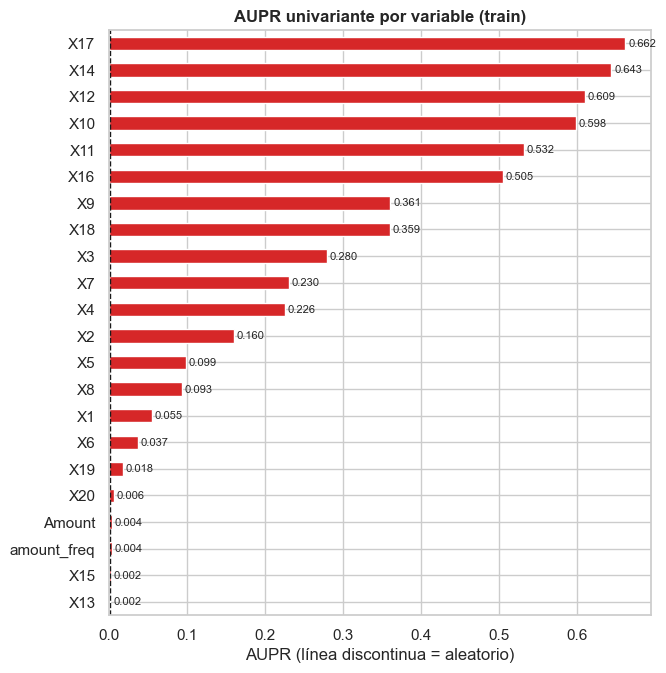

,X17,X14,X12,X10,X11,X16,X9,X18
aupr_uni,0.662,0.643,0.609,0.598,0.532,0.505,0.361,0.359
ks,0.782,0.866,0.784,0.817,0.766,0.738,0.581,0.538


In [8]:
# AUPR univariante orientado: max(AUPR(x), AUPR(−x)); KS fraude vs normal como contraste. Solo train.
def uni_scores(X, y):
    y = np.asarray(y)
    return pd.DataFrame({c: {"aupr_uni": max(average_precision_score(y, X[c]), average_precision_score(y, -X[c])),
                             "ks": stats.ks_2samp(X[c][y == 1], X[c][y == 0]).statistic} for c in X}).T

uni = uni_scores(tr[FEAT_RAW + ["amount_freq"]], y_train)
barh_rank(uni.aupr_uni, "AUPR univariante por variable (train)", ref=y_train.mean())
plt.gca().set(xlabel="AUPR (línea discontinua = aleatorio)")
plt.show()
uni.sort_values("aupr_uni", ascending=False).head(8).round(3).T

Las distribuciones por clase de las seis mejores variables (cada clase normalizada por separado; eje recortado a p0,2–p99,8):

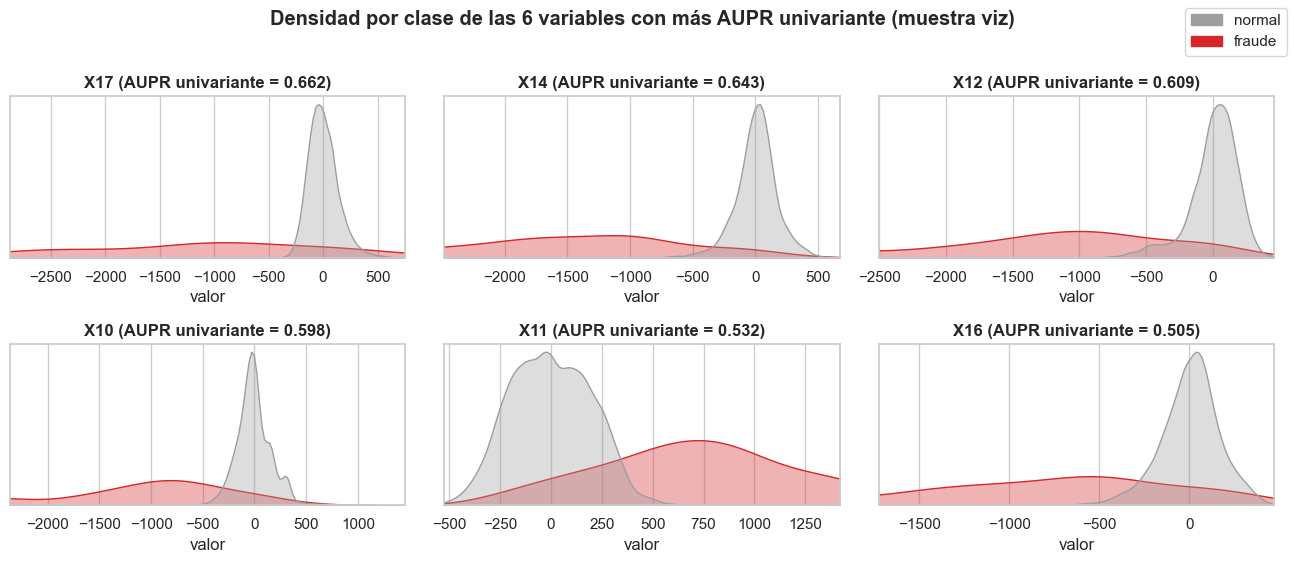

In [9]:
top6 = uni.aupr_uni.drop("amount_freq").nlargest(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5))
for ax, col in zip(axes.flat, top6):
    sns.kdeplot(data=viz, x=col, hue="Class", palette=C, common_norm=False, fill=True, alpha=.35, ax=ax, legend=False)
    ax.set(title=f"{col} (AUPR univariante = {uni.aupr_uni[col]:.3f})", xlabel="valor", ylabel="",
           yticks=[], xlim=viz[col].quantile([.002, .998]).tolist())
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C[k]) for k in C], labels=list(LBL.values()), loc="upper right")
fig.suptitle("Densidad por clase de las 6 variables con más AUPR univariante (muestra viz)", y=1.02, fontweight="bold")
fig.tight_layout()

> **Conclusión:** cuatro variables concentran la señal: **X17 (0,662), X14 (0,643), X12 (0,609) y X10 (0,598)** de AUPR univariante en train, ya al nivel del GMM del notebook de partida. Les siguen X11 (0,532) y X16 (0,505); el resto es débil (≤ 0,36) y `Amount` casi aleatorio (0,004). En las seis mejores el fraude no es un pico separado, sino una **cola larga y ancha** hacia valores extremos (negativos en X17, X14, X12, X10 y X16) sobre la que se apoya la masa de los normales. El KS ordena distinto (en el 01, X4 tenía KS 0,77 pero AUPR 0,23): desplazar la distribución no basta, la AUPR premia poner el fraude arriba del ranking. → **Impacto:** en los detectores de distancia y densidad se comparan "todas" las variables frente a "top-k" (bloque 2); los árboles del bloque 3 seleccionan solos. La forma en cola anticipa que los fraudes son **extremos** (§1.5).

### 1.4 ¿Qué pasa con `Amount`?

**Qué miramos y por qué.** Su escala, su cola y su relación con el fraude. Es la única variable con significado directo y con otra escala, y transformarla cambia qué es outlier para un detector de distancia.

In [10]:
# cola pesada: asimetría y curtosis (exceso) de Amount frente a log1p(Amount), construcción completa
pd.DataFrame({"asimetría": [raw_const.Amount.skew(), df_const.log1p_Amount.skew()],
              "curtosis": [raw_const.Amount.kurt(), df_const.log1p_Amount.kurt()]},
             index=["Amount", "log1p(Amount)"]).round(2)

,asimetría,curtosis
Amount,13.39,465.63
log1p(Amount),0.09,-0.64


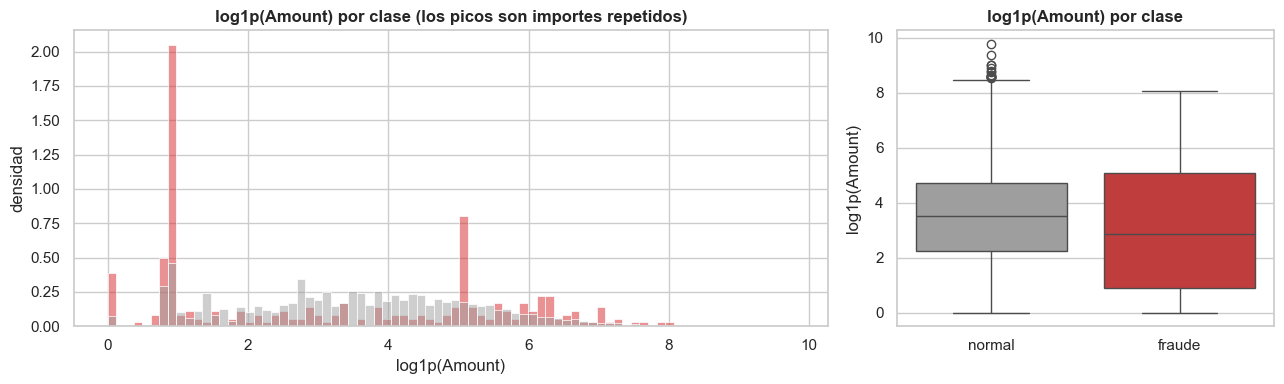

In [11]:
d_amt = viz.assign(clase=viz.Class.map(LBL))
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(data=d_amt, x="log1p_Amount", hue="Class", palette=C, stat="density", common_norm=False, bins=80,
             ax=axes[0], legend=False)
axes[0].set(title="log1p(Amount) por clase (los picos son importes repetidos)", xlabel="log1p(Amount)", ylabel="densidad")
sns.boxplot(data=d_amt, x="clase", y="log1p_Amount", hue="clase", palette=pal_clase, ax=axes[1])
axes[1].set(title="log1p(Amount) por clase", xlabel="", ylabel="log1p(Amount)")
fig.tight_layout()

In [12]:
# resumen por clase y los cinco importes exactos más frecuentes entre los fraudes
q95 = lambda s: s.quantile(.95)
pct_ceros = lambda s: (s == 0).mean() * 100
display(raw_const.groupby(raw_const.Class.map(LBL)).Amount.agg(mediana="median", p95=q95, máximo="max",
                                                                 pct_ceros=pct_ceros).round(2))
top_imp = raw_const[raw_const.Class == 1].Amount.value_counts().head(5)
pct_imp = lambda k: [100 * (raw_const[raw_const.Class == k].Amount == v).mean() for v in top_imp.index]
pd.DataFrame({"n_fraudes": top_imp.values, "% de fraudes": pct_imp(1), "% de normales": pct_imp(0)},
             index=top_imp.index.rename("importe exacto")).round(2)

,mediana,p95,máximo,pct_ceros
Class,,,,
fraude,16.50,802.53,3188.8,4.07
normal,33.03,549.55,29484.8,0.63


,n_fraudes,% de fraudes,% de normales
importe exacto,,,
1.50,72,24.41,4.77
149.98,18,6.10,0.11
1.14,12,4.07,1.06
0.00,12,4.07,0.63
1.16,6,2.03,0.50


Esos importes repetidos son la razón de `amount_freq` (bloque 0): cuántas veces aparece el importe exacto en construcción + producción, sin usar etiquetas. ¿Los fraudes usan importes más repetidos? Solo con train:

In [13]:
q90 = lambda s: s.quantile(.9)
display(tr.groupby(tr.Class.map(LBL)).amount_freq.agg(mediana="median", p90=q90, media="mean").round(1))
print(f"AUPR univariante en train: Amount = {uni.aupr_uni['Amount']:.3f} · amount_freq = {uni.aupr_uni['amount_freq']:.3f} "
      f"(aleatorio = {y_train.mean():.4f})")

,mediana,p90,media
Class,,,
fraude,246.5,13688.0,3656.3
normal,79.0,4747.0,1329.3


AUPR univariante en train: Amount = 0.004 · amount_freq = 0.004 (aleatorio = 0.0017)


> **Conclusión:** `Amount` tiene una cola enorme (curtosis 466; con `log1p` queda en −0,64 y asimetría 0,09). El fraude tiene **mediana 16,5 frente a 33,0** y p95 802 frente a 550, pero **nunca pasa de 3.189** (los normales llegan a 29.485): la relación no es monótona, y por eso su AUPR univariante es casi aleatoria (0,004). La señal está en **importes exactos**: **1,50 es el 24,4 % de los fraudes** (4,8 % de los normales), 149,98 el 6,1 % (0,1 %) y 0,00 el 4,1 % (0,6 %). En train, la mediana de `amount_freq` es **246 en fraudes frente a 79 en normales**, aunque sola, como ranking monótono, tampoco ordena (AUPR 0,004): su señal aparece combinada con las demás variables. → **Impacto:** `log1p_Amount` sustituye a `Amount` en distancia y densidad (D-1.2) y `amount_freq` lleva la señal de importes repetidos a todos los modelos (D-1.4); los árboles aprovechan los importes exactos sin binarizarlos a mano. Como `amount_freq` cuenta también producción, en despliegue habría que recalcularla con cada lote.

### 1.5 ¿Están correlacionadas? ¿Hay estructura multivariante?

**Qué miramos y por qué.** La correlación por clase. Si los fraudes se mueven juntos en una dirección, la anomalía es **dependiente**: la ve una distancia que tenga en cuenta las correlaciones (Mahalanobis) y no la euclídea, que trata cada eje por separado. Lo comprobamos después midiendo las dos distancias con la CV de 5 folds.

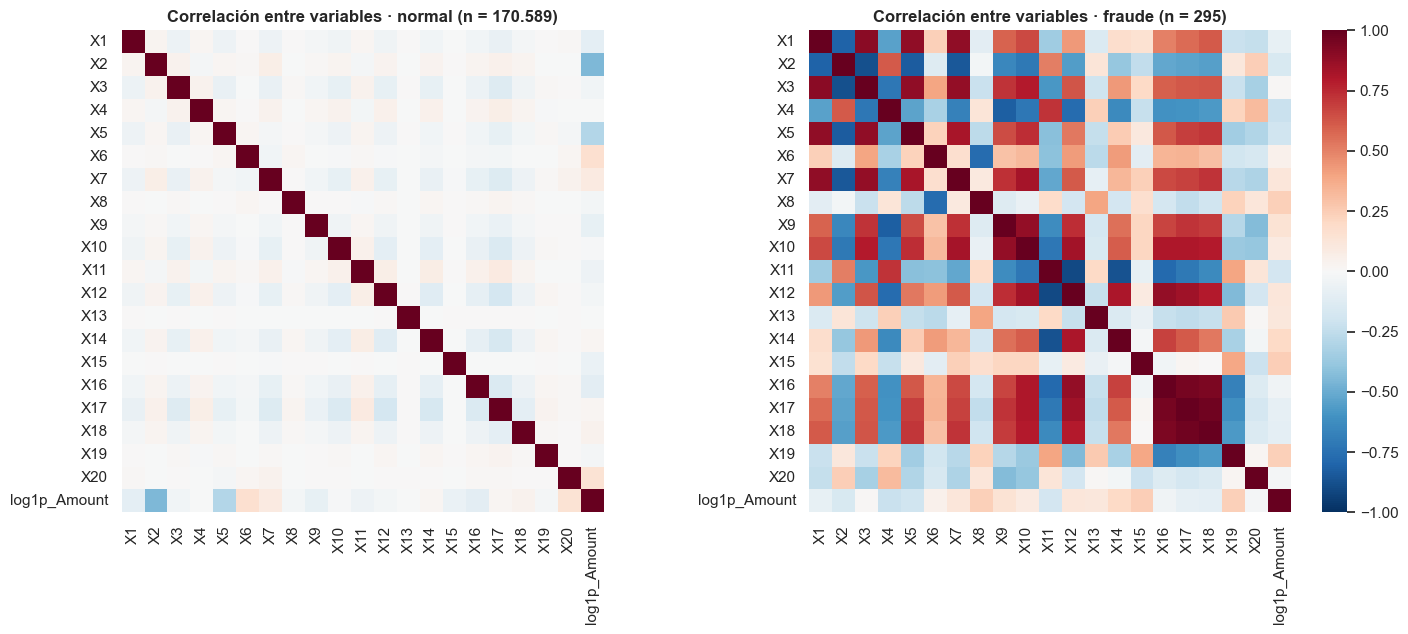

In [14]:
# Amount con log1p para que su cola no domine; misma escala de color en las dos clases
Z_eda = df_const[FEAT_RAW].assign(Amount=df_const.log1p_Amount).rename(columns={"Amount": "log1p_Amount"})
corr_cls = {k: Z_eda[df_const.Class == k].corr() for k in (0, 1)}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, k in zip(axes, (0, 1)):
    sns.heatmap(corr_cls[k], cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, cbar=k == 1,
                xticklabels=True, yticklabels=True, ax=ax)
    ax.set_title(f"Correlación entre variables · {LBL[k]} (n = {(df_const.Class == k).sum():,})".replace(",", "."))
fig.tight_layout()

In [15]:
# correlación absoluta media fuera de la diagonal (0 = incorreladas) y pares más correlados en los normales
fuera = ~np.eye(len(Z_eda.columns), dtype=bool)
display(pd.Series({LBL[k]: np.abs(corr_cls[k].values[fuera]).mean() for k in (0, 1)}, name="|corr| media").round(3).to_frame())
corr_cls[0].where(np.triu(fuera)).stack().abs().nlargest(3).round(2).rename("|corr| (normales)").to_frame()

,|corr| media
normal,0.036
fraude,0.415


,,|corr| (normales)
X2,log1p_Amount,0.45
X5,log1p_Amount,0.29
X12,X17,0.17


Las cuatro mejores variables del §1.3 por parejas, en la muestra `viz`:

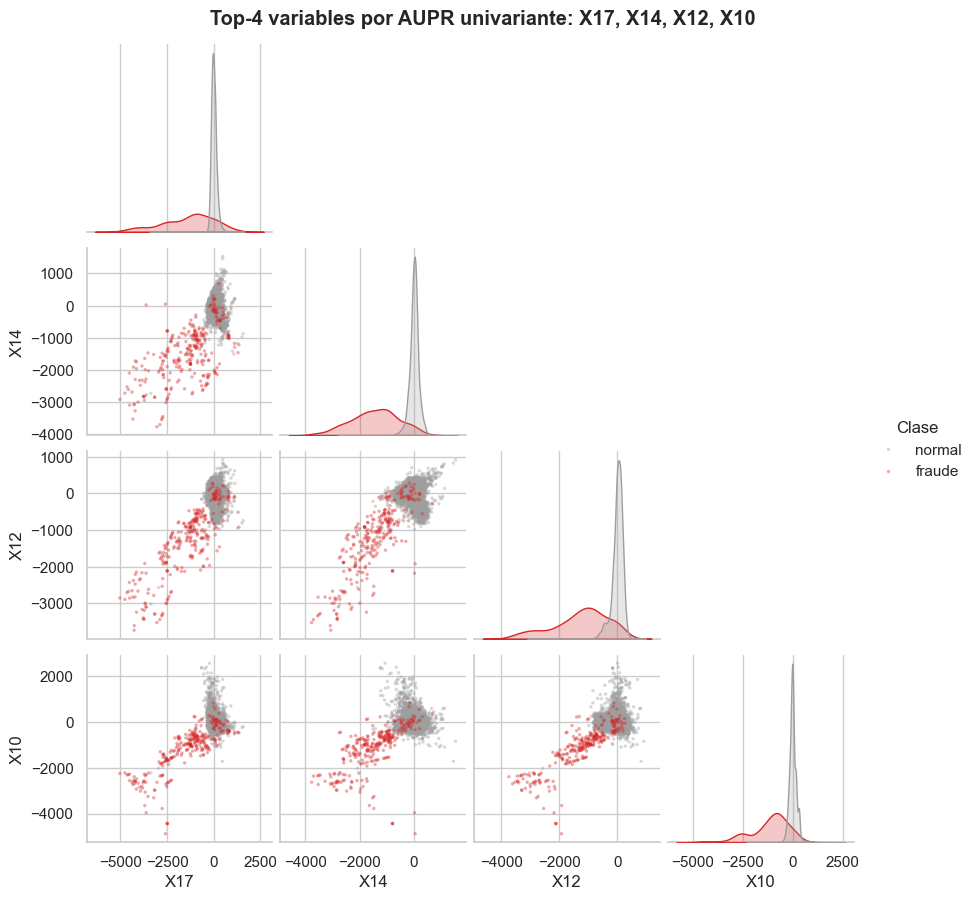

In [16]:
top4 = top6[:4]
g = sns.pairplot(viz[top4].assign(Clase=viz.Class.map(LBL)), hue="Clase", palette=pal_clase, corner=True, height=2.2,
                 plot_kws=dict(s=6, alpha=.4, linewidth=0), diag_kws=dict(common_norm=False))
g.figure.suptitle(f"Top-4 variables por AUPR univariante: {', '.join(top4)}", y=1.02, fontweight="bold");

¿Cuántos fraudes están fuera de la nube normal? Distancia de Mahalanobis a los **normales de train** (las 22 `FEATURES`), y qué fracción de los 295 fraudes supera el percentil 99 de los normales:

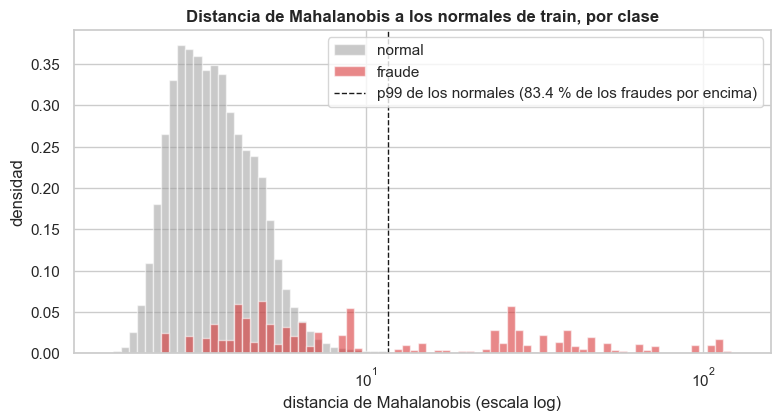

p99 de los normales de train = 11.66 · fraudes por encima: 83.4 % de 295


In [17]:
from sklearn.covariance import EmpiricalCovariance
cov_n = EmpiricalCovariance().fit(Xa[ya == 0])                       # solo normales de train
d_mah = np.sqrt(cov_n.mahalanobis(df_const[FEATURES].to_numpy(float)))   # .mahalanobis() devuelve d²
es_tr, cls_c = (df_const.split == "train").to_numpy(), df_const.Class.to_numpy()
p99_mah = np.quantile(d_mah[es_tr & (cls_c == 0)], .99)
pct_fuera = 100 * (d_mah[cls_c == 1] > p99_mah).mean()

bins = np.logspace(np.log10(d_mah.min()), np.log10(d_mah.max()), 80)
fig, ax = plt.subplots(figsize=(9, 4.2))
for k in (0, 1):
    ax.hist(d_mah[cls_c == k], bins=bins, density=True, alpha=.55, color=C[k], label=LBL[k])
ax.axvline(p99_mah, ls="--", c="k", lw=1, label=f"p99 de los normales ({pct_fuera:.1f} % de los fraudes por encima)")
ax.set(xscale="log", xlabel="distancia de Mahalanobis (escala log)", ylabel="densidad",
       title="Distancia de Mahalanobis a los normales de train, por clase")
ax.legend()
plt.show()
print(f"p99 de los normales de train = {p99_mah:.2f} · fraudes por encima: {pct_fuera:.1f} % de 295")

Y la comparación que decide el tipo de distancia, con la CV oficial de 5 folds (cada detector se ajusta solo con las normales del fold): **Mahalanobis** (una gaussiana con covarianza completa: su −log-verosimilitud es la distancia de Mahalanobis más una constante) frente a la **euclídea** sobre variables estandarizadas (una gaussiana esférica: −log-verosimilitud ∝ distancia euclídea²).

In [18]:
from sklearn.mixture import GaussianMixture
evaluar("EDA · Mahalanobis", make_pipe(GaussianMixture(1, covariance_type="full", random_state=SEED)), "no supervisado")
evaluar("EDA · Euclídea (std)", make_pipe(GaussianMixture(1, covariance_type="spherical", random_state=SEED)), "no supervisado")
tabla_cv(["EDA · Mahalanobis", "EDA · Euclídea (std)"])

EDA · Mahalanobis: CV AUPR = 0.655 ± 0.076  (3 s)


EDA · Euclídea (std): CV AUPR = 0.316 ± 0.065  (1 s)


,familia,n_feats,media,std,segundos,fold0,fold1,fold2,fold3,fold4
EDA · Mahalanobis,no supervisado,22.0,0.655,0.076,2.728,0.749,0.628,0.554,0.607,0.737
EDA · Euclídea (std),no supervisado,22.0,0.316,0.065,0.762,0.366,0.284,0.227,0.292,0.411


> **Conclusión:** los normales están casi incorrelados en media (**|corr| 0,036**, con algún par fuerte como X2–Amount, 0,45), mientras que los fraudes están **muy correlados entre sí (0,415)**: se mueven juntos, con X17, X14, X12 y X10 negativos a la vez (la **cola diagonal** del pairplot). La mayoría son **extremos globales**: el **83,4 %** de los fraudes supera el p99 de Mahalanobis de los normales, y el histograma es bimodal (~1 de cada 6 fraudes queda dentro de la nube). En CV, **Mahalanobis da 0,655 de AUPR frente a 0,316 de la euclídea**, y gana en los 5 folds. → **Impacto:** detectores que tengan en cuenta la covarianza (Mahalanobis, GMM `full`) y nunca la euclídea (D-1.2); en el bloque 2 van primero los detectores globales. El ~17 % de fraudes dentro de la nube es lo que justifica el enfoque supervisado (bloque 3). No se recortan outliers: son la señal.

### 1.6 ¿Producción se parece a construcción?

**Qué miramos y por qué.** La AUPR que cuenta es la de producción. Si producción tuviese otra distribución (*data shift*), la AUPR de la CV y del test interno no la anticiparía. Lo miramos de dos formas: variable a variable (KS entre ficheros) y en conjunto (**validación adversarial**: si un clasificador no distingue de qué fichero viene cada fila, AUC ≈ 0,5, los ficheros son intercambiables).

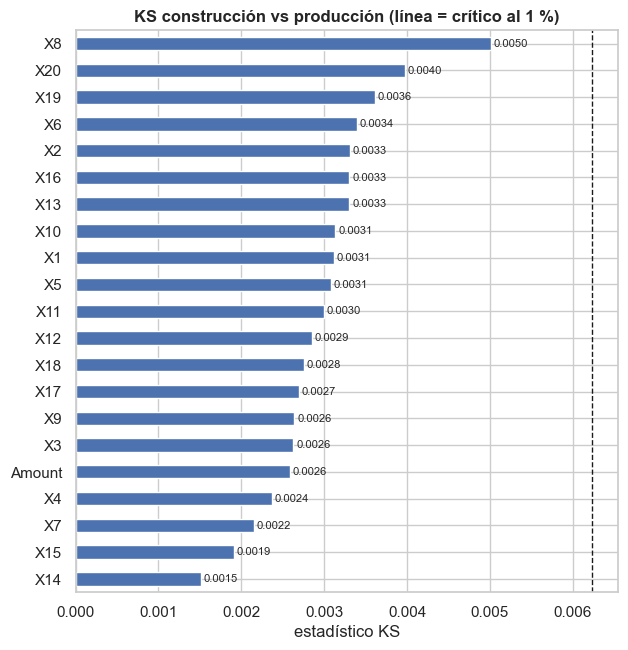

KS máximo = 0.0050 (X8) · crítico al 1 % = 0.0062


In [19]:
# KS por variable entre construcción y producción; línea = valor crítico del KS al 1 % para estos tamaños
n_c, n_p = len(raw_const), len(raw_prod)
ks_shift = pd.Series({c: stats.ks_2samp(raw_const[c], raw_prod[c]).statistic for c in FEAT_RAW})
ks_crit = 1.63 * np.sqrt((n_c + n_p) / (n_c * n_p))
barh_rank(ks_shift, "KS construcción vs producción (línea = crítico al 1 %)", ref=ks_crit, fmt="{:.4f}", color="#4c72b0")
plt.gca().set(xlabel="estadístico KS")
plt.show()
print(f"KS máximo = {ks_shift.max():.4f} ({ks_shift.idxmax()}) · crítico al 1 % = {ks_crit:.4f}")

In [20]:
# validación adversarial: construcción (0) vs producción (1), 50.000 + 50.000 filas, CV estratificada de 5 folds
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
X_adv = pd.concat([raw_const[FEAT_RAW].sample(50_000, random_state=SEED), raw_prod[FEAT_RAW].sample(50_000, random_state=SEED)])
y_adv = np.r_[np.zeros(50_000), np.ones(50_000)]
p_adv = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), X_adv, y_adv,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"AUC adversarial (CV 5, 50.000 + 50.000 filas) = {roc_auc_score(y_adv, p_adv):.3f}")

AUC adversarial (CV 5, 50.000 + 50.000 filas) = 0.496


> **Conclusión:** **no hay data shift**. El KS máximo entre ficheros es **0,005 (X8)**, por debajo del crítico al 1 % (0,0062), y la validación adversarial da **AUC 0,496**: un clasificador no sabe de qué fichero viene cada fila. Lo único distinto es el máximo de `Amount` (38.537 en producción frente a 29.485). → **Impacto:** la AUPR de la CV y del test interno es una estimación fiable de la de producción (D-1.3), y todo el preprocesado se ajusta solo con construcción. El `Amount` fuera de rango se absorbe con `log1p` y escaladores que no recortan.

### 1.7 Qué más vimos (notebook 01)

Lo que el notebook 01 analizó y aquí no se re-ejecuta, con sus cifras. La Parte II del 01 (§12–§16: duplicados, transformaciones, escalado, folds y exportación) es exactamente la preparación del **bloque 0**.

| Análisis (01) | Resultado | Conclusión |
|---|---|---|
| Ficha y `describe()` (§1) | 0 nulos; `X1..X20` enteras, centradas, std 152–391, rangos enormes (X8 hasta −14.644) | Sin imputación; `Amount` en otra escala → escalado dentro del `Pipeline` en los métodos de distancia |
| Asimetría y curtosis de todas las variables (§4) | Curtosis: Amount 466, X8 254, X20 185, X2 101, X17 98; solo X4, X11, X13, X15, X18 y X19 casi gaussianas | Colas pesadas: probar transformaciones antes de GMM y decidir por AUPR en CV (bloque 2) |
| Densidades por clase de las 20 `X` (§4) | Las del fraude son mucho más anchas y desplazadas que las normales | Coherente con fraude = extremos (§1.3 y §1.5) |
| KS fraude vs normal (§5) | X4 tiene KS alto (0,77) pero AUPR univariante baja (0,23) | El KS no sirve para elegir variables; se usa la AUPR univariante |
| PCA 2D ajustada en normales (§8) | 13,5 % de varianza explicada; apenas separa, los fraudes se esparcen a lo largo de PC2 | Las dos direcciones de máxima varianza de los normales no son las del fraude; se exploran las de menor varianza en el bloque 2 |
| % de puntos con \|z\| > 3 por variable (§9) | Fraudes fuera: X14 84 %, X17 80 %, X12 76 %, X10 71 %; normales ≈ 1 % | Los fraudes están en las colas de las mejores variables |
| AUPR de Mahalanobis en el test fijo (§9) | 0,580 (21 variables con `log1p(Amount)`) | Solo informativo; aquí se mide en CV (0,655 con las 22 `FEATURES`) |
| Precisión al p99 de Mahalanobis (§9) | ≈ 245 fraudes frente a ≈ 1.700 normales por encima (precisión ≈ 13 %) | Por eso un detector global se queda en AUPR ≈ 0,6 |
| `amount_freq` (§13, Parte II) | Mediana en train 246 (fraude) frente a 79 (normal); p90 13.688 frente a 4.747 | Se añade como variable (D-1.4); aquí se re-calcula en el §1.4 |

### 1.8 Conclusiones del bloque

| Hallazgo | Evidencia | Decisión | Dónde |
|---|---|---|---|
| Desbalanceo extremo | 295 fraudes (0,17 %); AUPR aleatoria 0,0017 | AUPR como única métrica; CV estratificada por grupos | Todo el notebook |
| Duplicados sin conflicto | 4.167 en construcción (10 fraudes), 0 conflictos; 1.643 filas de test con copia en train | Agrupar con `group_id`, no borrar; test con y sin `dup_en_train` | Bloque 0 (D-1.1) |
| Producción comparte filas con construcción | 4.314 filas idénticas (3,8 %) | Puntuar producción entera y en su orden | Bloque 5 |
| Pocas variables concentran la señal | AUPR univariante X17 0,662, X14 0,643, X12 0,609, X10 0,598 | Comparar "todas" frente a "top-k" en distancia/densidad | Bloque 2 |
| `Amount`: cola pesada e importes exactos | Curtosis 466; 1,50 = 24 % de los fraudes; `amount_freq` 246 frente a 79 | `log1p_Amount` + `amount_freq` | Bloque 0 (D-1.2, D-1.4) |
| Fraude = dirección conjunta correlada | \|corr\| 0,415 en fraudes frente a 0,036; Mahalanobis 0,655 frente a euclídea 0,316 en CV | Distancias con covarianza, nunca euclídea | Bloque 2 |
| La mayoría de fraudes son extremos globales | 83 % por encima del p99 de Mahalanobis; ~17 % dentro de la nube | Detectores globales primero; supervisado para el resto | Bloques 2 y 3 |
| Sin data shift | KS ≤ 0,005; AUC adversarial 0,496 | La AUPR de CV/test estima la de producción | Bloques 4–6 (D-1.3) |

**Al bloque siguiente:** el bloque 2 parte de la Mahalanobis (0,655 en CV) y explora hasta dónde llega la detección de anomalías pura con las 22 `FEATURES` y los mismos 5 folds.

---
## 2. Enfoque no supervisado (detección de anomalías)

**Pregunta del bloque.** ¿Hasta dónde llega un detector que aprende **solo cómo es una transacción normal** y puntúa lo rara que es cada fila, sin ver nunca un fraude al entrenar? Es el enfoque del notebook de partida, y el que recomienda el profesor cuando hay muy pocas anomalías: las etiquetas se usan solo para **validar**.

**Protocolo (igual para todos los detectores).**

1. Cada detector se ajusta **solo con los normales** del fold de entrenamiento (`fit()` descarta los fraudes) y puntúa el fold de validación completo con el convenio *mayor = más fraude* (`score()` = −`score_samples`).
2. AUPR en los **5 folds** de `cv_splits` (`evaluar()`). Con ~41 fraudes por fold la AUPR de un fold es muy ruidosa: en el notebook 02 (§1) un mismo detector iba de 0,554 a 0,749 según el fold. **Regla:** una diferencia de medias menor que ~1 std entre folds (≈ 0,08) no es concluyente, salvo que se repita en al menos 4 de los 5 folds.
3. El test fijo (89 fraudes) solo **confirma** al final (2.5); no elige nada.

| Apartado | Pregunta |
|---|---|
| 2.1 | ¿Cuánto da el GMM del notebook de partida? |
| 2.2 | ¿Distancia o densidad, y con qué escalador? |
| 2.3 | ¿Dónde vive la señal del fraude? |
| 2.4 | ¿Mejoran los detectores si solo miran esa dirección? |
| 2.5 | ¿Se confirma en test, y qué fraudes se escapan? |
| 2.6 | Qué más probamos (notebook 02) |
| 2.7 | Conclusiones del bloque |

In [21]:
from sklearn.base import BaseEstimator, OutlierMixin, TransformerMixin
from sklearn.mixture import GaussianMixture
from sklearn.covariance import EmpiricalCovariance
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score

ns_t0 = time.time()                          # tiempo del bloque 2
NS = "no supervisado"                        # familia (color) de todos los detectores del bloque

### 2.1 ¿Cuánto da el GMM del notebook de partida?

**Qué miramos y por qué.** El punto de partida es el modelo del notebook del profesor: `GaussianMixture(5)` sobre las **21 variables crudas** (`Amount` sin transformar), sin escalar, ajustado con los normales de train. En su notebook da **0,567** de AUPR en test. Aquí lo medimos primero con el protocolo de CV, para tener una cifra comparable con todo lo demás.

In [22]:
# tal cual el notebook de partida: 21 variables crudas, sin escalar, 5 gaussianas
evaluar("GMM 5 partida (21 crudas)", GaussianMixture(5, random_state=SEED), NS, X=tr[FEAT_RAW]);

GMM 5 partida (21 crudas): CV AUPR = 0.533 ± 0.077  (25 s)


En test aparece una sorpresa: **las mismas filas de train en otro orden dan otra AUPR**. El notebook de partida ajusta con las filas en el orden barajado que devuelve `train_test_split`; este notebook las tiene ordenadas por `row_id`. Lo comprobamos ajustando el mismo modelo, con la misma semilla, en los dos órdenes:

In [23]:
# mismo modelo, misma semilla, mismas filas de train: solo cambia el orden
ns_tr_prof = train_test_split(raw_const, test_size=0.3, random_state=SEED, stratify=raw_const["Class"])[0]
assert set(ns_tr_prof.index) == set(tr.index), "no son las mismas filas"
ns_prof = {}
for orden, d in {"orden del notebook de partida": ns_tr_prof, "orden por row_id (este notebook)": tr}.items():
    m = fit(GaussianMixture(5, random_state=SEED), d[FEAT_RAW].to_numpy(float), d["Class"])
    ns_prof[orden] = {"modelo": m, "score": score(m, te[FEAT_RAW].to_numpy(float))}
pd.DataFrame({o: {"AUPR test": average_precision_score(y_te, r["score"]),
                  "pesos de las 5 gaussianas": " · ".join(f"{p:.2f}" for p in np.sort(r["modelo"].weights_)[::-1]),
                  "iteraciones de EM": r["modelo"].n_iter_} for o, r in ns_prof.items()}).T.round(3)

,AUPR test,pesos de las 5 gaussianas,iteraciones de EM
orden del notebook de partida,0.567348,0.47 · 0.22 · 0.20 · 0.07 · 0.05,41
orden por row_id (este notebook),0.494938,0.47 · 0.23 · 0.17 · 0.08 · 0.06,33


> **Conclusión:** El GMM del notebook de partida da **0,533 ± 0,077** en CV. En test reproduce exactamente el **0,567** del profesor con su orden de filas, pero da **0,495** con las mismas filas ordenadas por `row_id`. EM arranca de un k-means (`init_params="kmeans"`) cuya semilla elige **posiciones** de filas: con otro orden, la misma semilla elige otros puntos de partida y EM acaba en otro óptimo local (pesos de las gaussianas distintos). La diferencia (0,072) está dentro del ruido del test (§2.5: con 89 fraudes, ±0,09). → **Impacto:** la referencia que hay que batir es **0,533 ± 0,077 en CV** y **0,495 en test** con el orden de este notebook (0,567 con el del profesor). Y una lección para todo el bloque: un GMM depende de su inicialización, así que sus comparaciones se hacen con la CV fold a fold, no con una cifra suelta.

### 2.2 ¿Distancia o densidad, y con qué escalador?

**Qué miramos y por qué.** Con el preprocesado del bloque 0 (`FEATURES`: `log1p_Amount` y `amount_freq` en lugar de `Amount`), probamos dos detectores de densidad:

- **Mahalanobis** = una sola gaussiana: la distancia al centro de los normales teniendo en cuenta su covarianza. Ordena igual que $-\log p(x)$ de una normal multivariante.
- **GMM 5 `full`**, el del profesor, con **StandardScaler** frente a **RobustScaler**. D-1.2 decía que un GMM `full` no cambia con escalados lineales. Es cierto para el modelo, pero EM **arranca de un k-means euclídeo**, que sí depende de la escala.

La euclídea al centroide (que ignora la covarianza) quedó descartada en el 02 (0,316); va a la tabla de 2.6.

In [24]:
class Mahalanobis(OutlierMixin, BaseEstimator):
    """Gaussiana única: score_samples = −d² de Mahalanobis al centro de los normales (mayor = más normal)."""
    def fit(self, X, y=None):
        self.cov_ = EmpiricalCovariance().fit(X)
        return self
    def score_samples(self, X):
        return -self.cov_.mahalanobis(X)

evaluar("Mahalanobis (22 var.)", make_pipe(Mahalanobis()), NS);

Mahalanobis (22 var.): CV AUPR = 0.655 ± 0.076  (0 s)


In [25]:
# GMM 5 full sobre las 22 FEATURES con los dos escaladores (el escalador se ajusta dentro de cada fold)
for sc in ["standard", "robust"]:
    evaluar(f"GMM 5 {sc} (22 var.)", make_pipe(GaussianMixture(5, random_state=SEED), sc), NS)

GMM 5 standard (22 var.): CV AUPR = 0.660 ± 0.094  (43 s)


GMM 5 robust (22 var.): CV AUPR = 0.734 ± 0.075  (37 s)


¿Por qué cambia con el escalador? Los 5 grupos de los que arranca EM son los de un `KMeans(5, n_init=1)` con la misma semilla, que usa la distancia euclídea. Tamaño de esos grupos iniciales en los normales de train:

In [26]:
# el mismo k-means con el que GaussianMixture inicializa EM, sobre los normales de train
ns_X0 = Xa[ya == 0]
pd.DataFrame({sc: np.sort(np.bincount(make_pipe(KMeans(5, n_init=1, random_state=SEED), sc).fit(ns_X0)[-1].labels_))[::-1]
              for sc in ["standard", "robust"]}, index=[f"grupo {k + 1}" for k in range(5)])

,standard,robust
grupo 1,48874,91183
grupo 2,34439,17723
grupo 3,16038,5636
grupo 4,11089,3823
grupo 5,8972,1047


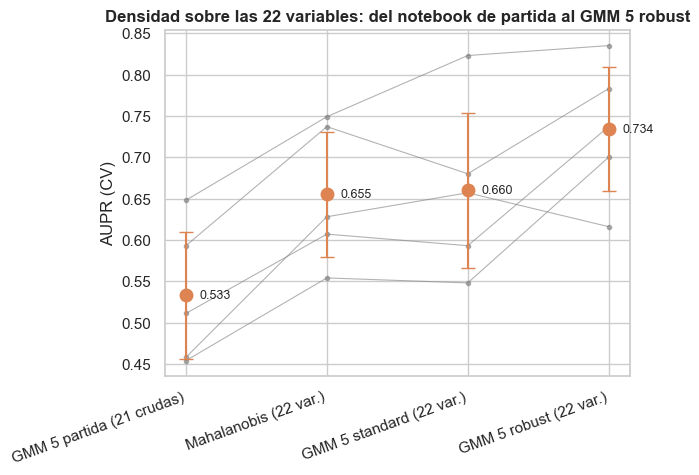

In [27]:
plot_folds(["GMM 5 partida (21 crudas)", "Mahalanobis (22 var.)", "GMM 5 standard (22 var.)", "GMM 5 robust (22 var.)"],
           title="Densidad sobre las 22 variables: del notebook de partida al GMM 5 robust");

> **Conclusión:** Con las 22 variables del bloque 0, una sola gaussiana (Mahalanobis) ya da **0,655** frente a **0,533 ± 0,077** del GMM de partida. El GMM 5 da **0,660** con StandardScaler y **0,734** con RobustScaler (robust gana en **4 de 5** folds). El modelo es el mismo; lo que cambia es el arranque: con robust, las variables de colas pesadas (`amount_freq`) pesan más en el k-means, que arranca con un grupo central grande y cuatro pequeños, y EM llega a otro óptimo. En el 02 (§4), con arranque aleatorio (que no mira X) los dos escaladores daban exactamente lo mismo (0,646), y robust ganaba con tres semillas distintas. → **Impacto:** **D-1.2** queda así: RobustScaler para la familia densidad (GMM) y StandardScaler para vecindad (kNN, LOF), donde robust deja que `amount_freq` domine la distancia. El mejor detector con las 22 variables es el **GMM 5 robust (0,734)**. 2.3 explica qué está viendo.

### 2.3 ¿Dónde vive la señal del fraude?

**Qué miramos y por qué.** ¿Por qué Mahalanobis, que solo tiene en cuenta la covarianza, gana tanto a la euclídea (0,316 en el 02)? Porque hay una dirección del espacio de 22 variables en la que **los normales casi no varían**: el autovector de **mínima varianza** de su matriz de covarianza (calculada solo con normales estandarizados). Lo llamamos **eje menor**. Mahalanobis divide cada dirección por su varianza, así que un desvío en ese eje pesa mucho. Miramos qué variables lo forman y dónde caen los fraudes.

In [28]:
# base propia de los normales de train estandarizados (autovalores en orden creciente: el primero es el eje menor)
ns_sc = StandardScaler().fit(ns_X0)
ns_w, ns_V = np.linalg.eigh(np.cov(ns_sc.transform(ns_X0).T))
ns_V[:, 0] *= np.sign(stats.skew(ns_sc.transform(ns_X0) @ ns_V[:, 0]))   # signo sin etiquetas: cola larga de los normales en positivo
ns_cargas = pd.Series(ns_V[:, 0], index=FEATURES)
ns_cargas[ns_cargas.abs().nlargest(8).index].round(2).rename(
    f"eje menor (varianza {ns_w[0]:.2f}; la mayor es {ns_w[-1]:.2f})").to_frame().T

,X17,X12,X14,X10,X7,X16,X3,X11
eje menor (varianza 0.16; la mayor es 1.91),-0.45,-0.34,-0.34,-0.31,-0.29,-0.29,-0.28,0.2


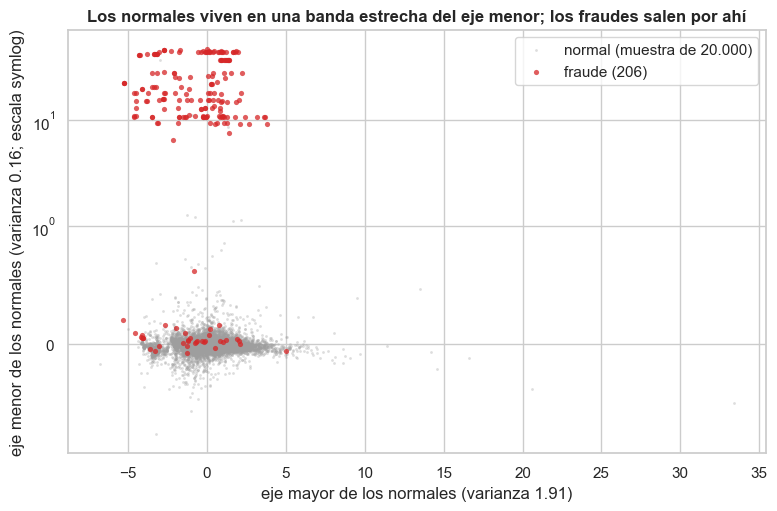

In [29]:
# coordenadas en el plano (eje mayor, eje menor) de todos los fraudes de train y de una muestra de normales
ns_P = ns_sc.transform(Xa) @ ns_V[:, [-1, 0]]
ns_m = np.random.default_rng(SEED).choice(np.flatnonzero(ya == 0), 20_000, replace=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(*ns_P[ns_m].T, s=4, c=C[0], alpha=.35, linewidths=0, label="normal (muestra de 20.000)")
ax.scatter(*ns_P[ya == 1].T, s=14, c=C[1], alpha=.75, linewidths=0, label=f"fraude ({(ya == 1).sum()})")
ax.set_yscale("symlog", linthresh=1)
ax.set(xlabel=f"eje mayor de los normales (varianza {ns_w[-1]:.2f})",
       ylabel=f"eje menor de los normales (varianza {ns_w[0]:.2f}; escala symlog)",
       title="Los normales viven en una banda estrecha del eje menor; los fraudes salen por ahí")
ax.legend(loc="upper right");

In [30]:
# qué parte de cada clase sale de la banda de los normales en el eje menor (|z| > p99,9 de |z| de los normales)
ns_z = ns_P[:, 1]
ns_banda = np.quantile(np.abs(ns_z[ya == 0]), .999)
pd.Series({"banda de los normales (p99,9 de |z|)": round(ns_banda, 2),
           "% de normales fuera": round(100 * (np.abs(ns_z[ya == 0]) > ns_banda).mean(), 2),
           "% de fraudes fuera": round(100 * (np.abs(ns_z[ya == 1]) > ns_banda).mean(), 1),
           "% de fraudes en el lado positivo": round(100 * (ns_z[ya == 1] > 0).mean(), 1)}, name="eje menor (train)").to_frame().T

,"banda de los normales (p99,9 de |z|)",% de normales fuera,% de fraudes fuera,% de fraudes en el lado positivo
eje menor (train),0.57,0.1,82.5,96.1


> **Conclusión:** El eje menor de los normales tiene varianza **0,16** (frente a **1,91** del eje mayor) y lo forman sobre todo **X17, X12, X14 y X10 (pesos −0,45, −0,34, −0,34 y −0,31; después X7, X16 y X3)** a la vez: la "cola diagonal" del EDA (bloque 1), donde varias variables se mueven juntas en el fraude. En esa dirección los normales casi no se mueven y el **82,5 %** de los fraudes de train sale de su banda (la que deja fuera al 0,1 % de los normales), el 96 % por el mismo lado. Es una anomalía **dependiente**: ninguna variable por separado la ve tan bien como su combinación. → **Impacto:** si la señal está en una dirección, un detector que mire **solo esa coordenada** evita el ruido de las colas de los normales en las otras 21 direcciones. Es lo que prueba 2.4. Nota: estas cifras usan las etiquetas de train solo para describir; el eje se calcula sin ellas.

### 2.4 ¿Mejoran los detectores si solo miran el eje menor?

**Qué miramos y por qué.** Un transformador, `EjesPropios`, que **dentro de cada fold** estandariza con los normales de entrenamiento, calcula sus autovectores y devuelve la coordenada de cada fila en los $m$ ejes de menor varianza. No usa etiquetas, así que no puede tener fuga. Comparamos cuatro detectores de familias distintas con las 22 variables frente a **solo el eje menor** ($m = 1$):

- **Mahalanobis** sobre el eje menor es $z^2$: lo mismo que la reconstrucción PCA con 21 de 22 componentes del 02 (§7).
- **GMM 5 robust**: en una dimensión, 5 gaussianas pueden aprender la forma real de los normales en el eje (muy asimétrica), cosa que $z^2$ no hace.
- **Isolation Forest** (ψ = 32.768, 300 árboles, sin escalar): corta las variables de una en una, así que no puede ver una dirección oblicua.
- **LOF** (k = 20) con una referencia de **20.000 normales** submuestreados (D-2.3): con todos los normales el vecindario es demasiado pequeño en proporción (k / n) y LOF se hunde (0,073 en el 02).

In [31]:
class EjesPropios(TransformerMixin, BaseEstimator):
    """Coordenadas en los k ejes de menor varianza de los normales estandarizados (k=1: el eje menor).
    Se ajusta con lo que recibe en fit(), que en este bloque son solo normales."""
    def __init__(self, k=1):
        self.k = k
    def fit(self, X, y=None):
        self.sc_ = StandardScaler().fit(X)
        self.V_ = np.linalg.eigh(np.cov(self.sc_.transform(X).T))[1][:, :self.k]   # autovalores en orden creciente
        return self
    def transform(self, X):
        return self.sc_.transform(X) @ self.V_


class LOFRef(OutlierMixin, BaseEstimator):
    """LOF de novedad con una referencia de n normales al azar (D-2.3). score_samples = −LOF (mayor = más normal)."""
    def __init__(self, n_neighbors=20, n=20_000, random_state=SEED):
        self.n_neighbors, self.n, self.random_state = n_neighbors, n, random_state
    def fit(self, X, y=None):
        R = X[np.random.default_rng(self.random_state).choice(len(X), min(self.n, len(X)), replace=False)]
        self.lof_ = LocalOutlierFactor(n_neighbors=self.n_neighbors, novelty=True, n_jobs=N_JOBS).fit(R)
        return self
    def score_samples(self, X):
        return self.lof_.score_samples(X)

ns_iforest = lambda: IsolationForest(n_estimators=300, max_samples=32_768, random_state=SEED, n_jobs=N_JOBS)

In [32]:
# las versiones con las 22 variables que faltan (Mahalanobis y GMM 5 robust ya están en 2.2)
evaluar("IF ψ=32768 (22 var.)", ns_iforest(), NS)
evaluar("LOF 20 · ref. 20k (22 var.)", make_pipe(LOFRef(20), "standard"), NS);

IF ψ=32768 (22 var.): CV AUPR = 0.504 ± 0.073  (8 s)


LOF 20 · ref. 20k (22 var.): CV AUPR = 0.693 ± 0.082  (4 s)


In [33]:
# los mismos detectores sobre la única coordenada del eje menor (calculada dentro de cada fold)
evaluar("Mahalanobis · eje menor", make_pipeline(EjesPropios(1), Mahalanobis()), NS)
evaluar("GMM 5 · eje menor", make_pipeline(EjesPropios(1), RobustScaler(), GaussianMixture(5, random_state=SEED)), NS)
evaluar("IF · eje menor", make_pipeline(EjesPropios(1), ns_iforest()), NS)
evaluar("LOF 20 · eje menor", make_pipeline(EjesPropios(1), StandardScaler(), LOFRef(20)), NS);

Mahalanobis · eje menor: CV AUPR = 0.745 ± 0.061  (0 s)


GMM 5 · eje menor: CV AUPR = 0.779 ± 0.060  (3 s)


IF · eje menor: CV AUPR = 0.739 ± 0.045  (9 s)


LOF 20 · eje menor: CV AUPR = 0.745 ± 0.061  (1 s)


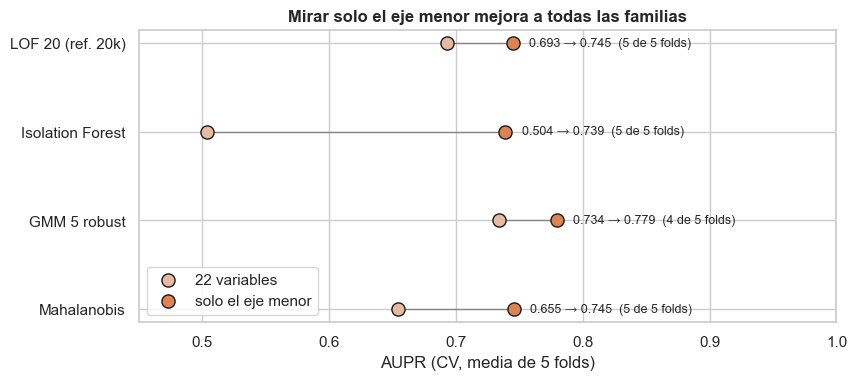

In [34]:
# 22 variables → solo el eje menor, por detector; a la derecha, en cuántos folds gana la versión del eje
ns_pares = {"Mahalanobis": ("Mahalanobis (22 var.)", "Mahalanobis · eje menor"),
            "GMM 5 robust": ("GMM 5 robust (22 var.)", "GMM 5 · eje menor"),
            "Isolation Forest": ("IF ψ=32768 (22 var.)", "IF · eje menor"),
            "LOF 20 (ref. 20k)": ("LOF 20 · ref. 20k (22 var.)", "LOF 20 · eje menor")}
ns_col22 = sns.light_palette(FAM[NS], n_colors=3)[1]
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (det, (a, b)) in enumerate(ns_pares.items()):
    ma, mb = RES[a]["media"], RES[b]["media"]
    ax.plot([ma, mb], [i, i], c="k", lw=1, alpha=.4, zorder=1)
    ax.scatter(ma, i, s=90, color=ns_col22, edgecolor="k", zorder=2, label="22 variables" if i == 0 else None)
    ax.scatter(mb, i, s=90, color=FAM[NS], edgecolor="k", zorder=2, label="solo el eje menor" if i == 0 else None)
    ax.annotate(f"{ma:.3f} → {mb:.3f}  ({int((por_fold(b) > por_fold(a)).sum())} de 5 folds)", (max(ma, mb), i),
                xytext=(12, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_yticks(range(len(ns_pares)), ns_pares)
ax.set(xlim=(.45, 1.0), xlabel="AUPR (CV, media de 5 folds)", title="Mirar solo el eje menor mejora a todas las familias")
ax.legend(loc="lower left");

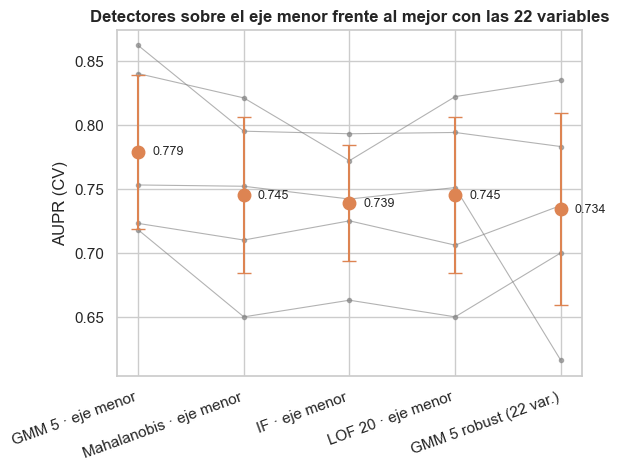

In [35]:
ns_eje = ["GMM 5 · eje menor", "Mahalanobis · eje menor", "IF · eje menor", "LOF 20 · eje menor", "GMM 5 robust (22 var.)"]
plot_folds(ns_eje, title="Detectores sobre el eje menor frente al mejor con las 22 variables");

In [36]:
# el mejor del bloque frente a los demás, fold a fold
ns_mejor = "GMM 5 · eje menor"
pd.Series({n: int((por_fold(ns_mejor) > por_fold(n)).sum()) for n in ns_eje[1:] + ["GMM 5 partida (21 crudas)"]},
          name=f"folds que gana {ns_mejor} (de 5)").to_frame().T

,Mahalanobis · eje menor,IF · eje menor,LOF 20 · eje menor,GMM 5 robust (22 var.),GMM 5 partida (21 crudas)
folds que gana GMM 5 · eje menor (de 5),5,4,5,4,5


> **Conclusión:** Con solo el eje menor mejoran los cuatro detectores: Mahalanobis de **0,655** a **0,745**, Isolation Forest de **0,504** a **0,739**, LOF de **0,693** a **0,745** y el GMM 5 robust de **0,734** a **0,779**. Isolation Forest es el caso más claro: con las 22 variables corta por ejes que no ven la dirección del fraude; con el eje menor como única variable pasa a estar entre los mejores. El mejor es el **GMM 5 sobre el eje menor, 0,779 ± 0,060**: gana a Mahalanobis sobre el eje en 5 de 5 folds (en el eje los normales son muy asimétricos y el GMM aprende esa forma, mientras que $z^2$ es simétrico) y al GMM de partida en los 5. A IF y LOF sobre el eje les saca 0,040 y 0,034 (menos de 1 std), pero lo repite en 4 y 5 de los 5 folds, y al GMM 5 robust con las 22 variables le gana en 4 de 5. → **Impacto:** **D-2.2**: la representación importa más que el detector. **GMM 5 · eje menor** (EjesPropios → RobustScaler → GMM 5 `full`) es el mejor no supervisado y la referencia que tiene que batir el bloque 3. En el 02 (§9–§11) se probaron también 2, 4 y 8 ejes, las top-k variables por AUPR univariante y combinaciones por rangos: ningún otro conjunto de variables lo superó, y las combinaciones subían como mucho +0,013, sin diferencia concluyente (tabla de 2.6).

### 2.5 ¿Se confirma en test, y qué fraudes se escapan?

**Qué miramos y por qué.** Las elecciones de 2.1–2.4 se han hecho con la CV. Ahora, y solo para confirmar, ajustamos los detectores del eje menor con **todos los normales de train** y puntuamos el test (51.266 filas, 89 fraudes), junto al GMM de partida. Después miramos los fraudes que el mejor detector **no** ve.

In [37]:
# ajuste con todos los normales de train → scores de test
ns_modelos = {"GMM 5 · eje menor": make_pipeline(EjesPropios(1), RobustScaler(), GaussianMixture(5, random_state=SEED)),
              "Mahalanobis · eje menor": make_pipeline(EjesPropios(1), Mahalanobis()),
              "IF · eje menor": make_pipeline(EjesPropios(1), ns_iforest()),
              "LOF 20 · eje menor": make_pipeline(EjesPropios(1), StandardScaler(), LOFRef(20))}
ns_sc_test = {n: score(fit(m, Xa, ya), X_test.to_numpy(float)) for n, m in ns_modelos.items()}
ns_sc_test["GMM 5 partida (21 crudas)"] = ns_prof["orden por row_id (este notebook)"]["score"]
ns_test = pd.DataFrame([report(n, s) for n, s in ns_sc_test.items()]).set_index("modelo")
ns_test.insert(0, "AUPR CV", [RES[n]["media"] for n in ns_test.index])
ns_test.round(3)

GMM 5 · eje menor: AUPR test=0.7363 | sin dup=0.7192 | ROC-AUC=0.9296
Mahalanobis · eje menor: AUPR test=0.6641 | sin dup=0.6396 | ROC-AUC=0.9231
IF · eje menor: AUPR test=0.6902 | sin dup=0.6670 | ROC-AUC=0.9324
LOF 20 · eje menor: AUPR test=0.6597 | sin dup=0.6351 | ROC-AUC=0.8810
GMM 5 partida (21 crudas): AUPR test=0.4949 | sin dup=0.4635 | ROC-AUC=0.9484


,AUPR CV,aupr,roc_auc,aupr_sin_dup
modelo,,,,
GMM 5 · eje menor,0.779,0.736,0.930,0.719
Mahalanobis · eje menor,0.745,0.664,0.923,0.640
IF · eje menor,0.739,0.690,0.932,0.667
LOF 20 · eje menor,0.745,0.660,0.881,0.635
GMM 5 partida (21 crudas),0.533,0.495,0.948,0.463


¿Es clara la mejora sobre el punto de partida? **Bootstrap estratificado** del test (1.000 réplicas): se remuestrean normales y fraudes por separado y en cada réplica se recalcula la AUPR de los dos modelos **con las mismas filas**, para medir también su diferencia.

In [38]:
ns_rng = np.random.default_rng(SEED)
ns_par = ["GMM 5 · eje menor", "GMM 5 partida (21 crudas)"]
ns_i0, ns_i1 = np.flatnonzero(y_te == 0), np.flatnonzero(y_te == 1)
ns_boot = []
for _ in range(1000):
    ns_ib = np.r_[ns_rng.choice(ns_i0, len(ns_i0)), ns_rng.choice(ns_i1, len(ns_i1))]
    ns_boot.append([average_precision_score(y_te[ns_ib], ns_sc_test[n][ns_ib]) for n in ns_par])
ns_boot = pd.DataFrame(ns_boot, columns=ns_par).assign(diferencia=lambda b: b[ns_par[0]] - b[ns_par[1]])
ns_ic = ns_boot.quantile([.025, .975]).T.set_axis(["p2,5", "p97,5"], axis=1)
ns_ic.insert(0, "AUPR test", [ns_test.loc[n, "aupr"] for n in ns_par] + [ns_test.loc[ns_par[0], "aupr"] - ns_test.loc[ns_par[1], "aupr"]])
ns_ic["% réplicas > 0"] = ["", "", f"{100 * (ns_boot['diferencia'] > 0).mean():.1f}"]
ns_ic.round(3)

,AUPR test,"p2,5","p97,5",% réplicas > 0
GMM 5 · eje menor,0.736,0.642,0.822,
GMM 5 partida (21 crudas),0.495,0.400,0.589,
diferencia,0.241,0.159,0.324,100.0


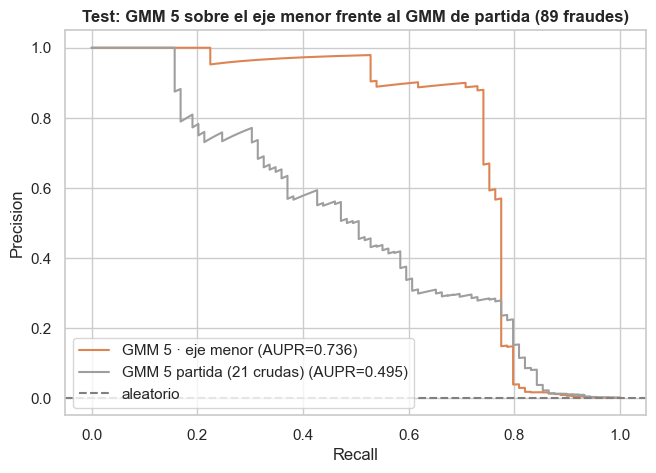

In [39]:
ax = plot_pr(y_test, {n: ns_sc_test[n] for n in ns_par}, ax=plt.subplots(figsize=(7.5, 5))[1])
ax.get_lines()[0].set_color(FAM[NS]); ax.get_lines()[1].set_color(C[0])
ax.legend(loc="lower left")
ax.set(title="Test: GMM 5 sobre el eje menor frente al GMM de partida (89 fraudes)");

La curva del mejor detector mantiene la precisión alta hasta un recall de ~0,75–0,8 y luego cae en vertical: el último tramo de fraudes **no se distingue de los normales**. Lo medimos en train con los scores *out-of-fold* (sin tocar más el test): un fraude se "ve" si su score supera el **p99 de los normales de su fold** (un 1 % de falsas alarmas). A la derecha, los fraudes en el plano de 2.3, separados en vistos y no vistos:

In [40]:
# fraudes de train que el GMM 5 · eje menor ve con un 1 % de falsas alarmas (scores OOF, umbral por fold)
ns_visto = np.zeros(len(ya), bool)
for _, iv in cv_splits:
    s = OOF[ns_mejor][iv]
    ns_visto[iv] = s > np.quantile(s[ya[iv] == 0], .99)
ns_f = ya == 1
ns_esc = ns_f & ~ns_visto
pd.Series({"fraudes de train": int(ns_f.sum()), "vistos (score > p99 de los normales del fold)": int(ns_visto[ns_f].sum()),
           "se escapan": int(ns_esc.sum()), "% que se escapa": round(100 * ns_esc.sum() / ns_f.sum(), 1),
           "de ellos, dentro de la banda de los normales (2.3)": int((np.abs(ns_z[ns_esc]) <= ns_banda).sum())},
          name=ns_mejor).to_frame().T

,fraudes de train,vistos (score > p99 de los normales del fold),se escapan,% que se escapa,"de ellos, dentro de la banda de los normales (2.3)"
GMM 5 · eje menor,206.0,170.0,36.0,17.5,36.0


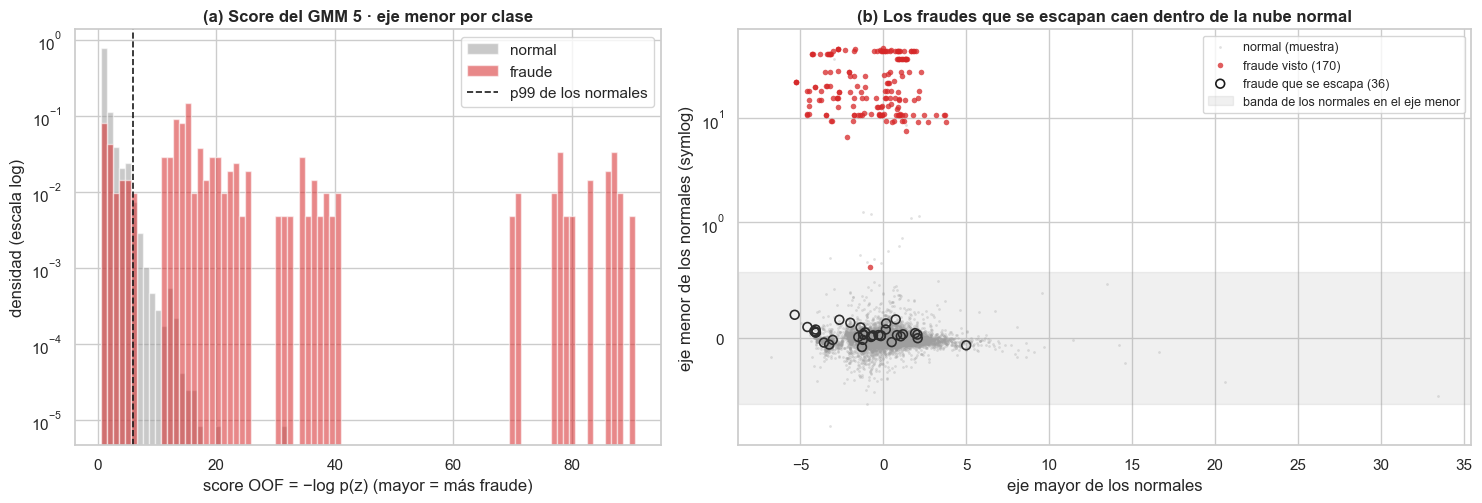

In [41]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
# (a) score OOF por clase, con el p99 global de los normales como referencia
s = OOF[ns_mejor]
bins = np.linspace(np.quantile(s, .001), s.max(), 90)
for k in (0, 1):
    a1.hist(s[ya == k], bins=bins, density=True, alpha=.55, color=C[k], label=LBL[k])
a1.axvline(np.quantile(s[ya == 0], .99), c="k", ls="--", lw=1.2, label="p99 de los normales")
a1.set(yscale="log", xlabel="score OOF = −log p(z) (mayor = más fraude)", ylabel="densidad (escala log)",
       title="(a) Score del GMM 5 · eje menor por clase")
a1.legend()
# (b) plano de 2.3: los fraudes que se escapan están dentro de la nube de normales
a2.scatter(*ns_P[ns_m].T, s=4, c=C[0], alpha=.3, linewidths=0, label="normal (muestra)")
a2.scatter(*ns_P[ns_f & ns_visto].T, s=16, c=C[1], alpha=.75, linewidths=0, label=f"fraude visto ({(ns_f & ns_visto).sum()})")
a2.scatter(*ns_P[ns_esc].T, s=40, facecolor="none", edgecolor="k", linewidths=1.2, label=f"fraude que se escapa ({ns_esc.sum()})")
a2.axhspan(-ns_banda, ns_banda, color=C[0], alpha=.15, label="banda de los normales en el eje menor")
a2.set_yscale("symlog", linthresh=1)
a2.set(xlabel="eje mayor de los normales", ylabel="eje menor de los normales (symlog)",
       title="(b) Los fraudes que se escapan caen dentro de la nube normal")
a2.legend(loc="upper right", fontsize=9)
fig.tight_layout();

In [42]:
# ¿en qué se diferencian? mediana de la coordenada z y de las variables con más peso en el eje (estandarizadas)
ns_grupo = pd.Series(np.where(ya == 0, "normales", np.where(ns_visto, "fraudes vistos", "fraudes que se escapan")))
ns_perfil = pd.DataFrame(ns_sc.transform(Xa), columns=FEATURES)[["X17", "X14", "X12", "X10", "X4"]].assign(
    z_eje_menor=ns_z, Amount=tr["Amount"].to_numpy())
ns_perfil.groupby(ns_grupo).median().assign(n=ns_grupo.value_counts()).loc[
    ["normales", "fraudes vistos", "fraudes que se escapan"]].round(2)

,X17,X14,X12,X10,X4,z_eje_menor,Amount,n
normales,-0.11,0.04,0.14,-0.10,-0.01,-0.01,33.25,119412
fraudes vistos,-9.41,-9.47,-7.36,-5.38,3.70,18.19,17.08,170
fraudes que se escapan,1.00,-1.08,-0.36,-0.32,1.48,0.03,4.27,36


> **Conclusión:** El test confirma la CV: el **GMM 5 · eje menor** da **0,736** en test (**0,719** sin las filas duplicadas de train), frente a 0,779 en CV, y sigue siendo el mejor de los detectores del eje. La mejora sobre el GMM de partida (**0,495** en el mismo test) es clara: **+0,241**, IC 95 % **0,159–0,324**, positiva en el **100 %** de las réplicas. Pero tiene un techo: con un 1 % de falsas alarmas se escapan **36 de 206** fraudes de train (**17,5 %, ~1 de cada 6**), y los 36 de ellos caen dentro de la banda de los normales en el eje menor. Son fraudes que **no son raros**: su coordenada en el eje (mediana 0,03) es la de un normal, porque sus variables del eje están cerca de las de un normal y se compensan (X17 en +1,00 frente a −9,41 en los fraudes vistos, X14 en −1,08), con importes pequeños (mediana 4,27 € frente a 33,25 € de los normales). Ningún detector de rareza los puede ver, porque para cualquier medida de rareza son normales (en el 02, §11, los nueve finalistas juntos dejaban sin ver 26 de 206 con el mismo criterio). → **Impacto:** el techo del no supervisado está en ~0,74 de test. Lo que queda por ganar son fraudes que solo se distinguen **por parecerse a otros fraudes**, y eso solo lo pueden aprender las etiquetas: es la pregunta del bloque 3.

### 2.6 Qué más probamos (notebook 02)

Todo lo que se probó en el notebook de trabajo `02_baselines_no_supervisados` y no se re-ejecuta aquí, con sus cifras (AUPR media de CV en 5 folds, ± std cuando importa; test cuando se indica). Las re-ejecutadas arriba coinciden con estas.

| Experimento (sección del 02) | Resultado | Conclusión |
|---|---|---|
| Ruido de la AUPR por fold (02 §1) | Mahalanobis: 0,554–0,749 según el fold; bootstrap dentro de cada fold con bandas p5–p95 de 0,18–0,26 | Regla del bloque: < ~1 std (≈ 0,08) no es concluyente salvo 4 de 5 folds; el test solo confirma |
| GMM 5 con el preprocesado paso a paso (02 §2) | crudo 0,533 → `log1p_Amount` 0,637 ± 0,130 → + `amount_freq` 0,638 ± 0,079 (gana al crudo en 5 de 5); el 84 % de los fraudes supera el p99 de los normales | `FEATURES` como conjunto por defecto (D-1.2, D-1.4) |
| Euclídea al centroide (02 §3) | 0,316 ± 0,065; pierde con Mahalanobis (0,655) en 5 de 5; supera el p99,9 de los normales el 34 % de los fraudes frente al 77 % con Mahalanobis | Descartada: no pesa el eje menor |
| Mahalanobis robusta (MCD, 20k normales) (02 §3) | 0,384 ± 0,205; su elipse deja fuera al 56,7 % de los normales (la clásica, al 5,9 %) | Covarianza clásica: las colas de los normales son normales, no ruido |
| GMM 5 · 3 escaladores × 3 semillas (02 §4) | sin escalar 0,634–0,642; standard 0,660–0,700; robust 0,734–0,749 (robust > standard en 4, 4 y 5 folds) | RobustScaler en densidad (D-1.2) |
| GMM 5 con arranque aleatorio (02 §4) | 0,646 con los tres escaladores | EM es invariante a la escala; el k-means de arranque no |
| Nº de componentes (robust) (02 §4) | K = 1: 0,655 · 2: 0,641 · 3: 0,733 · 5: 0,734 · 7: 0,636 · 10: 0,731 (K = 10 standard 0,678, sin escalar 0,537); la verosimilitud de los normales mejora siempre con K | K = 5; un criterio no supervisado (BIC) habría elegido el modelo más grande |
| Tipo de covarianza (02 §4) | `full` 0,734 · `tied` 0,652 · `diag` 0,512 | `full`: el fraude es una anomalía dependiente |
| kNN-distancia, k = 1–50, 20k normales (02 §5) | standard: 0,424 (k = 1), 0,531 (10), **0,533** (20), 0,493 (50); robust 0,293–0,393 (pierde en 5 de 5) | Vecindad con StandardScaler; kNN 22 var. < Mahalanobis en 5 de 5 |
| LOF, k = 10 / 20 / 50, 20k normales (02 §5) | 0,572 ± 0,161 / **0,693** / 0,684; k = 20 con robust 0,686 | k = 20 |
| Referencia de LOF (02 §5) | todos los normales 0,073; deduplicados 0,123; dedup + 20k con k = 5: 0,197, con k = 20: 0,692 | Manda k / n, no los duplicados: submuestra de 20k sin deduplicar (D-2.3) |
| Isolation Forest, ψ = 256–32.768 y `max_features` 1 / 0,5 (02 §6) | 0,276 (ψ = 256) → 0,340 → 0,434 → **0,504** (ψ = 32.768); con `max_features` 0,5: 0,340–0,502 | Más submuestra, mejor; aun así lejos de la densidad |
| Isolation Forest con otros ejes (02 §6) | 22 ejes propios (rotado) 0,148; 22 variables + eje menor 0,600; solo eje menor 0,738 ± 0,045 | La información está en la combinación, no en una variable |
| One-Class SVM (02 §6) | RBF `nu` = 0,01: standard 0,509 ± 0,072, robust 0,426; Nystroem 300 + `SGDOneClassSVM` 0,392 | Ni envolver ni aislar llegan a la densidad con 22 variables; coste alto |
| PCA-reconstrucción, k = 2–21 (02 §7) | standard: 0,326 (k = 2) … 0,542 (18), 0,730 (20), **0,745 ± 0,061** (21); robust: 0,220 (2), 0,635 (8), 0,741 (18), 0,743 (21) | Solo funciona cuando lo descartado es el eje menor (PCA 21 = Mahalanobis sobre el eje) |
| Autoencoder 22 → 16 → c → 16 → 22 (PyTorch, 40k normales, robust) (02 §7) | código 4: 0,674 · 8: 0,678 · 12: 0,707 ± 0,062; pierde con PCA 21 en 5 de 5; test 0,630. No se re-ejecuta (sin PyTorch en el entorno de entrega) | Reconstruye mejor que PCA con la misma dimensión, pero importa **qué** se pierde, no cuánto |
| HBOS 5–100 bins (02 §8) | 0,436–0,475 (mejor 10 bins) | El supuesto de independencia cuesta |
| ECOD (02 §8) | 22 variables 0,583 ± 0,076; solo eje menor 0,661 (satura: el 31,7 % de los fraudes cae más allá del normal más extremo) | Suma colas de variables sin señal |
| Rareza variable a variable (02 §8, diagnóstico) | X17 sola 0,708 en el fold 0, más que ECOD con 22 (0,677); \|correlación\| media entre X17, X14, X10, X12, X11 y X16: 0,103 en normales y 0,774 en fraudes | La señal es conjunta: se mueve en grupo en el fraude |
| Top-k por AUPR univariante (02 §9) | el conjunto top 4 / 6 / 8 calculado dentro de cada fold es el mismo en los 5 folds (sin fuga). Top 4: kNN 0,745, LOF 0,739, ECOD 0,733, GMM 0,729, IF 0,718, Mahalanobis 0,717, HBOS 0,712. Top 4 + importe: LOF 0,750, ECOD **0,748**, kNN 0,746 | Quitar variables mejora a todos; ECOD elige top 4 + importe |
| m ejes menores, m = 1 / 2 / 4 / 8 (02 §9) | GMM 0,779 / 0,624 / 0,726 / 0,620 · LOF 0,745 / 0,748 / **0,752** / 0,721 · kNN 0,746 / 0,744 / 0,731 / 0,733 · Mahalanobis 0,745 / 0,739 / 0,709 / 0,704 · IF 0,738 / 0,734 / 0,537 / 0,352 · HBOS 0,738 / 0,715 / 0,259 / 0,191 · ECOD 0,661 / 0,316 / 0,100 / 0,073 | Con un eje basta; los detectores variable a variable se hunden con más ejes |
| GMM 5 · eje menor con otras semillas (02 §9) | 0,784 ± 0,058 y 0,787 ± 0,057 (semilla 42: 0,779 ± 0,060) | Estable frente a la inicialización |
| Comparación por pares de 9 finalistas (02 §10) | GMM 5 · eje menor gana de forma concluyente a 8 de 10; a LOF 20 · 4 ejes (0,752) y ECOD · top 4 + importe (0,748) solo en 3 de 5 folds | Grupo de cabeza de tres familias sin ganador claro; se elige el GMM por media y coste |
| Finalistas en test (02 §12) | GMM eje **0,736** · HBOS eje 0,707 · IF eje 0,690 · ECOD top 4 + importe 0,683 · LOF 4 ejes 0,671 · kNN eje 0,664 · PCA 21 0,664 · AE 12 0,630 · GMM 5 full robust 0,617 · Mahalanobis 0,579 · GMM partida 0,495. Los 11 bajan en test (mediana −0,075); Spearman CV–test 0,755 | El test confirma la CV: el mejor de CV es el mejor en test |
| Correlación y captura (02 §11) | bloque del eje menor (GMM, kNN, PCA 21, IF) con ρ de Spearman 0,83–0,96 y los mismos 170 fraudes; los 9 finalistas juntos ven 180 de 206 (87,4 %); 26 no los ve ninguno | Ven casi lo mismo |
| Combinaciones por rangos (02 §11) | 0,785–0,793 (la mejor, GMM eje + ECOD top 4); un control sin diversidad (GMM eje + IF eje) da 0,787 | Sin ensemble no supervisado (D-2.4) |
| Explicación de las alertas (02 §13) | umbral p99,9 de los normales = salir del tramo −0,54 < z < 0,55 del eje; lo supera el 81,6 % de los fraudes y el 0,1 % de los normales; cada alerta se descompone en $w_j \tilde x_j$. 12 fraudes de 149,98 € en la misma zona del eje que 11 normales | Cada alerta del no supervisado se explica sin LIME ni SHAP |
| Scores para el híbrido (02 §14) | 5 scores con ρ ≤ 0,46 (GMM eje, LOF 4 ejes, ECOD top 4, GMM 5 full, AE 12), *out-of-fold* en train | Se usan en el bloque 4 (D-2.4) |

### 2.7 Conclusiones del bloque

In [43]:
# resumen del bloque: CV de todo lo re-ejecutado aquí y test de los detectores del eje menor
ns_tabla = tabla_cv([n for n in RES if n in set(ns_eje) | {"GMM 5 partida (21 crudas)", "Mahalanobis (22 var.)", "GMM 5 standard (22 var.)",
                                                            "IF ψ=32768 (22 var.)", "LOF 20 · ref. 20k (22 var.)"}])
ns_tabla = ns_tabla[["media", "std"]].join(ns_test[["aupr", "aupr_sin_dup"]].rename(columns={"aupr": "AUPR test", "aupr_sin_dup": "test sin dup"}))
print(f"Bloque 2 ejecutado en {time.time() - ns_t0:.0f} s")
ns_tabla.rename(columns={"media": "AUPR CV", "std": "std CV"}).round(3)

Bloque 2 ejecutado en 176 s


,AUPR CV,std CV,AUPR test,test sin dup
GMM 5 · eje menor,0.779,0.060,0.736,0.719
Mahalanobis · eje menor,0.745,0.061,0.664,0.640
LOF 20 · eje menor,0.745,0.061,0.660,0.635
IF · eje menor,0.739,0.045,0.690,0.667
GMM 5 robust (22 var.),0.734,0.075,NaN,NaN
LOF 20 · ref. 20k (22 var.),0.693,0.082,NaN,NaN
GMM 5 standard (22 var.),0.660,0.094,NaN,NaN
Mahalanobis (22 var.),0.655,0.076,NaN,NaN
GMM 5 partida (21 crudas),0.533,0.077,0.495,0.463
IF ψ=32768 (22 var.),0.504,0.073,NaN,NaN


- **Punto de partida:** el GMM 5 del profesor da **0,533 ± 0,077** en CV y **0,495** en test (0,567 con su orden de filas: la inicialización por k-means depende del orden).
- **Densidad, y con RobustScaler:** con las 22 variables del bloque 0, Mahalanobis da 0,655 y el GMM 5 `full` 0,734 con RobustScaler frente a 0,660 con StandardScaler: el escalador cambia el arranque de EM, no el modelo (D-1.2).
- **La señal vive en el eje menor de los normales** (varianza 0,16; X17, X12, X14, X10… a la vez). Mirar solo esa coordenada mejora a todas las familias: IF 0,504 → 0,739, LOF 0,693 → 0,745, GMM 0,734 → 0,779. La representación importa más que el detector (D-2.2).
- **Mejor no supervisado: GMM 5 · eje menor, 0,779 ± 0,060 en CV y 0,736 en test** (IC 95 % de la mejora sobre el profesor 0,159–0,324). Es la referencia del bloque 3 (D-2.4).
- **Techo:** ~1 de cada 6 fraudes (36 de 206 en train) está dentro de la nube de normales; ningún detector de rareza los ve.

**Qué pasa al bloque 3:** la pregunta ya no es si las etiquetas ayudan, sino si un clasificador supervisado recupera esos fraudes "normales" sin perder lo que el eje menor ya ordena bien. Tiene que batir **0,779 en CV y 0,736 en test**.

---
## 3. Enfoque supervisado

**Pregunta del bloque: ¿cuánto ayudan las etiquetas de fraude?** El bloque 2 midió hasta dónde llega la detección de anomalías pura, que aprende solo lo normal. Aquí usamos lo que dejó fuera: las **206 etiquetas de fraude de train**. Un clasificador no pregunta "¿es rara esta transacción?", sino "¿se parece a los fraudes que ya hemos visto?". Con etiquetas, supervisado y no supervisado se acercan, y lo que decide es **el tipo de anomalía**: hay que medirlo.

**Referencia a batir (bloque 2):** el **GMM 5 · eje menor**, **0,779 ± 0,060** de AUPR en CV y 0,736 en test. Aquí no se recalcula: se citan su media y su AUPR en cada fold (las del notebook 02, con los mismos folds). El bloque 2 dejó dos pistas: la señal se concentra en el eje de menor varianza de los normales, y ~1/6 de los fraudes caen dentro de la nube normal, donde ningún detector de rareza los ve. Es lo que el supervisado tiene que recuperar.

**Cómo se compara.** Mismo protocolo que en todo el notebook: `evaluar()` con los 5 folds por grupo. Los clasificadores se ajustan con **todas** las filas del fold de train, fraudes incluidos (~165 por fold); los fraudes de validación no se ven nunca al ajustar. Una diferencia de medias menor que ~1 std entre folds (≈ 0,06) **no es concluyente**, salvo que se repita en al menos **4 de los 5 folds**. El test (89 fraudes) solo se usa al final (§3.6), una vez, para confirmar.

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Referencia del bloque 2 (GMM 5 · eje menor): AUPR por fold citada del notebook 02/03, mismos 5 folds
REF3 = "GMM 5 · eje menor (bloque 2)"
REF3_FOLDS = np.array([0.840, 0.753, 0.718, 0.723, 0.862])   # media 0,779 ± 0,060

def frente_a3(nombres, ref):
    """Diferencia por pares con la referencia (nombre en RES o vector de 5 AUPR): media, peor fold y folds que gana."""
    r = por_fold(ref) if isinstance(ref, str) else np.asarray(ref)
    return pd.DataFrame({n: {"media": RES[n]["media"], "std": RES[n]["std"], "dif. media": (por_fold(n) - r).mean(),
                             "peor fold": (por_fold(n) - r).min(), "folds que gana (de 5)": int((por_fold(n) > r).sum())}
                         for n in nombres}).T.astype(float).round(3).astype({"folds que gana (de 5)": int})

# Configuración de XGBoost elegida en el 03 (§6, D-2.5): árboles de profundidad 3, sin reequilibrar
XGB3 = lambda **kw: xgb.XGBClassifier(**{**dict(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8,
                                               colsample_bytree=0.7, random_state=SEED, n_jobs=N_JOBS), **kw})
LR3 = lambda **kw: make_pipe(LogisticRegression(max_iter=3000, **kw))      # escalado dentro de cada fold
t0_b3 = time.time()

### 3.1 ¿Basta un modelo lineal?

**Qué miramos y por qué.** El clasificador más simple: una **regresión logística**, una frontera plana sobre las 22 variables estandarizadas (el escalador se ajusta dentro de cada fold). Si el fraude saliera por una sola dirección, como el eje menor del bloque 2, un hiperplano debería bastar en buena parte. Usamos `C=0.1` (algo de regularización L2: con ~165 fraudes por fold, menos libertad generaliza mejor) y la probamos también con `class_weight="balanced"`, que multiplica por ~580 el peso de cada fraude: la forma "barata" de tratar el desbalanceo (§3.4 lo trata entero).

In [45]:
evaluar("LR C=0.1", LR3(C=0.1), "lineal")
evaluar("LR C=0.1 balanced", LR3(C=0.1, class_weight="balanced"), "lineal")
frente_a3(["LR C=0.1", "LR C=0.1 balanced"], REF3_FOLDS)

LR C=0.1: CV AUPR = 0.781 ± 0.073  (1 s)


LR C=0.1 balanced: CV AUPR = 0.768 ± 0.091  (1 s)


,media,std,dif. media,peor fold,folds que gana (de 5)
LR C=0.1,0.781,0.073,0.002,-0.068,3
LR C=0.1 balanced,0.768,0.091,-0.012,-0.104,3


> **Conclusión:** la logística llega al nivel de la referencia, pero no la supera: **0,781** con `C=0.1`, ganando al GMM eje en **3 de 5** folds (no concluyente). Pesar los fraudes no ayuda (**0,768**): sube el score de todos los fraudes, pero la AUPR solo depende del orden, y el orden apenas cambia. → **Impacto:** con las etiquetas, un hiperplano iguala al mejor detector no supervisado, pero no lo mejora. Para ir más allá hace falta una frontera no lineal.

### 3.2 ¿Y con árboles?

**Qué miramos y por qué.** Los árboles cortan el espacio en cajas, así que pueden aislar regiones que un hiperplano no separa, por ejemplo los fraudes "dentro de la nube" con importes bajos y X4 alta. Además no necesitan escalado. Un representante de cada familia:

- **Bagging:** `RandomForest` de 300 árboles profundos e independientes, promediados (`min_samples_leaf=2`, para que una hoja no sea un único fraude).
- **Boosting:** `XGBoost` con árboles de profundidad 3 en secuencia, cada uno corrigiendo los errores de los anteriores (`n_estimators=400`, `learning_rate=0.05`, submuestreo del 80 % de filas y del 70 % de columnas). Es la configuración que eligió el 03 tras un barrido corto (ver la tabla de §3.8).

In [46]:
evaluar("Random Forest 300", RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), "bagging")
evaluar("XGBoost d3", XGB3(), "boosting")
frente_a3(["LR C=0.1", "Random Forest 300", "XGBoost d3"], REF3_FOLDS)

Random Forest 300: CV AUPR = 0.851 ± 0.060  (39 s)


XGBoost d3: CV AUPR = 0.858 ± 0.060  (6 s)


,media,std,dif. media,peor fold,folds que gana (de 5)
LR C=0.1,0.781,0.073,0.002,-0.068,3
Random Forest 300,0.851,0.060,0.072,0.039,5
XGBoost d3,0.858,0.060,0.078,0.035,5


> **Conclusión:** los dos modelos de árboles superan a la referencia en los **5 folds**, y con margen (su peor fold mejora al GMM en +0,035 a +0,039): XGBoost d3 llega a **0,858** (**+0,078** sobre el GMM eje) y Random Forest a **0,851**. Es la primera mejora concluyente del proyecto: la frontera no lineal separa fraudes que ni la densidad ni el hiperplano separaban. → **Impacto:** el boosting es el candidato principal. Antes de cerrarlo, §3.3 explica por qué la otra librería de boosting habitual, LightGBM, falla con sus parámetros por defecto.

### 3.3 ¿Por qué LightGBM por defecto se hunde?

**Qué miramos y por qué.** LightGBM es la alternativa natural a XGBoost, pero con sus parámetros por defecto da una AUPR muy baja. Un resultado así no se descarta sin entenderlo: puede esconder un error del protocolo, o un problema que también afecte a XGBoost.

In [47]:
LGB3 = lambda **kw: lgb.LGBMClassifier(**{**dict(verbose=-1, n_jobs=N_JOBS, random_state=SEED), **kw})
evaluar("LightGBM por defecto", LGB3(), "boosting");

LightGBM por defecto: CV AUPR = 0.145 ± 0.061  (2 s)


Si fuera sobreajuste, la AUPR de **train** seguiría subiendo con las iteraciones mientras la de validación baja. En el fold 0, iteración a iteración:

In [48]:
it0, iv0 = cv_splits[0]
m_lgb0 = LGB3().fit(Xa[it0], ya[it0])
curva_lgb = pd.DataFrame({k: {"AUPR train": average_precision_score(ya[it0], m_lgb0.predict_proba(Xa[it0], num_iteration=k)[:, 1]),
                              "AUPR validación": average_precision_score(ya[iv0], m_lgb0.predict_proba(Xa[iv0], num_iteration=k)[:, 1])}
                          for k in [1, 5, 10, 20, 30, 50, 100]}).T.rename_axis("iteraciones")
curva_lgb.round(3).T

iteraciones,1,5,10,20,30,50,100
AUPR train,0.856,0.703,0.742,0.749,0.407,0.268,0.238
AUPR validación,0.868,0.641,0.591,0.585,0.328,0.200,0.242


El boosting con log-loss da a cada hoja el valor $-\sum g / (\sum h + \lambda)$ (un paso de Newton), donde $h = p(1-p)$ es la hessiana de cada fila. Tras pocas iteraciones casi todos los normales tienen $p \approx 0$, así que $h \approx 0$, y una hoja con pocos fraudes y una hessiana total minúscula recibe un valor enorme. LightGBM solo exige `min_child_weight` ($\sum h$ mínima por hoja) de **0,001**; XGBoost exige **1**. Barrido de ese único parámetro:

In [49]:
MCW = [0.01, 0.1, 1, 5]
for mcw in MCW:
    evaluar(f"LightGBM min_child_weight={mcw}", LGB3(min_child_weight=mcw), "boosting")

LightGBM min_child_weight=0.01: CV AUPR = 0.597 ± 0.126  (2 s)


LightGBM min_child_weight=0.1: CV AUPR = 0.780 ± 0.100  (2 s)


LightGBM min_child_weight=1: CV AUPR = 0.796 ± 0.094  (2 s)


LightGBM min_child_weight=5: CV AUPR = 0.862 ± 0.061  (2 s)


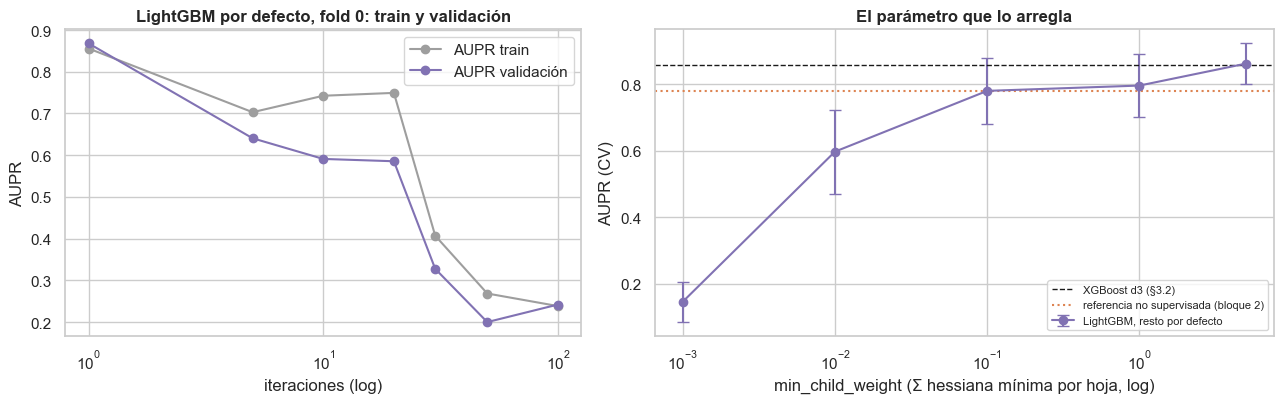

In [50]:
LGBS3 = ["LightGBM por defecto", *[f"LightGBM min_child_weight={m}" for m in MCW]]
t_lgb = tabla_cv(LGBS3).loc[LGBS3]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
curva_lgb.plot(ax=a1, marker="o", color=[C[0], FAM["boosting"]], logx=True)
a1.set(xlabel="iteraciones (log)", ylabel="AUPR", title="LightGBM por defecto, fold 0: train y validación")
a2.errorbar([0.001, *MCW], t_lgb["media"], yerr=t_lgb["std"], marker="o", capsize=4, c=FAM["boosting"], label="LightGBM, resto por defecto")
a2.axhline(RES["XGBoost d3"]["media"], ls="--", c="k", lw=1, label="XGBoost d3 (§3.2)")
a2.axhline(REF3_FOLDS.mean(), ls=":", c=FAM["no supervisado"], lw=1.5, label="referencia no supervisada (bloque 2)")
a2.set(xscale="log", xlabel="min_child_weight (Σ hessiana mínima por hoja, log)", ylabel="AUPR (CV)", title="El parámetro que lo arregla")
a2.legend(fontsize=8, loc="lower right")
fig.tight_layout();

> **Conclusión:** LightGBM por defecto da **0,145**, porque **diverge**: en el fold 0, la AUPR de **train** también se hunde (de **0,856** con 1 iteración a **0,238** en su peor punto). No es sobreajuste, es inestabilidad numérica. Subir solo `min_child_weight` lo recupera de forma casi monótona (**0,597 → 0,780 → 0,796 → 0,862** con 0,01, 0,1, 1 y 5), y con 5 queda empatado con XGBoost d3 (**0,858**; LightGBM gana en 3 de 5 folds). → **Impacto:** con un 0,17 % de positivos, la hessiana mínima por hoja es un parámetro crítico, no un detalle: en boosting, `min_child_weight` ≥ 1 es obligatorio (D-2.6). XGBoost y LightGBM son equivalentes una vez configurados; seguimos con **XGBoost**, cuyos valores por defecto ya son estables (LightGBM vuelve como componente de la mezcla del bloque 4).

### 3.4 ¿Hay que tratar el desbalanceo?

**Qué miramos y por qué.** Con 1 fraude por cada ~580 normales, la receta habitual es reequilibrar: **undersampling** (tira información), **oversampling** o **SMOTE** (fraudes sintéticos interpolados entre vecinos). Pero la AUPR solo depende del **orden** de los scores, no de su calibración: reequilibrar cambia las probabilidades, y solo ayuda si cambia también qué fraudes quedan por encima de qué normales. Re-ejecutamos el **peso de clase** sobre el XGBoost d3 (`scale_pos_weight` = 10 y 50; el "balanceado" sería ~580); la logística con `balanced` ya está en §3.1. SMOTE y undersampling necesitan `imblearn`, que no forma parte de este entorno: sus cifras del 03 (§5) van debajo de la tabla.

In [51]:
for w in [10, 50]:
    evaluar(f"XGBoost d3 · peso fraude ×{w}", XGB3(scale_pos_weight=w), "boosting")
DESB3 = ["XGBoost d3 · peso fraude ×10", "XGBoost d3 · peso fraude ×50"]
pd.concat([frente_a3(DESB3, "XGBoost d3"), frente_a3(["LR C=0.1 balanced"], "LR C=0.1")]).rename(columns={"dif. media": "dif. con el modelo sin pesar"})

XGBoost d3 · peso fraude ×10: CV AUPR = 0.861 ± 0.056  (6 s)


XGBoost d3 · peso fraude ×50: CV AUPR = 0.857 ± 0.056  (6 s)


,media,std,dif. con el modelo sin pesar,peor fold,folds que gana (de 5)
XGBoost d3 · peso fraude ×10,0.861,0.056,0.003,-0.002,4
XGBoost d3 · peso fraude ×50,0.857,0.056,-0.000,-0.006,1
LR C=0.1 balanced,0.768,0.091,-0.013,-0.058,3


**Remuestreo (notebook 03 §5, con `imblearn`, aplicado solo al fold de train dentro de un `Pipeline`; sobre el XGBoost de profundidad 4, 0,863):**

| Tratamiento | AUPR CV | Diferencia con el XGBoost sin tratar | Folds que gana (de 5) | Peor fold |
|---|---|---|---|---|
| SMOTE hasta un 5 % de fraudes | 0,851 ± 0,079 | −0,012 | 2 | −0,041 |
| Undersampling de normales hasta un 2 % de fraudes (~8.000 de ~95.000) | 0,830 ± 0,101 | −0,033 | 1 | −0,123 |

> **Conclusión:** ningún tratamiento mejora al modelo sin tratar. En XGBoost, el peso ×10 da **0,861** frente a **0,858** sin pesar (+0,003, gana en 4 de 5 folds) y el ×50 **0,857** (gana en 1). Esos +0,003 son del tamaño de lo que mueve la semilla (rango de 0,003 entre semillas en el 03 §6), y en el 03 el mismo ×10 sobre el XGBoost d4 ganaba solo en 2 de 5 folds: no es una mejora real, y con más peso ya empeora. En la logística, `balanced` baja de 0,781 a **0,768** (−0,013). SMOTE baja (−0,012) y el undersampling es el peor (−0,033, hasta −0,123 en un fold): tira el ~92 % de los normales, justo la información que define la frontera. → **Impacto:** **no se reequilibra** (D-2.6). Con la AUPR como métrica y un modelo que ya ordena bien, el desbalanceo no es un problema de pesos; solo importaba en LightGBM (§3.3), como problema numérico, y se resolvía con un parámetro, no remuestreando.

### 3.5 ¿Qué modelo gana, fold a fold?

**Qué miramos y por qué.** Los mejores de cada familia en una sola figura. Cada línea gris une el mismo fold en todos los modelos: si las líneas no se cruzan, la diferencia es robusta y no depende de qué fraudes cayeron en cada fold. La referencia del bloque 2 se dibuja con sus AUPR por fold citadas.

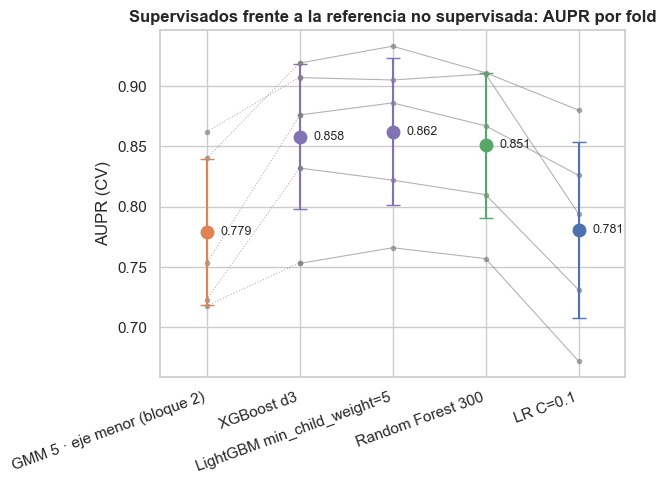

In [52]:
FIN3 = ["XGBoost d3", "LightGBM min_child_weight=5", "Random Forest 300", "LR C=0.1"]
ax = plot_folds(FIN3, title="Supervisados frente a la referencia no supervisada: AUPR por fold")
for k in range(5):
    ax.plot([-1, 0], [REF3_FOLDS[k], RES["XGBoost d3"][f"fold{k}"]], c="grey", lw=.8, alpha=.6, ls=":", marker=".")
ax.errorbar(-1, REF3_FOLDS.mean(), yerr=REF3_FOLDS.std(), fmt="o", ms=9, capsize=5, c=FAM["no supervisado"])
ax.annotate(f"{REF3_FOLDS.mean():.3f}", (-1, REF3_FOLDS.mean()), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xticks(range(-1, len(FIN3)), [REF3, *FIN3], rotation=20, ha="right")
ax.set_xlim(-1.5, len(FIN3) - .5);

In [53]:
frente_a3(FIN3, "XGBoost d3").drop(index="XGBoost d3").rename(columns={"dif. media": "dif. con XGBoost d3"})

,media,std,dif. con XGBoost d3,peor fold,folds que gana (de 5)
LightGBM min_child_weight=5,0.862,0.061,0.005,-0.010,3
Random Forest 300,0.851,0.060,-0.007,-0.022,2
LR C=0.1,0.781,0.073,-0.077,-0.113,0


> **Conclusión:** los tres modelos de árboles forman un grupo de cabeza sin diferencias concluyentes entre ellos: **XGBoost d3** da **0,858 ± 0,060**, LightGBM con `min_child_weight=5` (el mismo tipo de modelo en otra librería) **0,862** (+0,005, gana en 3 de 5 folds) y Random Forest **0,851** (−0,007, el XGBoost le gana en 3 de 5). La logística queda muy por detrás (−0,077, pierde en los 5 folds). Frente a la referencia del bloque 2, el XGBoost gana en los **5 folds** (**+0,078** de media; su peor fold mejora al GMM en +0,035). Nos quedamos con el XGBoost d3 porque sus valores por defecto ya son estables (§3.3) y su configuración salió del barrido del 03 (§3.8), no de esta comparación. → **Impacto:** el supervisado bate al no supervisado con claridad. **XGBoost d3** es el modelo supervisado de referencia para el bloque 4 (los otros dos árboles vuelven allí como componentes de la mezcla).

### 3.6 ¿Se confirma en test?

**Qué miramos y por qué.** Las elecciones se han hecho con la CV. Ahora se ajustan el XGBoost d3 y los representantes de las otras familias con **todo train** y se puntúa el test fijo (51.266 filas, 89 fraudes), **solo para confirmar**: el test no elige. `sin dup` quita las 1.643 filas de test con copia exacta en train.

In [54]:
MOD3 = {"XGBoost d3": XGB3(), "Random Forest 300": RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED),
        "LR C=0.1": LR3(C=0.1)}
AJ3 = {n: fit(m, Xa, ya) for n, m in MOD3.items()}
SC3_TEST = {n: score(m, X_test.to_numpy(float)) for n, m in AJ3.items()}
TEST3 = pd.DataFrame([report(n, s) for n, s in SC3_TEST.items()]).set_index("modelo")
TEST3.insert(0, "cv_media", [RES[n]["media"] for n in TEST3.index])
TEST3["test − CV"] = TEST3["aupr"] - TEST3["cv_media"]
TEST3.round(3)

XGBoost d3: AUPR test=0.8168 | sin dup=0.8040 | ROC-AUC=0.9743
Random Forest 300: AUPR test=0.7928 | sin dup=0.7762 | ROC-AUC=0.9564
LR C=0.1: AUPR test=0.7030 | sin dup=0.6773 | ROC-AUC=0.9722


,cv_media,aupr,roc_auc,aupr_sin_dup,test − CV
modelo,,,,,
XGBoost d3,0.858,0.817,0.974,0.804,-0.041
Random Forest 300,0.851,0.793,0.956,0.776,-0.058
LR C=0.1,0.781,0.703,0.972,0.677,-0.078


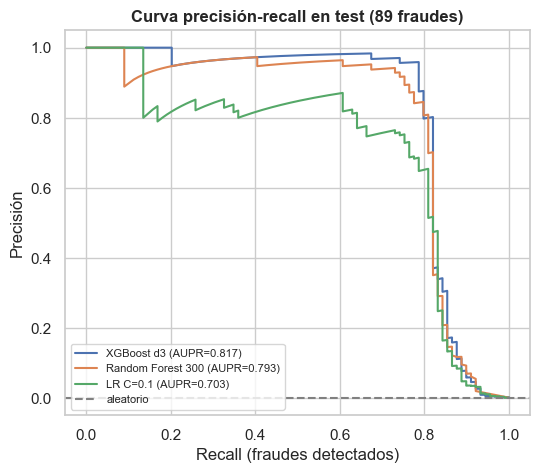

In [55]:
ax = plot_pr(y_te, SC3_TEST)
ax.set(title="Curva precisión-recall en test (89 fraudes)", xlabel="Recall (fraudes detectados)", ylabel="Precisión")
ax.legend(fontsize=8, loc="lower left");

**¿Ve los fraudes que el no supervisado no veía? (notebook 03 §8, sin re-ejecutar: necesita los scores del GMM).** Con el corte del bloque 2 (un fraude se "ve" si su score OOF supera el p99 de los normales de su fold, ~240 falsas alarmas por fold):

| | XGBoost d3 lo ve | XGBoost d3 no lo ve | Total |
|---|---|---|---|
| GMM eje lo ve | 169 | 1 | 170 |
| GMM eje no lo ve | **14** | 22 | 36 |
| Total | 183 | 23 | 206 |

El XGBoost **recupera 14 de los 36 fraudes** que el no supervisado no veía (15 en la primera ejecución del 03) y pierde solo 1 de los suyos. Los recuperados son los "dentro de la nube" del bloque 2: **X14 y X17 compensadas** (mediana estandarizada −5,4 y +5,2, cuando en los fraudes típicos van juntas: −9,5 y −9,6), **X4 alta** e importes muy repetidos (`amount_freq` +2,3). Un detector de rareza los ve normales porque en el eje menor se cancelan; un clasificador los reconoce porque se parecen a fraudes etiquetados. Además ordena mejor lo alto de la lista: en el top 20 de cada fold, el **99 %** son fraude, frente al **95 %** del GMM. Siguen sin verse **22** (~11 %), con medianas casi iguales a las de los normales.

> **Conclusión:** en test, el XGBoost d3 da **0,817** (**0,804** sin duplicados), frente a **0,736** del GMM eje del bloque 2 (**+0,081**). Baja **−0,041** respecto a su CV, menos de 1 std, y en línea con lo que bajó el GMM (−0,043): el test es algo más difícil que la media de los folds. En el 03, un bootstrap estratificado de esa diferencia con las mismas filas dio un IC 95 % de +0,04 a +0,13, positiva en el 100 % de las réplicas. La logística vuelve a quedar por debajo de la referencia (0,703). → **Impacto:** el test confirma la CV: **el supervisado es mejor que el no supervisado**, y gana por las dos vías: ve fraudes "normales" y ordena mejor la cola.

### 3.7 ¿En qué se fija el modelo?

**Qué miramos y por qué.** Un modelo de fraude tiene que poder explicarse. La **ganancia** media de los cortes de cada variable mide cuánto reduce la pérdida el XGBoost (ajustado con todo train, §3.6) cada vez que corta por ella: es lo que mira el modelo al construirse.

,X14,X10,X17,X12,X4,X16
ganancia (norm.),0.288,0.245,0.105,0.067,0.048,0.022


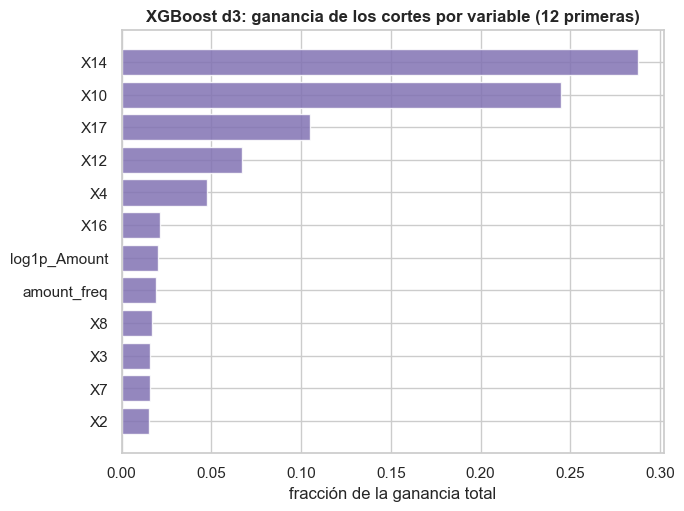

In [56]:
gain3 = pd.Series(AJ3["XGBoost d3"].get_booster().get_score(importance_type="gain"))
gain3 = gain3.reindex([f"f{i}" for i in range(len(FEATURES))]).fillna(0).set_axis(FEATURES)
gain3 = (gain3 / gain3.sum()).sort_values()
ax = plt.subplots(figsize=(7, 5.5))[1]
ax.barh(gain3.index[-12:], gain3.iloc[-12:], color=FAM["boosting"], alpha=.85)
ax.set(xlabel="fracción de la ganancia total", title="XGBoost d3: ganancia de los cortes por variable (12 primeras)");
gain3.iloc[::-1].head(6).round(3).to_frame("ganancia (norm.)").T

> **Conclusión:** **X14, X10 y X17 (0,29, 0,25 y 0,11 de la ganancia total)** concentran la mayor parte de la ganancia: las variables del eje menor del bloque 2 y del EDA (bloque 1). En el 03 (§10) se midió también la **importancia por permutación** en test, que mide lo que el modelo *necesita* para ordenar: **X14** (la AUPR cae 0,126 al barajarla), **X4** (0,029), **`amount_freq`** (0,023) y **X10** (0,015). X4 y el importe son justo lo que separa los fraudes "dentro de la nube" de §3.6; X17 y X10 pesan menos al permutarlas porque están muy correladas con X14 dentro de los fraudes. → **Impacto:** el supervisado no ha descubierto variables nuevas, sino **cortes** nuevos sobre las mismas, más el papel de X4 y del importe. Es coherente con el EDA y con el bloque 2, y fácil de justificar.

### 3.8 Qué más probamos (notebook 03)

Todo lo demás del 03, con las cifras de su ejecución (`03_metricas_cv.csv` y `03_metricas_test.csv`). AUPR en CV de 5 folds (media ± std), salvo que se indique.

| Experimento (sección del 03) | Resultado | Conclusión |
|---|---|---|
| LR sin regularizar (`C=1`) y `C=1` balanced (§2) | 0,771 ± 0,073 · 0,765 ± 0,084 | `balanced` tampoco ayuda sin regularizar (−0,006). |
| LR `C=0.01` (§2) | 0,786 ± 0,072, gana al GMM eje en 3 de 5 folds | Empata con la referencia; `C=0.1` como representante lineal. |
| LR `C=0.1` + eje menor como variable (§2) | 0,778 ± 0,074 | No aporta: el eje menor ya es una combinación lineal de las 22. |
| Coseno entre los coeficientes de la LR y el eje menor (§2) | \|coseno\| = 0,51 | La LR comparte dirección con el eje menor solo en parte: las dos pesan X14 y X10, la LR carga mucho más en X4. |
| Extra Trees 300 (§3) | 0,841 ± 0,055 (test 0,811) | Gana al GMM en los 5 folds, pero por debajo de RF y XGBoost en CV. |
| XGBoost profundidad 4 (§3) | 0,863 ± 0,058 | Punto de partida del ajuste; empata con d3. |
| LightGBM con la configuración de XGBoost (d4, `min_child_weight=1`) (§4) | 0,861 ± 0,059 (test 0,791) | Equivalente a XGBoost una vez configurado. |
| XGBoost d4 · `scale_pos_weight` 10 y 50 (§5) | 0,863 · 0,862 | Empata / baja; igual que aquí con d3. |
| XGBoost d4 · SMOTE 5 % y undersampling 2 % (§5, `imblearn`) | 0,851 ± 0,079 · 0,830 ± 0,101 | Ver §3.4: no se reequilibra (D-2.6). |
| XGBoost d4 sin `amount_freq` (§6a) | 0,856 ± 0,059 (−0,007, pierde en los 5 folds) | `amount_freq` se mantiene (D-1.4). |
| XGBoost d4 + eje menor / + 4 ejes menores (§6a) | 0,861 ± 0,056 · 0,866 ± 0,060 (+0,003, 4 de 5 folds) | Mejora de milésimas: no compensa la complejidad; los árboles ya combinan X14, X10, X17… |
| Profundidad 2, 3, 4 y 6 (§6b) | 0,861 · 0,861 · 0,863 · 0,862 | La AUPR es **plana**: se elige d = 3, la más sencilla del grupo de cabeza. |
| XGBoost d4 con 800 árboles y ritmo 0,025 (§6b) | 0,863 ± 0,061 | Un ritmo más lento no cambia nada. |
| XGBoost d3 con tres semillas (42, 43, 44) (§6b) | 0,861 · 0,862 · 0,865; std entre semillas 0,001 (rango 0,003) | Estable: la semilla mueve 0,003, los folds ±0,06. El modelo está en una meseta. |
| MLP 64-32 (L2 = 1e-3), variables estandarizadas (§6) | 0,790 ± 0,097 (test 0,801) | Apenas sobre la referencia y la más inestable entre folds: con ~165 fraudes por fold no aprende una frontera mejor que el boosting. Descartada. |
| Matriz de victorias por pares de los finalistas (§7) | XGBoost d3 gana en 5 de 5 folds al GMM, la LR y la MLP; en 4 de 5 a RF y ET | El XGBoost es el mejor supervisado individual. |
| Test de los finalistas (§9) | XGBoost d3 0,818 · ET 0,811 · MLP 0,801 · RF 0,793 · LightGBM 0,791 · GMM eje 0,736 · LR 0,703 | El orden de la CV se mantiene en lo grueso; con 89 fraudes, ET y MLP cerca del XGBoost no son diferencias significativas. |
| Bootstrap estratificado en test, XGBoost d3 − GMM eje (§9) | +0,082, IC 95 % 0,037–0,130, > 0 en el 100 % de 1.000 réplicas | La mejora en test es clara. |
| Fraudes vistos al p99 y precisión en lo alto de la lista (§8) | Ver §3.6: recupera 14 de 36; top 20: 0,99 (XGBoost) · 0,95 (GMM) · 0,89 (LR) | Gana por ver fraudes "normales" y por ordenar mejor la cola. |
| Importancia por permutación en test (§10) | X14 0,126 · X4 0,029 · `amount_freq` 0,023 · X10 0,015 | Ver §3.7. |
| Respaldo supervisado: XGBoost d3 reajustado con toda la construcción (§11) | Spearman 0,862 con el ajuste solo con train; top 1 % compartido 64,8 % (21,5 % con el respaldo no supervisado) | Respaldo `03_scores_produccion_supervisado.csv`; el entregable final lo decide el bloque 4. |

In [57]:
print(f"Bloque 3 ejecutado en {time.time() - t0_b3:.0f} s")
tabla_cv([n for n in RES if n in ["LR C=0.1", "LR C=0.1 balanced", "Random Forest 300", "XGBoost d3", *LGBS3, *DESB3]])[["familia", "media", "std", "segundos"]]

Bloque 3 ejecutado en 81 s


,familia,media,std,segundos
LightGBM min_child_weight=5,boosting,0.862,0.061,1.703
XGBoost d3 · peso fraude ×10,boosting,0.861,0.056,5.943
XGBoost d3,boosting,0.858,0.060,6.464
XGBoost d3 · peso fraude ×50,boosting,0.857,0.056,6.203
Random Forest 300,bagging,0.851,0.060,38.751
LightGBM min_child_weight=1,boosting,0.796,0.094,1.924
LR C=0.1,lineal,0.781,0.073,0.550
LightGBM min_child_weight=0.1,boosting,0.780,0.100,1.822
LR C=0.1 balanced,lineal,0.768,0.091,0.830
LightGBM min_child_weight=0.01,boosting,0.597,0.126,2.010


### 3.9 Conclusiones del bloque

1. **El supervisado gana al no supervisado, y de forma concluyente.** **XGBoost d3** da **0,858 ± 0,060** en CV y **0,817** en test, frente a **0,779** y **0,736** del GMM eje del bloque 2. Gana en los 5 folds y en test.
2. **Lo que decide es la frontera no lineal.** La logística iguala al GMM eje (0,781), pero no lo supera; los árboles (Random Forest 0,851, XGBoost 0,858) ganan en los 5 folds.
3. **No hay que reequilibrar** (D-2.6). Pesos de clase, SMOTE y undersampling no mejoran la AUPR (el undersampling empeora −0,033): la AUPR mide el orden.
4. **LightGBM por defecto diverge** (0,145) por la hessiana mínima por hoja (`min_child_weight` = 0,001); con 5 empata con XGBoost (0,862).
5. **El modelo está en una meseta.** Profundidad, ritmo y semillas mueven la AUPR menos de 0,005 en el 03; el eje menor como variable no aporta y `amount_freq` se mantiene.
6. **Recupera parte de lo que el no supervisado no veía** (14 de 36 fraudes al 1 % de falsas alarmas) y se apoya en X14, X10, X4 y el importe: cortes nuevos sobre las mismas variables.

*Reproducibilidad:* en este equipo el XGBoost d3 da 0,858 ± 0,060 en CV y 0,817 en test; donde se ejecutó el 03 daba 0,861–0,865 y 0,814–0,818. Mismo código y mismos folds: XGBoost y LightGBM con varios hilos no dan resultados idénticos en equipos distintos (orden de las sumas en paralelo, versiones), y la diferencia (~0,005) es diez veces menor que la std entre folds (0,06).

**Pasa al bloque 4:** el XGBoost d3 es la referencia a batir (0,858 en CV). Dos preguntas: ¿añadir los scores no supervisados del bloque 2 como variables le aporta algo?, y ¿se puede exprimir más, ajustando hiperparámetros o combinando varios clasificadores?

## 4. Híbrido, optimización y modelo final

**Qué miramos y por qué.** El bloque 3 deja un XGBoost de profundidad 3 como mejor modelo único. Quedan dos formas de intentar mejorarlo, que corresponden a los notebooks de trabajo 04 y 05:

1. **Híbrido (04):** dar al XGBoost, como variables extra, los scores de los detectores no supervisados del bloque 2. Si la rareza que miden aporta algo que las variables no tienen, el clasificador debería ordenar mejor.
2. **Optimización (05):** exprimir el enfoque supervisado con lo habitual en este tipo de modelos: promediar semillas, otros modelos de árboles y **mezclas de modelos**.

A esta altura las mejoras posibles son de **milésimas**, del mismo orden que el ruido. Por eso este bloque es sobre todo **un bloque de método**: cómo medir sin fugas (§4.1), cómo distinguir una mejora del azar (§4.2) y cómo elegir **antes** de mirar el test (§4.4). El test solo confirma al final (§4.5).

**Referencia a batir:** el XGBoost d3 del bloque 3 (400 árboles, `learning_rate` 0,05, `subsample` 0,8, `colsample_bytree` 0,7, semilla 42), sobre las 22 variables de `FEATURES`.

In [58]:
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits

def modelo_xgb_d3(**kw):
    """XGBoost d3 congelado del bloque 3 (D-2.5). kw cambia solo lo indicado (p. ej. la semilla)."""
    return xgb.XGBClassifier(**{**dict(n_estimators=400, learning_rate=.05, max_depth=3, subsample=.8,
                                     colsample_bytree=.7, n_jobs=N_JOBS, random_state=SEED), **kw})

def rango_01(s):
    """Posición de cada score dentro de su conjunto, de 0 a 1 (1 = el más sospechoso). Empates: rango medio."""
    return stats.rankdata(s) / len(s)

T0_BLOQUE4 = time.time()

### 4.1 ¿Ayudan los scores no supervisados al XGBoost?

**Qué miramos y por qué.** El bloque 2 encontró que la señal del fraude vive en el **eje menor**: la dirección de mínima varianza de las transacciones normales. Un GMM de 5 gaussianas sobre ese único eje fue el mejor detector no supervisado (0,779 en CV). La pregunta del 04 es si esa medida de rareza, añadida como **columna 23** del XGBoost, le ayuda a ordenar mejor.

**El riesgo es la fuga.** Si el score de una fila de entrenamiento lo calcula un GMM que ha visto las filas de validación, el XGBoost aprende de información que no tendrá en producción, y la CV sale optimista. Por eso el score se calcula **en dos niveles**, como en el 04 §3:

1. En cada fold externo (los 5 oficiales), la validación queda apartada.
2. Dentro del entrenamiento externo, **5 folds internos por grupo de duplicados**: el score de cada fila de entrenamiento lo da un GMM ajustado sin ella (solo con normales de los otros folds internos).
3. La validación externa se puntúa con un GMM ajustado con **todas las normales del entrenamiento externo**.
4. El XGBoost (misma configuración, sin tocar nada) se entrena con las 22 variables + el score interno y puntúa la validación externa con las 22 variables + el score externo.

Así se reproduce lo que pasará en producción: el score de una transacción nueva siempre lo da un GMM que no la ha visto. Se re-ejecuta solo esta versión, la más barata y la más prometedora; las otras pruebas del 04 se resumen en la tabla de abajo.

In [59]:
class EjesPropios(TransformerMixin, BaseEstimator):
    """Coordenadas en los k ejes de menor varianza de los normales estandarizados (k=1: el eje menor del bloque 2).
    Se ajusta solo con los datos que recibe en fit (fit() de la preparación le pasa únicamente normales)."""
    def __init__(self, k=1):
        self.k = k
    def fit(self, X, y=None):
        self.sc_ = StandardScaler().fit(X)
        self.V_ = np.linalg.eigh(np.cov(self.sc_.transform(X).T))[1][:, :self.k]   # autovalores en orden creciente
        return self
    def transform(self, X):
        return self.sc_.transform(X) @ self.V_

# Detector del bloque 2 (D-2.4): eje menor → RobustScaler → GMM de 5 gaussianas. No supervisado: fit() usa solo normales.
GMM_EJE_MENOR = make_pipeline(EjesPropios(1), make_pipe(GaussianMixture(5, random_state=SEED), "robust"))

def folds_internos_por_grupo(y, g, k=5, seed=SEED):
    """k folds estratificados en los que cada grupo de duplicados va entero a un fold. Equivale a StratifiedGroupKFold
    (cada grupo tiene una sola clase), pero estratifica un representante por grupo: segundos en lugar de minutos."""
    grupos, primera, inversa = np.unique(g, return_index=True, return_inverse=True)
    for _, gv in StratifiedKFold(k, shuffle=True, random_state=seed).split(grupos, y[primera]):
        val = np.isin(inversa, gv)
        yield np.flatnonzero(~val), np.flatnonzero(val)

class XGBoostConScoreGMM(ClassifierMixin, BaseEstimator):
    """Híbrido del 04: XGBoost d3 con una columna más, el score del GMM del eje menor, calculado SIN FUGA.
    fit(X, y): el score de cada fila de entrenamiento sale de 5 folds internos por grupo de duplicados (un GMM que no la
    ha visto); después se ajusta el GMM con todas las normales de X, que es el que puntúa cualquier fila nueva.
    Los grupos se reconstruyen dentro de fit: filas idénticas = mismo grupo (como group_id de la preparación)."""
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        g = pd.factorize(pd.util.hash_pandas_object(pd.DataFrame(X), index=False))[0]
        s_interno = np.full(len(y), np.nan)
        with threadpool_limits(1):      # un GMM sobre un solo eje es ligero: más hilos solo añaden sobrecarga
            for it, iv in folds_internos_por_grupo(y, g):
                assert not np.intersect1d(g[it], g[iv]).size            # ningún grupo de duplicados cruza
                s_interno[iv] = score(fit(GMM_EJE_MENOR, X[it], y[it]), X[iv])
            self.gmm_ = fit(GMM_EJE_MENOR, X, y)                        # GMM final: todas las normales de X
        assert np.isfinite(s_interno).all()
        self.xgb_ = fit(modelo_xgb_d3(), np.c_[X, s_interno], y)        # mismo XGBoost, 23 columnas
        self.classes_ = self.xgb_.classes_
        return self
    def predict_proba(self, X):
        X = np.asarray(X, float)
        with threadpool_limits(1):
            s = score(self.gmm_, X)
        return self.xgb_.predict_proba(np.c_[X, s])

In [60]:
REF_B4, HIB_B4, GMM_B4 = "XGBoost d3 (referencia del bloque 4)", "XGBoost d3 + score GMM eje menor", "GMM eje menor (solo)"
evaluar(REF_B4, modelo_xgb_d3(), "boosting")
evaluar(HIB_B4, XGBoostConScoreGMM(), "híbrido")
evaluar(GMM_B4, GMM_EJE_MENOR, "no supervisado")       # el score que recibe la validación externa, por sí solo
d_hib = por_fold(HIB_B4) - por_fold(REF_B4)
display(tabla_cv([REF_B4, HIB_B4, GMM_B4]))
print(f"Híbrido frente a la referencia: Δ medio = {d_hib.mean():+.4f} | gana en {(d_hib > 0).sum()} de 5 folds | "
      f"Δ por fold entre {d_hib.min():+.4f} y {d_hib.max():+.4f}")

XGBoost d3 (referencia del bloque 4): CV AUPR = 0.858 ± 0.060  (6 s)


XGBoost d3 + score GMM eje menor: CV AUPR = 0.863 ± 0.055  (23 s)


GMM eje menor (solo): CV AUPR = 0.779 ± 0.060  (3 s)


,familia,n_feats,media,std,segundos,fold0,fold1,fold2,fold3,fold4
XGBoost d3 + score GMM eje menor,híbrido,22.0,0.863,0.055,23.344,0.928,0.872,0.768,0.841,0.903
XGBoost d3 (referencia del bloque 4),boosting,22.0,0.858,0.060,6.480,0.919,0.876,0.753,0.832,0.907
GMM eje menor (solo),no supervisado,22.0,0.779,0.060,3.212,0.840,0.753,0.718,0.723,0.862


Híbrido frente a la referencia: Δ medio = +0.0050 | gana en 3 de 5 folds | Δ por fold entre -0.0043 y +0.0149


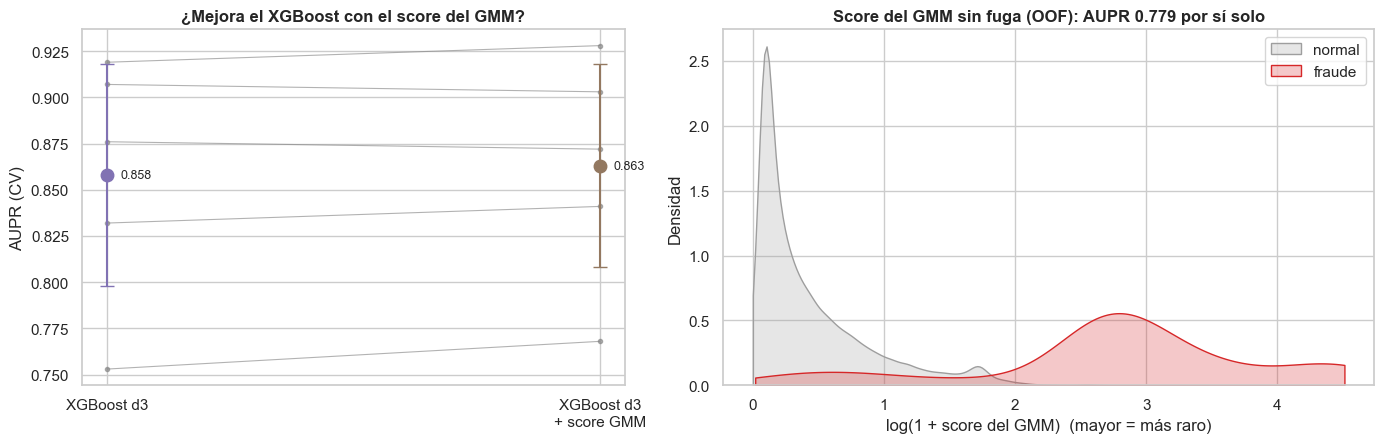

In [61]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
plot_folds([REF_B4, HIB_B4], title="¿Mejora el XGBoost con el score del GMM?", ax=a1)
a1.set_xticks([0, 1], ["XGBoost d3", "XGBoost d3\n+ score GMM"], rotation=0, ha="center")
# Densidad del score sin fuga: separa bastante, pero el XGBoost ya separa más con las variables originales
for c in (0, 1):
    sns.kdeplot(np.log1p(OOF[GMM_B4][ya == c] - OOF[GMM_B4].min()), ax=a2, color=C[c], fill=True,
                common_norm=False, label=LBL[c], cut=0)
a2.set(xlabel="log(1 + score del GMM)  (mayor = más raro)", ylabel="Densidad",
       title=f"Score del GMM sin fuga (OOF): AUPR {RES[GMM_B4]['media']:.3f} por sí solo")
a2.legend()
fig.tight_layout()
plt.show()

> **Conclusión:** el score del GMM, calculado sin fuga, separa bien por sí solo (**0,779** de AUPR, la cifra del bloque 2), pero por debajo del XGBoost (**0,858 ± 0,060**). Como columna 23, el híbrido da **0,863 ± 0,055**: Δ **+0,0050**, pero gana solo en **3 de 5 folds** (Δ por fold de −0,004 a +0,015). Llega justo al umbral de mejora, pero **no pasa la regla del 04** (Δ ≥ +0,005 y 4 de 5). En el 04 daba Δ −0,0007 frente a una referencia de 0,865: la diferencia entre equipos está casi toda en la referencia (0,865 allí, 0,858 aquí) y es del orden del ruido de semilla. → **Impacto:** con 5 folds no se puede decidir: el signo de la mejora cambia según el equipo. El híbrido pasa como candidato a la comparación más exigente de §4.2–§4.4, con 15 folds y un placebo de semillas.

**Qué más probamos (notebook 04).** El 04 hizo el experimento completo, con los mismos dos niveles sin fuga y los mismos 5 folds; sus cifras son de otro equipo, donde el mismo XGBoost daba 0,865 (en este da 0,858: ver §4.2). Ninguna variante mejoró al XGBoost original (D-2.7).

| Experimento (04) | Resultado | Conclusión |
|---|---|---|
| Cinco scores del bloque 2 como variables (GMM eje menor, LOF 4 ejes, ECOD top 4, GMM completo, autoencoder 12) (04 §2–§5) | Spearman entre scores ≤ 0,46. XGBoost + 5 scores **0,859 ± 0,060** frente a 0,865: Δ −0,0056, gana en 1 de 5; frente a + GMM, Δ −0,0050 | Miden rarezas distintas, pero no añaden información al XGBoost. Más columnas, peor |
| XGBoost + score GMM eje menor (04 §4) | **0,864 ± 0,059**: Δ −0,0007, gana en 4 de 5 | Empate: no llega a +0,005 |
| Auditoría de fuga (04 §3) | 5 particiones externas + 25 internas, **0 grupos compartidos**; los scores recalculados reproducen la AUPR del 02 (0,773 el GMM) | La comparación es limpia |
| Prioridad a las variables más predictivas, `feature_weights` ×3 (04 §5.1) | Elegidas por permutación dentro de cada entrenamiento (X14 primera en 4 de 5 folds; X10 en el otro). Control con pesos uniformes 0,860; ×3 a la primera **0,864** (Δ −0,0009, 2 de 5); ×3 a las cuatro primeras **0,865** (Δ −0,0000, 1 de 5) | El XGBoost ya usa bien X14, X10 y X4: favorecerlas no aporta |
| Captura con ~1 % de falsas alarmas (04 §7) | Original 183 de 206 fraudes; + GMM 184 (recupera 2, pierde 1); + 5 scores 183 (recupera 2, pierde 2). Precisión en las 50 primeras alertas por fold: 0,712, 0,712 y 0,704 | Los híbridos no encuentran fraudes nuevos: cambian unos pocos de sitio |
| Importancia en el híbrido de 5 scores, en test (04 §10) | Permutar X14 cuesta 0,065 de AUPR; permutar los 5 scores juntos, 0,018. El autoencoder tiene la mayor ganancia de cortes (0,37) pero permutarlo no cuesta nada (−0,005) | El modelo usa los scores, pero las variables originales ya contienen esa información |
| Test, solo como confirmación (04 §9) | Original **0,815**; + GMM 0,818 (Δ +0,0035, IC 95 % −0,006 a +0,015); + 5 scores 0,807 (Δ −0,0081, IC −0,026 a +0,007) | Los IC incluyen el 0: el test no cambia la elección |

### 4.2 ¿Cómo medimos una mejora pequeña?

**Qué miramos y por qué.** Con 206 fraudes en train (unos 41 por fold), cambiar solo la semilla del XGBoost mueve la AUPR de un fold varias milésimas. Si se prueban muchas variantes, alguna "ganará" por azar. El 05 se protege con tres medidas, que aquí se repiten tal cual:

1. **15 folds en lugar de 5:** la partición oficial y dos particiones más, también por grupos de duplicados (`StratifiedGroupKFold(5, shuffle=True)` con `random_state` 1 y 2). Todos los modelos se evalúan en **los mismos 15 folds** y se comparan **diferencias por pares fold a fold**, que eliminan la dificultad propia de cada fold.
2. **Placebo de semillas:** el mismo XGBoost con semillas 43–46. Ninguna semilla es mejor que otra, así que sus diferencias con la semilla 42 son **ruido puro**: miden cuánto puede "mejorar" un modelo sin cambiar nada.
3. **Regla de decisión fijada aquí, antes de ver ningún candidato.** Un candidato sustituye a la referencia solo si cumple las tres condiciones:
   - **Δ medio ≥ +0,005** de AUPR en los 15 folds (la mejora mínima del 04);
   - **gana en ≥ 11 de los 15 folds** (≈ 3 de cada 4, el equivalente al "4 de 5" del 04);
   - su **Δ medio supera el mayor |Δ medio| de los placebos**: una mejora menor que la de cambiar la semilla no es una mejora.

   Si varios la cumplen, se elige el de mayor Δ medio. Si ninguno, se mantiene el XGBoost.

In [62]:
# Tres particiones de 5 folds por grupo: la 0 es la oficial (cv_splits); la 1 y la 2, nuevas.
PARTICIONES_15 = [cv_splits] + [list(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xa, ya, ga)) for s in (1, 2)]
for p in PARTICIONES_15:
    assert sorted(np.concatenate([iv for _, iv in p])) == list(range(len(ya)))   # cada fila valida una vez
    assert all(not np.intersect1d(ga[it], ga[iv]).size for it, iv in p)          # ningún grupo cruza

RES_15, OOF_15, FAMILIA_15 = {}, {}, {}   # nombre → AUPR (3 × 5) · scores OOF (3 × filas de train) · familia
MIN_MEJORA_15, MIN_VICTORIAS_15 = .005, 11

def registrar_15(nombre, familia, oof, segundos):
    a = np.array([[average_precision_score(ya[iv], oof[r, iv]) for _, iv in p] for r, p in enumerate(PARTICIONES_15)])
    RES_15[nombre], OOF_15[nombre], FAMILIA_15[nombre] = {"a": a, "segundos": segundos}, oof, familia
    print(f"{nombre}: AUPR 15 folds = {a.mean():.4f} ± {a.std():.4f} | partición oficial = {a[0].mean():.4f} ({segundos:.0f} s)")

def evaluar_15(nombre, modelo, familia, oof_oficial=None):
    """Como evaluar(), pero en las 3 particiones: AUPR de los 15 folds y scores OOF de cada partición.
    oof_oficial: OOF ya calculados con evaluar() para el mismo modelo (partición 0 = cv_splits), para no repetirlos."""
    t0, oof = time.time(), np.full((3, len(ya)), np.nan)
    if oof_oficial is not None:
        oof[0] = oof_oficial
    for r, p in enumerate(PARTICIONES_15):
        if r == 0 and oof_oficial is not None:
            continue
        for it, iv in p:
            oof[r, iv] = score(fit(modelo, Xa[it], ya[it]), Xa[iv])
    registrar_15(nombre, familia, oof, time.time() - t0)

def combinar_15(nombre, componentes, familia, como="rango"):
    """Mezcla fold a fold: media de rangos dentro del fold (modelos distintos) o de probabilidades (semillas)."""
    oof = np.full((3, len(ya)), np.nan)
    for r, p in enumerate(PARTICIONES_15):
        for _, iv in p:
            ss = [OOF_15[c][r, iv] for c in componentes]
            oof[r, iv] = np.mean([rango_01(s) for s in ss] if como == "rango" else ss, axis=0)
    registrar_15(nombre, familia, oof, sum(RES_15[c]["segundos"] for c in componentes))

def delta_15(n, ref=None):
    return RES_15[n]["a"] - RES_15[ref or REF_15]["a"]

def tabla_15(nombres, ref=None):
    filas = {}
    for n in nombres:
        a, d = RES_15[n]["a"], delta_15(n, ref)
        filas[n] = {"familia": FAMILIA_15[n], "media 15 folds": a.mean(), "std": a.std(), "oficial (5 folds)": a[0].mean(),
                    "Δ medio": d.mean(), "Δ particiones 1–2": d[1:].mean(), "peor Δ fold": d.min(),
                    "gana (de 15)": int((d > 0).sum()), "segundos": RES_15[n]["segundos"]}
    t = pd.DataFrame(filas).T
    return t.astype({c: float for c in t.columns if c != "familia"}).sort_values("media 15 folds", ascending=False)

def plot_deltas_15(nombres, title, ax=None, ref=None):
    """Δ AUPR frente a la referencia en cada uno de los 15 folds (marcador = partición) y su media (rombo)."""
    ax = ax or plt.subplots(figsize=(max(7, 1.4 * len(nombres)), 4.6))[1]
    for i, n in enumerate(nombres):
        d = delta_15(n, ref)
        for r, mk in enumerate("os^"):
            ax.scatter(i + np.linspace(-.18, .18, 5), d[r], marker=mk, s=22, c="grey", alpha=.7,
                       label=f"partición {r}" if i == 0 else None)
        ax.scatter(i, d.mean(), marker="D", s=80, c=FAM[FAMILIA_15[n]], zorder=3, edgecolor="black")
        ax.annotate(f"{d.mean():+.4f}", (i, d.mean()), xytext=(12, 0), textcoords="offset points", va="center", fontsize=9)
    ax.axhline(0, c="black", lw=1)
    ax.axhline(MIN_MEJORA_15, c=FAM["referencia"], ls="--", lw=1, label=f"mejora mínima (+{MIN_MEJORA_15})")
    ax.set_xticks(range(len(nombres)), nombres, rotation=15, ha="right")
    ax.set(ylabel="Δ AUPR frente a la referencia", title=title)
    ax.legend(fontsize=8, loc="lower left")
    return ax

pd.DataFrame({f"partición {r}": [int(ya[iv].sum()) for _, iv in p] for r, p in enumerate(PARTICIONES_15)},
             index=[f"fold {k}" for k in range(5)]).T.rename_axis("fraudes de validación")

,fold 0,fold 1,fold 2,fold 3,fold 4
fraudes de validación,,,,,
partición 0,41,41,41,42,41
partición 1,41,42,41,41,41
partición 2,42,41,41,41,41


In [63]:
REF_15 = "XGBoost d3 (referencia)"
SEMILLAS_PLACEBO = (43, 44, 45, 46)
PLACEBOS_15 = [f"XGBoost d3 · semilla {s}" for s in SEMILLAS_PLACEBO]
# Catálogo de los modelos que se re-ejecutan (se reutiliza para test y producción en §4.5 y en el bloque 5)
MODELOS_B4 = {REF_15: modelo_xgb_d3(), **{n: modelo_xgb_d3(random_state=s) for n, s in zip(PLACEBOS_15, SEMILLAS_PLACEBO)}}

evaluar_15(REF_15, MODELOS_B4[REF_15], "referencia", oof_oficial=OOF[REF_B4])   # partición 0 = la de §4.1
for n in PLACEBOS_15:
    evaluar_15(n, MODELOS_B4[n], "placebo")
RUIDO_15 = max(abs(delta_15(n).mean()) for n in PLACEBOS_15)
display(tabla_15([REF_15, *PLACEBOS_15]).round(4))
print(f"Ruido de semilla: |Δ medio| máximo de los placebos = {RUIDO_15:.4f}; Δ por fold entre "
      f"{min(delta_15(n).min() for n in PLACEBOS_15):+.4f} y {max(delta_15(n).max() for n in PLACEBOS_15):+.4f}")

XGBoost d3 (referencia): AUPR 15 folds = 0.8583 ± 0.0656 | partición oficial = 0.8575 (13 s)


XGBoost d3 · semilla 43: AUPR 15 folds = 0.8610 ± 0.0675 | partición oficial = 0.8593 (18 s)


XGBoost d3 · semilla 44: AUPR 15 folds = 0.8581 ± 0.0680 | partición oficial = 0.8601 (18 s)


XGBoost d3 · semilla 45: AUPR 15 folds = 0.8583 ± 0.0693 | partición oficial = 0.8565 (18 s)


XGBoost d3 · semilla 46: AUPR 15 folds = 0.8602 ± 0.0661 | partición oficial = 0.8607 (19 s)


,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
XGBoost d3 · semilla 43,placebo,0.8610,0.0675,0.8593,0.0027,0.0032,-0.0054,7.0,18.1394
XGBoost d3 · semilla 46,placebo,0.8602,0.0661,0.8607,0.0019,0.0013,-0.0085,9.0,18.8568
XGBoost d3 (referencia),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,12.7536
XGBoost d3 · semilla 45,placebo,0.8583,0.0693,0.8565,-0.0000,0.0005,-0.0164,8.0,18.4966
XGBoost d3 · semilla 44,placebo,0.8581,0.0680,0.8601,-0.0002,-0.0017,-0.0158,8.0,18.4690


Ruido de semilla: |Δ medio| máximo de los placebos = 0.0027; Δ por fold entre -0.0164 y +0.0178


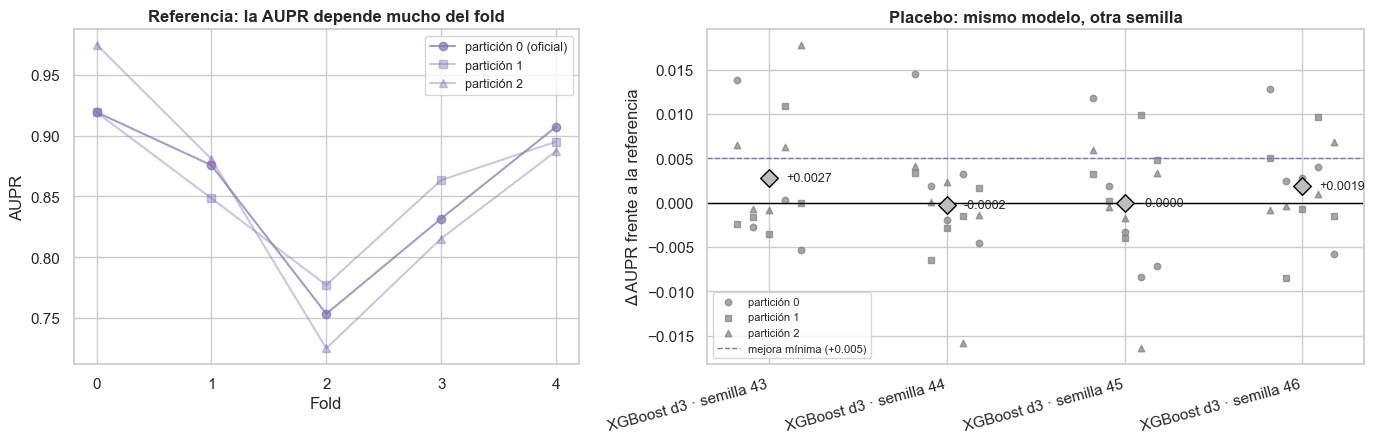

In [64]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
a = RES_15[REF_15]["a"]
for r, mk in enumerate("os^"):
    a1.plot(range(5), a[r], marker=mk, c=FAM["referencia"], alpha=.4 + .3 * (r == 0),
            label=f"partición {r}" + (" (oficial)" if r == 0 else ""))
a1.set(xticks=range(5), xlabel="Fold", ylabel="AUPR", title="Referencia: la AUPR depende mucho del fold")
a1.legend(fontsize=9)
plot_deltas_15(PLACEBOS_15, "Placebo: mismo modelo, otra semilla", ax=a2)
fig.tight_layout()
plt.show()

> **Conclusión:** la referencia da **0,858 ± 0,066** en los 15 folds (0,858 en la partición oficial), y la AUPR de un fold va de ~0,73 a ~0,97 según qué fraudes le toquen. Cambiar solo la semilla mueve la AUPR de un fold entre **−0,016 y +0,018**, y la media de los 15 folds hasta **0,0027**; la semilla 42 queda en la parte baja de los placebos (0,858 frente a 0,858–0,861). Es el mismo orden que la diferencia del híbrido entre equipos (§4.1). → **Impacto:** una mejora real tiene que superar **+0,005** de media, repetirse en al menos **11 de 15** folds y quedar por encima de **0,0027**. Por debajo de eso no se distingue de cambiar la semilla.

### 4.3 ¿Qué candidatos pueden mejorar al XGBoost?

**Qué miramos y por qué.** Se re-ejecutan los candidatos del 05 que justifican la decisión final, de menos a más cambio respecto a la referencia:

- **XGBoost con 5 semillas promediadas.** Cada semilla ve submuestras distintas de filas y columnas; promediar sus probabilidades reduce la varianza del modelo. Sale gratis: es la media de la referencia y de los cuatro placebos, ya ajustados en los mismos folds.
- **El híbrido de §4.1** (XGBoost + score del GMM sin fuga), para comprobar con 15 folds lo que en 5 folds no queda claro.
- **CatBoost** (profundidad 6, 1.000 iteraciones, ritmo 0,05): árboles simétricos, todos los nodos de un nivel con el mismo corte. Regulariza de otra forma que XGBoost.
- **LightGBM** con `min_child_weight=5`, la versión que en el bloque 3 empataba con XGBoost (D-2.6). Crece los árboles hoja a hoja.
- **Random Forest 300** (`min_samples_leaf=2`), el mejor modelo que no es boosting en el bloque 3. Promedia árboles profundos e independientes, así que se equivoca de forma distinta.

Ninguno usa reequilibrado de clases (D-2.6) ni se ajusta a estos folds: son configuraciones fijas.

XGBoost d3 · 5 semillas: AUPR 15 folds = 0.8612 ± 0.0677 | partición oficial = 0.8604 (87 s)


Híbrido: XGBoost d3 + score GMM: AUPR 15 folds = 0.8629 ± 0.0662 | partición oficial = 0.8625 (41 s)


CatBoost d6: AUPR 15 folds = 0.8610 ± 0.0700 | partición oficial = 0.8597 (205 s)


LightGBM mcw 5: AUPR 15 folds = 0.8622 ± 0.0670 | partición oficial = 0.8624 (5 s)


Random Forest 300: AUPR 15 folds = 0.8489 ± 0.0702 | partición oficial = 0.8508 (117 s)


,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
Híbrido: XGBoost d3 + score GMM,híbrido,0.8629,0.0662,0.8625,0.0046,0.0044,-0.0109,8.0,41.2922
LightGBM mcw 5,boosting,0.8622,0.0670,0.8624,0.0040,0.0035,-0.0233,8.0,5.0447
XGBoost d3 · 5 semillas,boosting,0.8612,0.0677,0.8604,0.0029,0.0029,-0.0032,10.0,86.7155
CatBoost d6,boosting,0.8610,0.0700,0.8597,0.0027,0.0030,-0.0176,8.0,204.6506
XGBoost d3 (referencia),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,12.7536
Random Forest 300,bagging,0.8489,0.0702,0.8508,-0.0094,-0.0107,-0.0531,7.0,116.6034


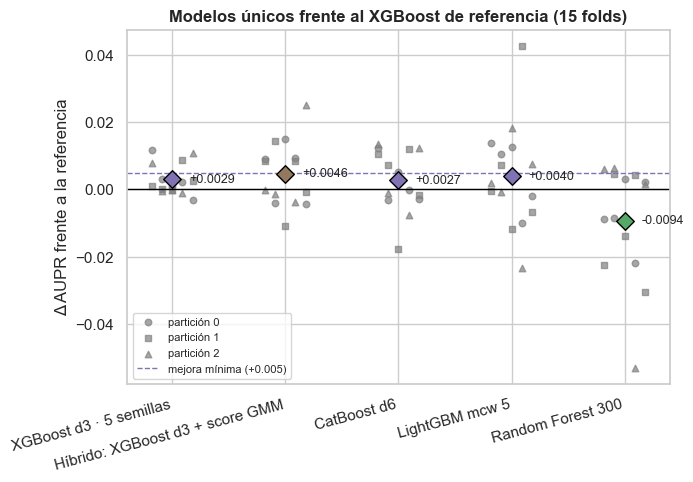

In [65]:
BOLSA_15, CAT_15, LGBM_15, RF_15 = "XGBoost d3 · 5 semillas", "CatBoost d6", "LightGBM mcw 5", "Random Forest 300"
HIB_15 = "Híbrido: XGBoost d3 + score GMM"
MODELOS_B4.update({
    HIB_15: XGBoostConScoreGMM(),
    CAT_15: cb.CatBoostClassifier(iterations=1000, learning_rate=.05, depth=6, random_seed=SEED, verbose=0,
                                  allow_writing_files=False, thread_count=N_JOBS),
    LGBM_15: lgb.LGBMClassifier(min_child_weight=5, verbose=-1, n_jobs=N_JOBS, random_state=SEED),
    RF_15: RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED)})

combinar_15(BOLSA_15, [REF_15, *PLACEBOS_15], "boosting", como="media")
evaluar_15(HIB_15, MODELOS_B4[HIB_15], "híbrido", oof_oficial=OOF[HIB_B4])      # partición 0 = la de §4.1
evaluar_15(CAT_15, MODELOS_B4[CAT_15], "boosting")
evaluar_15(LGBM_15, MODELOS_B4[LGBM_15], "boosting")
evaluar_15(RF_15, MODELOS_B4[RF_15], "bagging")
UNICOS_15 = [BOLSA_15, HIB_15, CAT_15, LGBM_15, RF_15]
display(tabla_15([REF_15, *UNICOS_15]).round(4))
plot_deltas_15(UNICOS_15, "Modelos únicos frente al XGBoost de referencia (15 folds)")
plt.show()

> **Conclusión:** ningún modelo único cumple la regla. Promediar 5 semillas da **0,861** (Δ +0,0029, gana en 10 de 15): reduce la varianza, pero no llega a la mejora mínima. El **híbrido** da **0,863** (Δ +0,0046) y gana solo en **8 de 15** folds: la mejora de la partición oficial (+0,0050) se queda en unos +0,004 en las dos particiones que no se habían mirado. **CatBoost** (0,861, Δ +0,0027) y **LightGBM** (0,862, Δ +0,0040) ganan en 8 de 15 y pierden hasta 0,018 y 0,023 en algún fold. **Random Forest** queda por debajo (0,849, Δ −0,0094, 7 de 15). → **Impacto:** como modelos únicos no sustituyen a la referencia. Pero sus errores no coinciden fold a fold con los del XGBoost, y eso es justo lo que aprovecha una mezcla.

#### ¿Qué es una mezcla por rangos y por qué funciona?

**Mezcla por rangos.** Dentro de cada conjunto que se puntúa (un fold de validación, el test o producción), el score de cada modelo se sustituye por su **posición relativa**: 1 para la transacción más sospechosa, ~0 para la menos sospechosa. La mezcla es la **media de esas posiciones, con pesos iguales**. Por ejemplo, una transacción que XGBoost pone en el puesto 10 de 24.000 (rango 0,9996) y Random Forest en el puesto 2.000 (rango 0,917) queda con 0,958: solo sube a lo más alto si **varios modelos coinciden** en que es sospechosa.

- **Por qué rangos y no probabilidades:** cada modelo tiene su propia escala (Random Forest da muchas probabilidades exactamente 0, CatBoost y XGBoost las concentran de forma distinta). Promediar probabilidades dejaría que dominase el modelo más "extremo". Los rangos ponen a todos en la misma escala, y la AUPR solo depende del orden.
- **Por qué pesos iguales:** ajustar pesos con 206 fraudes sería otra fuente de sobreajuste a estos folds. Sin pesos, la mezcla no tiene ningún parámetro que aprender.
- **Por qué funciona:** los fraudes claros los ponen arriba todos los modelos, y ahí la mezcla no cambia nada. La diferencia está en los casos dudosos: un fraude que un modelo deja en el puesto 2.000 y otro pone en el 100 sube con la media, y una transacción normal que solo a un modelo le parece rara baja. Cuanto **menos se parezcan los rankings** de los modelos (correlación de Spearman entre sus scores), más se cancelan sus errores. Por eso un modelo peor por sí solo, como Random Forest, puede aportar dentro de la mezcla: se equivoca en otras filas.

Primero se mide cuánto se parecen los rankings OOF de la partición oficial. Después se evalúan cuatro mezclas, de dos a cuatro modelos, en los mismos 15 folds.

Mezcla XGB + RF: AUPR 15 folds = 0.8618 ± 0.0683 | partición oficial = 0.8645 (129 s)
Mezcla XGB + CatBoost: AUPR 15 folds = 0.8635 ± 0.0679 | partición oficial = 0.8631 (217 s)


Mezcla XGB + CatBoost + RF: AUPR 15 folds = 0.8654 ± 0.0689 | partición oficial = 0.8677 (334 s)
Mezcla XGB + CatBoost + LightGBM + RF: AUPR 15 folds = 0.8663 ± 0.0689 | partición oficial = 0.8680 (339 s)


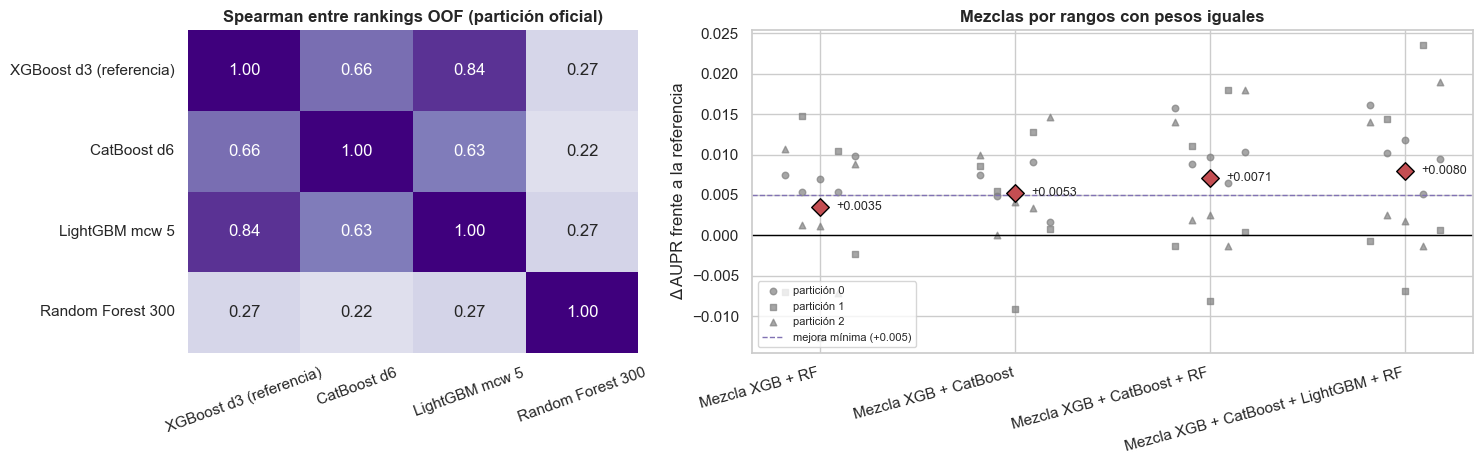

,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
Mezcla XGB + CatBoost + LightGBM + RF,mezcla,0.8663,0.0689,0.8680,0.0080,0.0067,-0.0069,12.0,339.0524
Mezcla XGB + CatBoost + RF,mezcla,0.8654,0.0689,0.8677,0.0071,0.0055,-0.0082,12.0,334.0077
Mezcla XGB + CatBoost,mezcla,0.8635,0.0679,0.8631,0.0053,0.0051,-0.0092,14.0,217.4043
Mezcla XGB + RF,mezcla,0.8618,0.0683,0.8645,0.0035,0.0018,-0.0127,11.0,129.3571
XGBoost d3 (referencia),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,12.7536


In [66]:
BASE_MEZCLA = [REF_15, CAT_15, LGBM_15, RF_15]
RHO_B4 = pd.DataFrame(stats.spearmanr(np.column_stack([OOF_15[n][0] for n in BASE_MEZCLA])).statistic,
                      index=BASE_MEZCLA, columns=BASE_MEZCLA)
MEZCLAS_15 = {"Mezcla XGB + RF": [REF_15, RF_15], "Mezcla XGB + CatBoost": [REF_15, CAT_15],
              "Mezcla XGB + CatBoost + RF": [REF_15, CAT_15, RF_15],
              "Mezcla XGB + CatBoost + LightGBM + RF": [REF_15, CAT_15, LGBM_15, RF_15]}
for n, comp in MEZCLAS_15.items():
    combinar_15(n, comp, "mezcla")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
sns.heatmap(RHO_B4, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=a1, cbar=False)
a1.set_title("Spearman entre rankings OOF (partición oficial)")
a1.tick_params(axis="x", rotation=20)
plot_deltas_15(list(MEZCLAS_15), "Mezclas por rangos con pesos iguales", ax=a2)
fig.tight_layout()
plt.show()
display(tabla_15([REF_15, *MEZCLAS_15]).round(4))

**¿Dónde discrepan XGBoost y Random Forest?** Cada punto es una transacción de train (scores OOF de la partición oficial) situada por su **puesto** en el ranking de cada modelo (1 = la más sospechosa; ejes logarítmicos). Solo se dibujan las que algún modelo pone entre las 3.000 primeras.

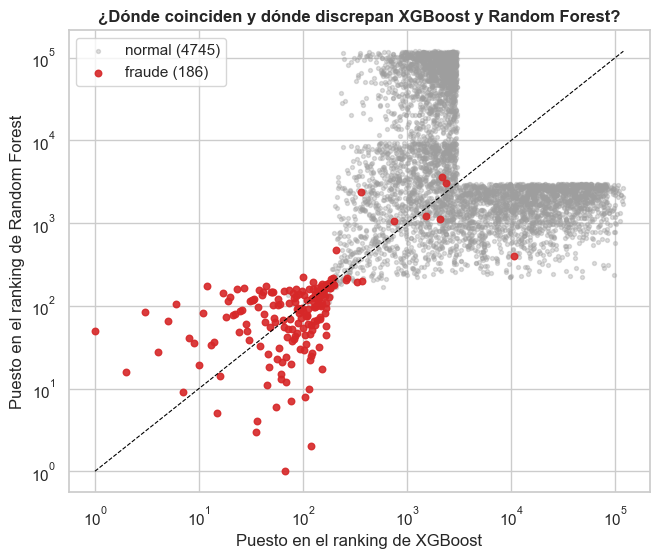

,normal entre las 200 primeras,fraude entre las 200 primeras
XGBoost,26,174
Random Forest,27,173
ambos a la vez,22,171
mezcla de 4,27,173


In [67]:
puesto = lambda s: len(s) - stats.rankdata(s, method="ordinal") + 1        # 1 = más sospechosa
p_xgb, p_rf = puesto(OOF_15[REF_15][0]), puesto(OOF_15[RF_15][0])
p_mez = puesto(OOF_15["Mezcla XGB + CatBoost + LightGBM + RF"][0])
vis = (p_xgb <= 3000) | (p_rf <= 3000)
fig, ax = plt.subplots(figsize=(7.5, 6))
for c in (0, 1):
    k = vis & (ya == c)
    ax.scatter(p_xgb[k], p_rf[k], s=8 if c == 0 else 22, c=C[c], alpha=.35 if c == 0 else .9, label=f"{LBL[c]} ({k.sum()})")
ax.plot([1, 1.2e5], [1, 1.2e5], c="black", lw=.8, ls="--")
ax.set(xscale="log", yscale="log", xlabel="Puesto en el ranking de XGBoost", ylabel="Puesto en el ranking de Random Forest",
       title="¿Dónde coinciden y dónde discrepan XGBoost y Random Forest?")
ax.legend()
plt.show()
TOP_N = 200
CONCUERDAN = pd.DataFrame({m: {LBL[c]: int(((p <= TOP_N) & (ya == c)).sum()) for c in (0, 1)}
                           for m, p in {"XGBoost": p_xgb, "Random Forest": p_rf, "ambos a la vez": np.maximum(p_xgb, p_rf),
                                        "mezcla de 4": p_mez}.items()}).T
CONCUERDAN.columns = [f"{c} entre las {TOP_N} primeras" for c in CONCUERDAN.columns]
CONCUERDAN

> **Conclusión:** los rankings se parecen poco: Spearman 0,84 entre XGBoost y LightGBM, 0,66 con CatBoost y solo 0,27 con Random Forest (sobre todas las filas: casi todo el desacuerdo está entre transacciones normales). En lo más alto de la lista los modelos coinciden: de los 174 fraudes que XGBoost pone entre sus 200 primeras, 171 también están entre las 200 primeras de Random Forest, y comparten 22 de sus 26 falsas alarmas. La ganancia de la mezcla está, por tanto, más abajo, en los fraudes dudosos. Mezclar mejora siempre, y más cuanto más modelos distintos entran: XGB + RF **0,862** (Δ +0,0035, 11 de 15), XGB + CatBoost **0,864** (Δ +0,0053, gana en **14 de 15**), XGB + CatBoost + RF **0,865** (Δ +0,0071, 12 de 15) y los cuatro juntos **0,866 ± 0,069** (Δ **+0,0080**, gana en **12 de 15**, peor fold −0,007). El Random Forest, peor que la referencia por sí solo, sube la mezcla de 0,864 a 0,865. → **Impacto:** las mezclas con CatBoost son las candidatas más fuertes. No se ajusta ningún peso, así que la mejora no viene de adaptar la mezcla a estos folds.

**Qué más probamos (notebook 05).** Se resumen sin re-ejecutar (Optuna no está en el entorno de este notebook y el resto no cambia la decisión). Cifras del 05, en los mismos 15 folds y en este mismo equipo.

| Experimento (05) | Resultado (15 folds) | Conclusión |
|---|---|---|
| Búsqueda de hiperparámetros con Optuna: TPE, 40 pruebas, 9 parámetros (profundidad, ritmo, nº de árboles, `min_child_weight`, `subsample`, `colsample_bytree`, `gamma`, `reg_lambda`, `max_delta_step`), objetivo = AUPR en la partición oficial (05 §3) | Mejor prueba **0,862** en la partición de búsqueda (referencia 0,858), pero **−0,007** en las particiones 1–2 que no vio; 0,855 en los 15 folds (Δ −0,0030, gana en 6 de 15). En test, 0,820 | Sobreajuste a los 5 folds de búsqueda: los hiperparámetros del XGBoost están en una meseta (confirma D-2.5) |
| XGBoost más lento: 1.200 árboles, ritmo 0,02 (05 §2) | **0,864** (Δ +0,0059, gana en 12 de 15, peor fold −0,003). En test, 0,816 | Cumplía la regla, pero con menos Δ que la mezcla de cuatro: no cambia la elección |
| Variables nuevas sin etiquetas: `frec_fila` (copias de la fila entera), `importe_entero`, `importe_99` (05 §5) | 0 fraudes de 275 importes acabados en ,99; XGBoost + 3 variables **0,860** (Δ +0,0020, gana en 9 de 15) | Descartadas: `amount_freq` ya recoge los importes repetidos |
| Mismo XGBoost en otro equipo (04 frente a 05) | 0,865 en el equipo del 04, 0,858 aquí, con la misma configuración y los mismos folds | Diferencia de implementación del orden del ruido de semilla: refuerza la regla de §4.2 |

### 4.4 ¿Qué modelo elegimos antes del test?

**Qué miramos y por qué.** Se aplica la regla de §4.2 tal cual a todos los candidatos re-ejecutados: Δ medio ≥ +0,005, ≥ 11 victorias de 15 y Δ medio por encima del ruido de semilla. La elección queda fijada en `ELEGIDO_B4` **antes** de calcular ningún score de test.

**Comprobación de robustez.** Si la semilla 42 de la referencia hubiera tenido "mala suerte", parte de cada Δ vendría de ahí. Por eso se mide también al elegido frente al **XGBoost con 5 semillas**, que no depende de una semilla concreta. No cambia la regla, pero si el elegido no mejorara también ahí, la elección no sería fiable.

In [68]:
CANDIDATOS_15 = [*UNICOS_15, *MEZCLAS_15]

def cumple_regla_15(n):
    d = delta_15(n)
    return {"Δ medio ≥ 0,005": d.mean() >= MIN_MEJORA_15, "gana ≥ 11 de 15": (d > 0).sum() >= MIN_VICTORIAS_15,
            "supera el ruido de semilla": d.mean() > RUIDO_15}

CV_15 = tabla_15([REF_15, *CANDIDATOS_15])
REGLA_15 = pd.DataFrame({n: cumple_regla_15(n) for n in CANDIDATOS_15}).T
REGLA_15["cumple"] = REGLA_15.all(axis=1)
ELEGIBLES_B4 = REGLA_15.index[REGLA_15["cumple"]].tolist()
ELEGIDO_B4 = max(ELEGIBLES_B4, key=lambda n: delta_15(n).mean()) if ELEGIBLES_B4 else REF_15   # se fija aquí
print(f"Modelo elegido antes del test: {ELEGIDO_B4}")
REGLA_15.join(CV_15[["media 15 folds", "Δ medio", "gana (de 15)", "peor Δ fold"]].round(4)).sort_values("Δ medio", ascending=False)

Modelo elegido antes del test: Mezcla XGB + CatBoost + LightGBM + RF


,"Δ medio ≥ 0,005",gana ≥ 11 de 15,supera el ruido de semilla,cumple,media 15 folds,Δ medio,gana (de 15),peor Δ fold
Mezcla XGB + CatBoost + LightGBM + RF,True,True,True,True,0.8663,0.0080,12.0,-0.0069
Mezcla XGB + CatBoost + RF,True,True,True,True,0.8654,0.0071,12.0,-0.0082
Mezcla XGB + CatBoost,True,True,True,True,0.8635,0.0053,14.0,-0.0092
Híbrido: XGBoost d3 + score GMM,False,False,True,False,0.8629,0.0046,8.0,-0.0109
LightGBM mcw 5,False,False,True,False,0.8622,0.0040,8.0,-0.0233
Mezcla XGB + RF,False,True,True,False,0.8618,0.0035,11.0,-0.0127
XGBoost d3 · 5 semillas,False,False,True,False,0.8612,0.0029,10.0,-0.0032
CatBoost d6,False,False,False,False,0.8610,0.0027,8.0,-0.0176
Random Forest 300,False,False,False,False,0.8489,-0.0094,7.0,-0.0531


,Δ frente a 5 semillas,gana a 5 semillas (de 15),Δ frente a la semilla media,gana a la semilla media (de 15)
Mezcla XGB + CatBoost,0.0023,12.0,0.0044,12.0
Mezcla XGB + CatBoost + RF,0.0041,11.0,0.0062,12.0
Mezcla XGB + CatBoost + LightGBM + RF,0.0050,11.0,0.0071,12.0


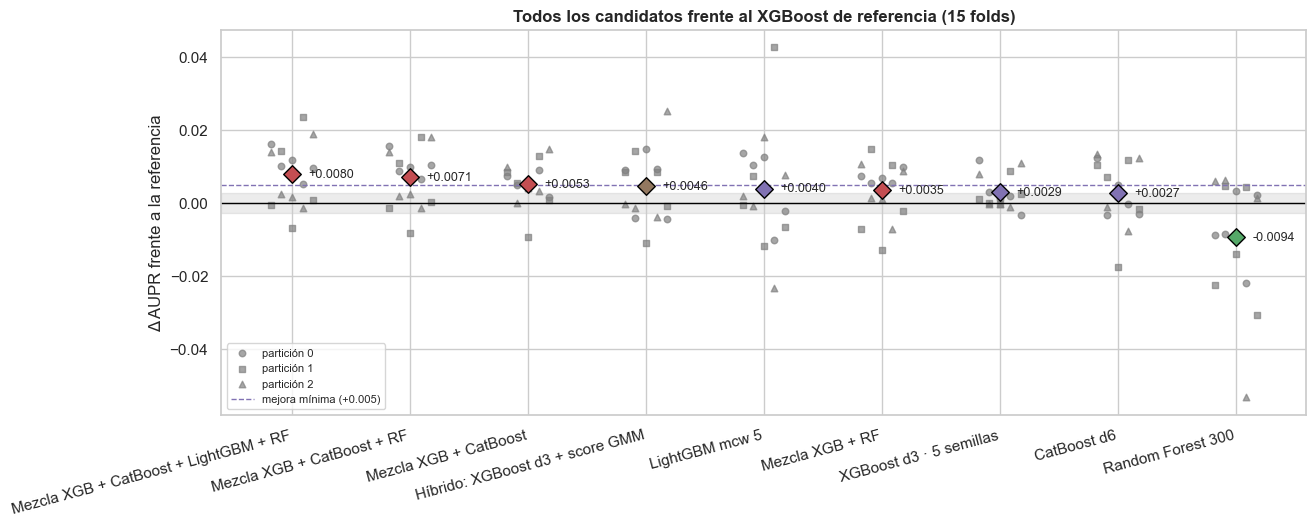

In [69]:
SEMILLA_MEDIA_15 = np.mean([RES_15[n]["a"] for n in [REF_15, *PLACEBOS_15]], axis=0)   # AUPR media de las 5 semillas, fold a fold
ROBUSTEZ_B4 = pd.DataFrame({n: {"Δ frente a 5 semillas": (RES_15[n]["a"] - RES_15[BOLSA_15]["a"]).mean(),
                                "gana a 5 semillas (de 15)": int((RES_15[n]["a"] > RES_15[BOLSA_15]["a"]).sum()),
                                "Δ frente a la semilla media": (RES_15[n]["a"] - SEMILLA_MEDIA_15).mean(),
                                "gana a la semilla media (de 15)": int((RES_15[n]["a"] > SEMILLA_MEDIA_15).sum())}
                            for n in ELEGIBLES_B4 or [REF_15]}).T.astype(float)
display(ROBUSTEZ_B4.round(4))
ax = plot_deltas_15(CV_15.index.drop(REF_15).tolist(), "Todos los candidatos frente al XGBoost de referencia (15 folds)")
ax.axhspan(-RUIDO_15, RUIDO_15, color="grey", alpha=.15, zorder=0, label="ruido de semilla")
ax.figure.set_size_inches(14, 5)
plt.show()

> **Conclusión:** la regla deja **tres elegibles**, todos mezclas: la de cuatro modelos (Δ +0,0080, 12 de 15), la de tres (Δ +0,0071, 12 de 15) y XGB + CatBoost (Δ +0,0053, 14 de 15). El híbrido (Δ +0,0046, solo 8 de 15), LightGBM y el XGBoost con 5 semillas superan el ruido pero no la regla completa. Se elige la de mayor Δ: la **mezcla por rangos de XGBoost, CatBoost, LightGBM y Random Forest**, con **0,866 ± 0,069** en los 15 folds (0,868 en la partición oficial). Supera la comprobación de robustez: frente al XGBoost con 5 semillas mejora **+0,0050** y gana en **11 de 15**; frente a la semilla media, **+0,0071** y 12 de 15. Son exactamente las cifras del 05 (D-2.8). → **Impacto:** la elección queda cerrada antes del test. El coste es entrenar cuatro modelos en lugar de uno (menos de un minuto con toda la construcción).

### 4.5 ¿Se confirma en test?

**Qué miramos y por qué.** Con la elección ya cerrada, cada modelo se ajusta con **todo train** y puntúa el test (51.266 transacciones, 89 fraudes). Las mezclas se calculan con rangos **dentro del test**, igual que dentro de cada fold. Para la diferencia entre el elegido y la referencia se usa un **bootstrap pareado y estratificado** (1.000 réplicas): en cada réplica se remuestrean normales y fraudes por separado y se calculan las dos AUPR **sobre las mismas filas**, de modo que el intervalo mide la incertidumbre de la diferencia, no la de cada AUPR.

El test ya se miró en los bloques anteriores: es una confirmación interna y **no cambia la elección**.

In [70]:
COMPONENTES_B4 = {BOLSA_15: ("media", [REF_15, *PLACEBOS_15]), **{n: ("rango", comp) for n, comp in MEZCLAS_15.items()}}

def predecir_b4(nombre, X_ajuste, y_ajuste, X_destino, cache):
    """Score de X_destino: modelo simple ajustado con (X_ajuste, y_ajuste), o combinación de sus componentes
    (media de probabilidades o media de rangos dentro de X_destino). cache evita reajustar componentes."""
    if nombre in MODELOS_B4:
        if nombre not in cache:
            cache[nombre] = score(fit(MODELOS_B4[nombre], X_ajuste, y_ajuste), X_destino)
        return cache[nombre]
    como, comp = COMPONENTES_B4[nombre]
    ss = [predecir_b4(c, X_ajuste, y_ajuste, X_destino, cache) for c in comp]
    return np.mean([rango_01(s) for s in ss] if como == "rango" else ss, axis=0)

t0, CACHE_TEST_B4 = time.time(), {}
X_te_np = X_test.to_numpy(float)
SC_TEST_B4 = {n: predecir_b4(n, Xa, ya, X_te_np, CACHE_TEST_B4) for n in [REF_15, *CANDIDATOS_15]}
with contextlib.redirect_stdout(io.StringIO()):
    TEST_B4 = pd.DataFrame([report(n, s) for n, s in SC_TEST_B4.items()]).set_index("modelo")
TEST_B4.insert(0, "CV 15 folds", [RES_15[n]["a"].mean() for n in TEST_B4.index])
TEST_B4["Δ test frente a la referencia"] = TEST_B4["aupr"] - TEST_B4.loc[REF_15, "aupr"]
print(f"Ajuste con todo train y puntuación del test: {time.time() - t0:.0f} s. Elección mantenida: {ELEGIDO_B4}")
TEST_B4.sort_values("CV 15 folds", ascending=False).round(4)

Ajuste con todo train y puntuación del test: 38 s. Elección mantenida: Mezcla XGB + CatBoost + LightGBM + RF


,CV 15 folds,aupr,roc_auc,aupr_sin_dup,Δ test frente a la referencia
modelo,,,,,
Mezcla XGB + CatBoost + LightGBM + RF,0.8663,0.8217,0.9743,0.8091,0.0049
Mezcla XGB + CatBoost + RF,0.8654,0.8161,0.9766,0.8020,-0.0007
Mezcla XGB + CatBoost,0.8635,0.8183,0.9764,0.8061,0.0015
Híbrido: XGBoost d3 + score GMM,0.8629,0.8126,0.9689,0.7992,-0.0042
LightGBM mcw 5,0.8622,0.8142,0.9648,0.8001,-0.0026
Mezcla XGB + RF,0.8618,0.8114,0.9734,0.7973,-0.0054
XGBoost d3 · 5 semillas,0.8612,0.8160,0.9766,0.8029,-0.0008
CatBoost d6,0.8610,0.8125,0.9732,0.7996,-0.0043
XGBoost d3 (referencia),0.8583,0.8168,0.9743,0.8040,0.0000


,AUPR test,AUPR test sin duplicados,IC 95 % AUPR
XGBoost d3 (referencia),0.8168,0.8040,0.735 – 0.887
Mezcla XGB + CatBoost + LightGBM + RF,0.8217,0.8091,0.740 – 0.892


Δ test = +0.0049 | IC 95 % bootstrap pareado del Δ: -0.0108 a +0.0211 | réplicas con Δ > 0: 75 %


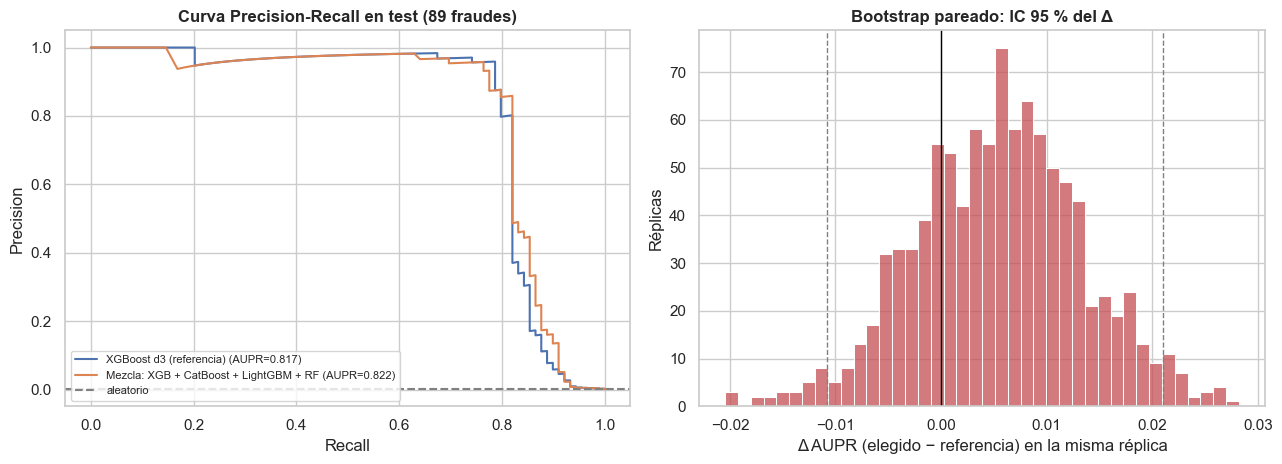

In [71]:
rng_b4 = np.random.default_rng(SEED)
i0, i1 = np.flatnonzero(y_te == 0), np.flatnonzero(y_te == 1)
BOOT_B4 = np.empty((1000, 2))
for b in range(len(BOOT_B4)):
    ib = np.r_[rng_b4.choice(i0, len(i0)), rng_b4.choice(i1, len(i1))]     # estratificado: siempre 89 fraudes
    BOOT_B4[b] = [average_precision_score(y_te[ib], SC_TEST_B4[n][ib]) for n in (REF_15, ELEGIDO_B4)]
DELTA_BOOT_B4 = BOOT_B4[:, 1] - BOOT_B4[:, 0]
IC_B4 = np.quantile(DELTA_BOOT_B4, [.025, .975])
CONFIRMACION_B4 = pd.DataFrame({
    "AUPR test": [TEST_B4.loc[REF_15, "aupr"], TEST_B4.loc[ELEGIDO_B4, "aupr"]],
    "AUPR test sin duplicados": [TEST_B4.loc[REF_15, "aupr_sin_dup"], TEST_B4.loc[ELEGIDO_B4, "aupr_sin_dup"]],
    "IC 95 % AUPR": [f"{np.quantile(BOOT_B4[:, j], .025):.3f} – {np.quantile(BOOT_B4[:, j], .975):.3f}" for j in (0, 1)]},
    index=[REF_15, ELEGIDO_B4])
display(CONFIRMACION_B4.round(4))
print(f"Δ test = {TEST_B4.loc[ELEGIDO_B4, 'aupr'] - TEST_B4.loc[REF_15, 'aupr']:+.4f} | IC 95 % bootstrap pareado del Δ: "
      f"{IC_B4[0]:+.4f} a {IC_B4[1]:+.4f} | réplicas con Δ > 0: {100 * (DELTA_BOOT_B4 > 0).mean():.0f} %")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
plot_pr(y_te, {"XGBoost d3 (referencia)": SC_TEST_B4[REF_15], ELEGIDO_B4.replace("Mezcla ", "Mezcla: "): SC_TEST_B4[ELEGIDO_B4]}, ax=a1)
a1.set_title(f"Curva Precision-Recall en test ({y_te.sum()} fraudes)")
a1.legend(fontsize=8, loc="lower left")
sns.histplot(DELTA_BOOT_B4, bins=40, color=FAM["mezcla"], ax=a2)
a2.axvline(0, c="black", lw=1)
for q in IC_B4:
    a2.axvline(q, c="grey", ls="--", lw=1)
a2.set(xlabel="Δ AUPR (elegido − referencia) en la misma réplica", ylabel="Réplicas", title="Bootstrap pareado: IC 95 % del Δ")
fig.tight_layout()
plt.show()

> **Conclusión:** la mezcla elegida obtiene **0,822** en test frente a **0,817** de la referencia (Δ **+0,0049**; IC 95 % del Δ **−0,011 a +0,021**; el Δ es positivo en el 75 % de las réplicas), y **0,809** sin las filas duplicadas de train frente a 0,804. Es la cifra de test más alta de los candidatos. El intervalo incluye el 0: con 89 fraudes, el test no puede confirmar una mejora de esta escala, pero va en la misma dirección que la CV. El test también muestra su ruido: XGB + CatBoost + RF, segunda en CV, da 0,816, por debajo de la referencia. Solo Random Forest queda claramente por debajo (0,793, Δ −0,024). → **Impacto:** se mantiene la elección hecha en CV. Como en los bloques anteriores, el test queda unas centésimas por debajo de la CV.

### 4.6 Conclusiones del bloque

1. **Los scores no supervisados no entran en el modelo.** Calculado sin fuga, el GMM del eje menor mejora algo la media del XGBoost en los 5 folds oficiales (0,863 frente a 0,858), pero gana solo en 3 de 5, y con 15 folds se queda en Δ +0,005 con solo 8 victorias de 15, y en el 04 (otro equipo) daba −0,0007. Los cinco scores juntos y la prioridad de variables del 04 tampoco justificaban un híbrido (D-2.7).
2. **El ruido manda a esta escala.** Cambiar la semilla mueve la AUPR de un fold hasta ±0,018 y la media hasta 0,0027; el mismo XGBoost da 0,865 o 0,858 según el equipo. Por eso: 15 folds, placebo de semillas y regla fijada antes de ver los candidatos (Δ ≥ +0,005, ≥ 11 de 15, por encima del ruido).
3. **Ningún modelo único bate al XGBoost de forma consistente**, ni ajustando hiperparámetros (Optuna: +0,004 donde busca, −0,007 donde no mira).
4. **Mezclar modelos distintos sí mejora, poco pero de forma consistente.** La mezcla por rangos con pesos iguales de XGBoost, CatBoost, LightGBM y Random Forest da **0,866 ± 0,069** en CV (Δ **+0,008**, gana en 12 de 15; +0,005 frente al XGBoost con 5 semillas). Funciona porque sus rankings se parecen poco (Spearman de 0,27 a 0,84) y no tiene ningún peso que sobreajustar.
5. **El test va en la misma dirección sin poder confirmarlo:** **0,822** frente a 0,817 (IC del Δ −0,011 a +0,021). La elección se hizo antes de mirarlo y no cambia.

**Pasa al bloque 5:** el modelo elegido (`ELEGIDO_B4`), que se reajusta con toda la construcción para puntuar producción.

In [72]:
print(f"Bloque 4 ejecutado en {(time.time() - T0_BLOQUE4) / 60:.1f} min")

Bloque 4 ejecutado en 10.1 min


## 5. Generación del fichero de producción

**Qué hacemos y por qué.** El modelo elegido en §4.4 se **reajusta con toda la construcción** (train + test: 170.884 transacciones, 295 fraudes). Una vez cerrada la elección, el test ya no hace falta para medir, y sus 89 fraudes son un 43 % más de ejemplos de fraude para aprender. Con la configuración congelada, más datos solo pueden ayudar.

Si el elegido es la mezcla, cada uno de sus cuatro modelos se reajusta por separado, puntúa las 113.923 transacciones de producción, cada score se convierte en su **rango dentro de producción** y se promedian los rangos con pesos iguales: exactamente el mismo procedimiento que en cada fold de validación y en el test. El resultado se guarda con `save_submission()`: una sola columna sin cabecera, una fila por transacción, en el orden original de producción (D-3.1). Mayor score = más sospechosa.

### 5.1 ¿Cómo se genera el entregable?

In [73]:
t0 = time.time()
X_cons_b5 = df_const[FEATURES].to_numpy(float)
y_cons_b5 = df_const["Class"].astype(int).to_numpy()
X_prod_b5 = X_prod.to_numpy(float)
CACHE_PROD_B5 = {}
SCORE_FINAL_B5 = predecir_b4(ELEGIDO_B4, X_cons_b5, y_cons_b5, X_prod_b5, CACHE_PROD_B5)   # reajusta cada componente
miles = lambda n: f"{n:,}".replace(",", ".")
print(f"Modelo final: {ELEGIDO_B4}\nReajuste con {miles(len(y_cons_b5))} transacciones y {y_cons_b5.sum()} fraudes; "
      f"componentes: {list(CACHE_PROD_B5)} ({time.time() - t0:.0f} s)")
pd.DataFrame({n: pd.Series(s).describe() for n, s in {**CACHE_PROD_B5, "score final": SCORE_FINAL_B5}.items()}).T.round(4)

Modelo final: Mezcla XGB + CatBoost + LightGBM + RF
Reajuste con 170.884 transacciones y 295 fraudes; componentes: ['XGBoost d3 (referencia)', 'CatBoost d6', 'LightGBM mcw 5', 'Random Forest 300'] (42 s)


,count,mean,std,min,25%,50%,75%,max
XGBoost d3 (referencia),113923.0,0.0016,0.0355,0.0000,0.0000,0.00,0.0001,0.9985
CatBoost d6,113923.0,0.0015,0.0364,0.0000,0.0000,0.00,0.0001,0.9999
LightGBM mcw 5,113923.0,0.0016,0.0357,0.0000,0.0000,0.00,0.0001,0.9985
Random Forest 300,113923.0,0.0017,0.0329,0.0000,0.0000,0.00,0.0000,0.9977
score final,113923.0,0.5000,0.2118,0.1147,0.3263,0.49,0.6636,1.0000


### 5.2 ¿Cambia respecto al entregable anterior y tiene el formato correcto?

**Qué miramos y por qué.** Si ya existe un `scores_produccion.csv` en la carpeta de salida (por ejemplo, el que generó el notebook 05 de trabajo), antes de sobrescribirlo se compara con el nuevo: correlación de Spearman entre rankings, máxima diferencia absoluta y qué parte del 1 % más sospechoso comparten. Después se guarda, se vuelve a leer del disco y se comprueba el formato.

In [74]:
RUTA_ENTREGA = OUTPUT_DIR / "scores_produccion.csv"
top1_prod = lambda s: set(np.argsort(-np.asarray(s), kind="stable")[:len(s) // 100])
if RUTA_ENTREGA.exists():
    # el previo puede tener cabecera (versiones anteriores): se descarta cualquier línea no numérica
    previo_b5 = pd.to_numeric(pd.read_csv(RUTA_ENTREGA, header=None)[0], errors="coerce").dropna().to_numpy(float)
    assert len(previo_b5) == len(SCORE_FINAL_B5)
    COMPARA_B5 = pd.Series({"Spearman con el entregable previo": stats.spearmanr(SCORE_FINAL_B5, previo_b5).statistic,
                            "máxima diferencia absoluta": np.abs(SCORE_FINAL_B5 - previo_b5).max(),
                            "diferencia absoluta media": np.abs(SCORE_FINAL_B5 - previo_b5).mean(),
                            "1 % superior compartido (%)": 100 * len(top1_prod(SCORE_FINAL_B5) & top1_prod(previo_b5)) / (len(previo_b5) // 100)},
                           name="nuevo frente al previo")
    display(COMPARA_B5.round(6).to_frame())
else:
    print(f"No hay un entregable previo en {OUTPUT_DIR}: se genera por primera vez.")

save_submission(SCORE_FINAL_B5)       # → OUTPUT_DIR / "scores_produccion.csv"
print(f"Guardado: {RUTA_ENTREGA}")

,nuevo frente al previo
Spearman con el entregable previo,1.000000
máxima diferencia absoluta,0.000081
diferencia absoluta media,0.000000
1 % superior compartido (%),100.000000


Guardado: C:\Users\Usuario\AppData\Local\Temp\claude\C--Users-Usuario-MisDocumentos-02-ACADEMICO-MIAX-MASTER-TAREAS-Y-ENTREGAS-fraud-detection-banking\240517cb-f438-4ddf-a786-d5dc733e6de3\scratchpad\nb99\final2\data\output\scores_produccion.csv


In [75]:
# Verificación del fichero tal como queda en disco
primera_linea = RUTA_ENTREGA.read_text().splitlines()[0]
float(primera_linea)                                                                   # sin cabecera: la primera línea ya es un score
sub_b5 = pd.read_csv(RUTA_ENTREGA, header=None, names=["score"])
assert sub_b5.shape == (113_923, 1)
assert np.isfinite(sub_b5["score"]).all()
assert np.allclose(sub_b5["score"].to_numpy(), SCORE_FINAL_B5)                       # mismo orden que producción
assert len(sub_b5) == len(raw_prod) and (df_prod["row_id"].to_numpy() == np.arange(len(sub_b5))).all()
pd.Series({"filas": len(sub_b5), "columnas": sub_b5.shape[1], "cabecera": "ninguna", "primera línea": primera_linea, "valores finitos": bool(np.isfinite(sub_b5.score).all()),
           "mínimo": sub_b5.score.min(), "máximo": sub_b5.score.max(), "valores distintos": sub_b5.score.nunique()},
          name="scores_produccion.csv").to_frame()

,scores_produccion.csv
filas,113923
columnas,1
cabecera,ninguna
primera línea,0.6292846922921622
valores finitos,True
mínimo,0.11471
máximo,0.999963
valores distintos,100470


### 5.3 ¿Quedan arriba las copias exactas de fraudes conocidos?

**Qué miramos y por qué.** Hay transacciones de producción idénticas, en sus 21 variables, a fraudes etiquetados de construcción (D-1.1). Son el caso más claro posible: si alguna no saliera arriba del ranking, convendría una regla explícita (marcarla como fraude). Primero se comprueba en test, con las copias de fraudes de train y el modelo ajustado solo con train (§4.5); después en producción, con el entregable.

In [76]:
clave_c = pd.util.hash_pandas_object(raw_const[FEAT_RAW], index=False).to_numpy()
clave_p = pd.util.hash_pandas_object(raw_prod[FEAT_RAW], index=False).to_numpy()
fraude_train_b5 = np.unique(clave_c[tr.index][ya == 1])
fraude_cons_b5 = np.unique(clave_c[y_cons_b5 == 1])
copia_te = np.isin(clave_c[te.index], fraude_train_b5)
copia_pr = np.isin(clave_p, fraude_cons_b5)
pct_te, pct_pr = 100 * rango_01(SC_TEST_B4[ELEGIDO_B4]), 100 * rango_01(SCORE_FINAL_B5)
COPIAS_B5 = pd.DataFrame({
    "copias de un fraude conocido": [int(copia_te.sum()), int(copia_pr.sum())],
    "de ellas fraude": [int(y_te[copia_te].sum()), "sin etiqueta"],
    "percentil mínimo del score": [pct_te[copia_te].min() if copia_te.any() else np.nan, pct_pr[copia_pr].min() if copia_pr.any() else np.nan],
    "peor puesto en el ranking": [f"{int(len(pct_te) - stats.rankdata(SC_TEST_B4[ELEGIDO_B4], method='min')[copia_te].min() + 1)} de {miles(len(pct_te))}",
                                  f"{int(len(pct_pr) - stats.rankdata(SCORE_FINAL_B5, method='min')[copia_pr].min() + 1)} de {miles(len(pct_pr))}"]},
    index=["test (copias de fraudes de train)", "producción (copias de fraudes de construcción)"])
COPIAS_B5

,copias de un fraude conocido,de ellas fraude,percentil mínimo del score,peor puesto en el ranking
test (copias de fraudes de train),5,5,99.949284,27 de 51.266
producción (copias de fraudes de construcción),6,sin etiqueta,99.977178,27 de 113.923


> **Conclusión:** en test hay **5 filas idénticas a fraudes de train** y las 5 son fraude: la mezcla, ajustada solo con train, las sitúa en el **0,05 % superior** del ranking (la peor, en el puesto 27 de 51.266). En producción hay **6 copias exactas de fraudes de construcción**, y el entregable las coloca todas en el **0,03 % superior** (la peor, en el puesto 27 de 113.923). → **Impacto:** no hace falta ninguna regla explícita: el modelo ya pone arriba las copias de fraudes conocidos.

### 5.4 Conclusiones del bloque

1. **Entregable generado:** `scores_produccion.csv`, **113.923 filas y una sola columna, sin cabecera**, valores finitos entre 0,115 y 1, en el orden original de producción. Es la mezcla por rangos de los cuatro modelos reajustados con **170.884 transacciones y 295 fraudes** (unos 40 s).
2. **Reproduce el entregable de los notebooks de trabajo:** frente al `scores_produccion.csv` del 05, Spearman **1,000**, diferencia máxima **0,00008** y **100 %** del 1 % superior compartido. Aunque aquí se parte de los CSV originales y no del dataset exportado por el 01, el ranking es el mismo.
3. **Las copias exactas de fraudes conocidos quedan arriba** (las 6 de producción en el 0,03 % superior), sin reglas añadidas.
4. **Los scores son rangos, no probabilidades:** sirven para ordenar (AUPR), no como probabilidad calibrada de fraude.

**Pasa al bloque 6:** el entregable `scores_produccion.csv` y las cifras de CV y test del modelo final, para la reflexión sobre qué esperar en producción.

In [77]:
print(f"Bloques 4 y 5 ejecutados en {(time.time() - T0_BLOQUE4) / 60:.1f} min")

Bloques 4 y 5 ejecutados en 10.9 min


---
## 6. Reflexión final sobre los resultados

### 6.1 El recorrido en una tabla

| Etapa | Mejor modelo | AUPR CV | AUPR test | Qué aprendimos |
|---|---|---|---|---|
| Partida del profesor | GMM 5 componentes | 0,533 | 0,567 / 0,495* | Un modelo de densidad sobre todas las variables ve los fraudes, pero mezclados con muchas normales raras. |
| No supervisado (bloque 2) | GMM 5 sobre el eje menor | 0,779 | 0,736 | La señal vive en la dirección de varianza mínima de los normales: **la representación importa más que el detector**. |
| Supervisado (bloque 3) | XGBoost d3 | 0,858 | 0,817 | Con 295 etiquetas, un clasificador no lineal recupera fraudes que ninguna medida de rareza ve. No hace falta reequilibrar. |
| Híbrido (bloque 4) | XGBoost + score del GMM eje | 0,863 | 0,813 | Lo que ven los detectores de rareza ya lo ve casi todo el XGBoost: la pequeña mejora media no se repite fold a fold (3 de 5; 8 de 15). |
| Modelo final (bloques 4–5) | Mezcla por rangos de 4 modelos | **0,866** | **0,822** | Modelos distintos se equivocan en sitios distintos: promediar sus rankings mejora poco, pero de forma consistente. |

\* 0,567 con el orden de filas del notebook de partida; 0,495 con el orden por `row_id` (la inicialización por k-means del GMM depende del orden).

### 6.2 Qué ha funcionado y por qué

- **Entender los datos antes de modelar.** El EDA encontró las tres pistas que guían todo el trabajo: el fraude es una cola **correlada** en unas pocas variables (X17, X14, X12, X10), los importes exactos se repiten (1,50 = 24 % de los fraudes) y hay duplicados que había que tratar para no hacer trampas en la validación.
- **Una validación honesta y común.** Folds por grupos de duplicados, el mismo split en todos los notebooks y el test reservado para confirmar. Sin eso, las diferencias de milésimas que separan a los últimos modelos serían ruido.
- **Usar las etiquetas.** El profesor recomendó usar las anomalías etiquetadas sobre todo para validar cuando son muy pocas. Aquí, con 295, lo comparamos empíricamente: el supervisado gana al mejor no supervisado en los cinco folds y en test (+0,08). Lo que decide es el **tipo de anomalía**: parte de los fraudes no son raros respecto a lo normal, solo se parecen a otros fraudes.
- **Desconfiar de las mejoras pequeñas.** El placebo de semillas mostró que cambiar solo la semilla mueve la AUPR de un fold casi ±0,02; la búsqueda de hiperparámetros con Optuna "mejoraba" en los folds donde buscaba y empeoraba en los demás. Fijar la regla antes de mirar evitó quedarnos con un ganador falso.

### 6.3 Qué no ha funcionado

- **Reequilibrar las clases** (pesos, SMOTE, undersampling): la AUPR solo mide el orden y el desbalanceo no la perjudica; reequilibrar la empeoraba.
- **Los métodos de vecindad con toda la referencia** (LOF, kNN): con 120.000 normales el vecindario es demasiado pequeño en proporción; solo funcionan con una referencia submuestreada.
- **El híbrido** (scores de anomalía como variables del XGBoost): los cinco detectores del bloque 2 no añaden información que el XGBoost no tenga.
- **Afinar el XGBoost** (hiperparámetros, prioridad de variables, más variables de importe): está en una meseta; todas las variantes quedan dentro del ruido.

### 6.4 Qué esperar en producción

- **AUPR esperada: en torno a 0,82–0,87.** La CV (0,866) y el test (0,822) son las dos estimaciones disponibles; el test, con solo 89 fraudes, tiene un intervalo de confianza del 95 % de unas ±0,08. En todos los notebooks el test ha quedado unas centésimas por debajo de la CV.
- **No hay data shift** entre construcción y producción (KS ≤ 0,005 en todas las variables y AUC de validación adversarial ≈ 0,5), así que estas estimaciones deberían trasladarse. Aun así, como dijo el profesor, "siempre se suele acertar mirando para atrás, pero nunca mirando para delante": en un despliegue real habría que vigilar la AUPR con etiquetas nuevas y reentrenar cuando el fraude cambie.
- **Limitaciones.** La mejora de la mezcla frente al XGBoost (≈ +0,008) es menor que la incertidumbre del test. El test se ha mirado en varios bloques, así que no es una evaluación externa intacta. `amount_freq` se calcula con construcción + producción juntas (sin etiquetas): en un despliegue real habría que recalcularla con el lote que se puntúa. Los scores de la mezcla son rangos, no probabilidades calibradas: sirven para ordenar (AUPR), no para fijar por sí solos un umbral de alerta.

### 6.5 Si tuviéramos más tiempo

- Más fraudes etiquetados valdrían más que cualquier modelo: con 295 la CV oscila ±0,06 entre folds.
- Elegir el **umbral de alerta** según el coste de revisar una transacción frente al de dejar pasar un fraude: con ~1 % de falsas alarmas se detecta en torno al 89 % de los fraudes de validación.
- Explicar cada alerta (variables que más la empujan) para el equipo que revisa los casos.